<a href="https://colab.research.google.com/github/shakirullah-khan/groundwater-recharge-potential-ahp-gee/blob/main/notebooks/01_swat_district_gwrp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Multi-Criteria Groundwater Recharge Potential Assessment Swat District**

**Developed under UNICEF Drinking Water Sustainability Framework | NIUIP**

**Author: Shakir Ullah Khan (Assistant Engineer, NIUIP)**

**Methodology:** Analytical Hierarchy Process (AHP), Satellite Multi-Spectral Indices, and Google Earth Engine (GEE)

**Academic & Reproducibility Notice**

 **Execution Environment:** This notebook was executed in Google Colab with authenticated access to the Google Earth Engine API.

 **Preserved Outputs:** All cell outputs, intermediate thematic layers, AHP matrix calculations ($CR < 0.10$), and final recharge zone delineations are permanently preserved below.

 **Data Sources:** Multi-spectral indices (NDVI, NDBI, WVWI, MSI, LST) were extracted via Sentinel-2 and Landsat-8/9 collections; topographical parameters via SRTM 30 m DEM; hydrological layers via in-situ water table monitoring and stream networks.

In [ ]:
# ============================================================
# STEP 1A: Environment Setup & Google Drive Connection
# ============================================================

import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

pip_install("geemap")
pip_install("geopandas")

import os
import geopandas as gpd
import ee
import geemap
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Mount Google Drive ───────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# ── Project Configuration ────────────────────────────────────
BASE_DIR    = "/content/drive/MyDrive/Swat_Groundwater_Project"
DISTRICT    = "Charsadda"
GEE_PROJECT = "ee-shakirlki3132"

# ── Create folder structure ──────────────────────────────────
subdirs = ["Shapefile", "Data", "Thematic_Maps", "Outputs"]
for sub in subdirs:
    path = os.path.join(BASE_DIR, sub)
    os.makedirs(path, exist_ok=True)
    print(f"  ✔  {path}")

print("\n✅ Directory structure ready.")

# ── GEE Authentication ───────────────────────────────────────
try:
    ee.Initialize(project=GEE_PROJECT)
    print("✅ GEE already authenticated.")
except Exception:
    ee.Authenticate()
    ee.Initialize(project=GEE_PROJECT)
    print("✅ GEE authenticated and initialized.")

print(f"""
╔══════════════════════════════════════════════════════╗
║           NEXT STEP — ACTION REQUIRED                ║
╠══════════════════════════════════════════════════════╣
║  Upload your Charsadda District shapefile to:        ║
║                                                      ║
║  📁 MyDrive/Charsadda_Groundwater_Project/Shapefile/ ║
║                                                      ║
║  Required files (all 4 must be uploaded):            ║
║    ✔ Swat.shp   (geometry)                      ║
║    ✔ Swat.shx   (index)                         ║
║    ✔ Swat.dbf   (attributes)                    ║
║    ✔ Swat.prj   (projection)                    ║
║                                                      ║
║  After uploading → Run Step 1B                       ║
╚══════════════════════════════════════════════════════╝
""")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  ✔  /content/drive/MyDrive/Swat_Groundwater_Project/Shapefile
  ✔  /content/drive/MyDrive/Swat_Groundwater_Project/Data
  ✔  /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps
  ✔  /content/drive/MyDrive/Swat_Groundwater_Project/Outputs

✅ Directory structure ready.
✅ GEE authenticated and initialized.

╔══════════════════════════════════════════════════════╗
║           NEXT STEP — ACTION REQUIRED                ║
╠══════════════════════════════════════════════════════╣
║  Upload your Charsadda District shapefile to:        ║
║                                                      ║
║  📁 MyDrive/Charsadda_Groundwater_Project/Shapefile/ ║
║                                                      ║
║  Required files (all 4 must be uploaded):            ║
║    ✔ Swat.shp   (geometry)                      ║
║    ✔ Swat.shx   (index)                      

📐 Original CRS   : EPSG:4326
📐 Reprojected CRS: EPSG:32643
📏 Total area     : 5371.75 km²
📦 Bounding box   :
   X: 233493 – 301222 m  (W–E extent: 67730 m)
   Y: 3828559 – 3975571 m  (S–N extent: 147012 m)
✅ GEE ROI created: <class 'ee.geometry.Geometry'>


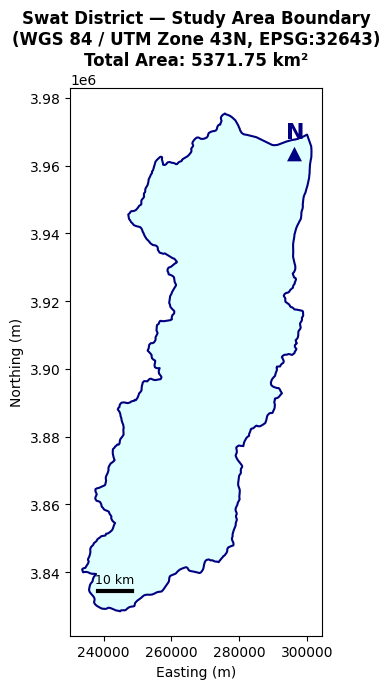

  💾 PNG: /content/drive/MyDrive/Swat_Groundwater_Project/Outputs/Step1_Boundary.png
  💾 PDF: /content/drive/MyDrive/Swat_Groundwater_Project/Outputs/Step1_Boundary.pdf

  STEP 1B — VERIFICATION BLOCK
  Shapefile        : Swat.shp
  Original CRS     : EPSG:4326
  Reprojected CRS  : EPSG:32643
  Total area       : 5371.75 km²
  Features count   : 1
  Geometry types   : ['Polygon']
  Bounding box     :
    X: 233493 – 301222 m
    Y: 3828559 – 3975571 m
  GEE ROI type     : <class 'ee.geometry.Geometry'>
✅ Step 1B complete. Proceed to Step 2.


In [ ]:
# ============================================================
# STEP 1B: Shapefile Ingestion, Validation & Boundary Map
# ============================================================

import os
import geopandas as gpd
import ee
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
SHP_NAME   = "Swat.shp"
SHP_PATH   = os.path.join(BASE_DIR, "Shapefile", SHP_NAME)
TARGET_CRS = "EPSG:32643"   # WGS 84 / UTM Zone 43N

if not os.path.exists(SHP_PATH):
    raise FileNotFoundError(
        f"\n❌ Shapefile not found at:\n   {SHP_PATH}\n"
        f"Please upload your shapefile to:\n"
        f"   {BASE_DIR}/Shapefile/"
    )

# ── Load & reproject ────────────────────────────────────────
gdf_raw = gpd.read_file(SHP_PATH)
print(f"📐 Original CRS   : {gdf_raw.crs}")

if gdf_raw.crs is None:
    gdf_raw = gdf_raw.set_crs("EPSG:4326")
    print("⚠️  No CRS detected — assigned EPSG:4326")

gdf = gdf_raw.to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
print(f"📐 Reprojected CRS: {gdf.crs}")

# ── Area & geometry stats ────────────────────────────────────
gdf["area_km2"] = gdf.geometry.area / 1e6
total_area      = gdf["area_km2"].sum()
x_min, y_min, x_max, y_max = gdf.total_bounds
print(f"📏 Total area     : {total_area:.2f} km²")
print(f"📦 Bounding box   :")
print(f"   X: {x_min:.0f} – {x_max:.0f} m  (W–E extent: {x_max-x_min:.0f} m)")
print(f"   Y: {y_min:.0f} – {y_max:.0f} m  (S–N extent: {y_max-y_min:.0f} m)")

# ── GEE ROI ─────────────────────────────────────────────────
gdf_4326  = gdf.to_crs("EPSG:4326")
roi_geo   = gdf_4326.dissolve().geometry.iloc[0].__geo_interface__
roi       = ee.Geometry(roi_geo)
print(f"✅ GEE ROI created: {type(roi)}")

# ── Boundary map ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 7))
gdf.plot(ax=ax, facecolor="lightcyan", edgecolor="navy", linewidth=1.5)
ax.set_title(f"Swat District — Study Area Boundary\n"
             f"(WGS 84 / UTM Zone 43N, EPSG:32643)\n"
             f"Total Area: {total_area:.2f} km²",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

ax.annotate("N", xy=(x_max-(x_max-x_min)*0.07, y_max-(y_max-y_min)*0.05),
            fontsize=16, fontweight="bold", ha="center", color="navy")
ax.annotate("▲", xy=(x_max-(x_max-x_min)*0.07, y_max-(y_max-y_min)*0.09),
            fontsize=14, ha="center", color="navy")

bar_len = 10000
bar_x0  = x_min + (x_max-x_min)*0.07
bar_y0  = y_min + (y_max-y_min)*0.04
ax.plot([bar_x0, bar_x0+bar_len], [bar_y0, bar_y0], color="black", linewidth=3)
ax.text(bar_x0+bar_len/2, bar_y0+(y_max-y_min)*0.015,
        "10 km", ha="center", fontsize=9)

plt.tight_layout()
png_path = os.path.join(BASE_DIR, "Outputs", "Step1_Boundary.png")
pdf_path = os.path.join(BASE_DIR, "Outputs", "Step1_Boundary.pdf")
plt.savefig(png_path, dpi=150, bbox_inches="tight")
fig.savefig(pdf_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"  💾 PNG: {png_path}")
print(f"  💾 PDF: {pdf_path}")

# ── Verification Block ───────────────────────────────────────
print("\n" + "="*55)
print("  STEP 1B — VERIFICATION BLOCK")
print("="*55)
print(f"  Shapefile        : {SHP_NAME}")
print(f"  Original CRS     : {gdf_raw.crs}")
print(f"  Reprojected CRS  : {gdf.crs}")
print(f"  Total area       : {total_area:.2f} km²")
print(f"  Features count   : {len(gdf)}")
print(f"  Geometry types   : {gdf.geom_type.unique().tolist()}")
print(f"  Bounding box     :")
print(f"    X: {x_min:.0f} – {x_max:.0f} m")
print(f"    Y: {y_min:.0f} – {y_max:.0f} m")
print(f"  GEE ROI type     : {type(roi)}")
print("="*55)
print("✅ Step 1B complete. Proceed to Step 2.")

In [ ]:
# ============================================================
# STEP 1C: Value Range & Area Coverage Diagnostic — SWAT
# Shows distribution in percentile bins (not equal interval)
# Swat-specific: snow masking + cloud shadow + validity check
# ============================================================

import ee, os, json
import geopandas as gpd
import numpy as np

BASE_DIR  = "/content/drive/MyDrive/Swat_Groundwater_Project"
SCALE     = 30

gdf      = gpd.read_file(os.path.join(BASE_DIR,"Shapefile","Swat.shp"))
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()

print("✅ Setup complete")
print(f"   District  : Swat, KPK")
print(f"   CRS       : EPSG:32643 → reprojected to EPSG:4326 for GEE")
print(f"   Base dir  : {BASE_DIR}\n")

# ============================================================
# LANDSAT 9 — SWAT-SPECIFIC MASKING
# ============================================================
# Charsadda needed only cloud + shadow mask (flat plain, no snow)
# Swat needs ADDITIONAL masking for:
#   - Snow (Bit 5)         — major issue at high elevation
#   - Dilated cloud (Bit 1) — cloud edges on steep slopes
#   - Pixel validity check  — catches extreme values from bad pixels

def mask_l9(img):
    qa = img.select("QA_PIXEL")

    # Bit 3 = Cloud
    cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)
    # Bit 4 = Cloud Shadow
    shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)
    # Bit 5 = Snow — CRITICAL for Swat (not needed in Charsadda)
    snow_mask    = qa.bitwiseAnd(1<<5).eq(0)
    # Bit 1 = Dilated Cloud (buffer around cloud edges on slopes)
    dilated_mask = qa.bitwiseAnd(1<<1).eq(0)

    return img.updateMask(
        cloud_mask
        .And(shadow_mask)
        .And(snow_mask)
        .And(dilated_mask)
    )

def calib(img):
    opt = img.select(["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"])\
             .multiply(0.0000275).add(-0.2)
    thm = img.select("ST_B10")\
             .multiply(0.00341802).add(149.0).subtract(273.15)
    calibrated = img.addBands(opt, overwrite=True)\
                    .addBands(thm, overwrite=True)

    # ── Stricter validity check for Swat ─────────────────────
    # Use minimum threshold of 0.01 (not 0.0) on all bands
    # to prevent division-by-near-zero in MSI and WVWI
    # B5 must be > 0.01 to avoid MSI explosion (B6/B5)
    # B3+B6 must be > 0.01 to avoid WVWI explosion
    valid_mask = (
        opt.select("SR_B2").gte(0.01).And(opt.select("SR_B2").lte(1.0))
        .And(opt.select("SR_B3").gte(0.01)).And(opt.select("SR_B3").lte(1.0))
        .And(opt.select("SR_B4").gte(0.01)).And(opt.select("SR_B4").lte(1.0))
        .And(opt.select("SR_B5").gte(0.01)).And(opt.select("SR_B5").lte(1.0))
        .And(opt.select("SR_B6").gte(0.01)).And(opt.select("SR_B6").lte(1.0))
        .And(opt.select("SR_B7").gte(0.01)).And(opt.select("SR_B7").lte(1.0))
    )
    return calibrated.updateMask(valid_mask)

# ── Check scene availability before compositing ──────────────
print("🔄 Checking Landsat 9 scene availability for Swat ...")

collection_raw = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2025-09-01","2025-11-30")
    .filter(ee.Filter.lt("CLOUD_COVER", 40))
)
n_raw   = collection_raw.size().getInfo()
cc_list = collection_raw.aggregate_array("CLOUD_COVER").getInfo()
dates   = collection_raw.aggregate_array("DATE_ACQUIRED").getInfo()

print(f"   Total scenes (cloud<40%) : {n_raw}")
print(f"   Cloud cover values       : {sorted([round(c,1) for c in cc_list])}")
print(f"   Scene dates              : {sorted(dates)}")

# ── Apply strict filter for final composite ───────────────────
# Swat: cloud<40% (relaxed from Charsadda's 20% due to mountain clouds)
collection = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2025-09-01","2025-11-30")
    .filter(ee.Filter.lt("CLOUD_COVER", 40))
    .map(mask_l9)
    .map(calib)
)
n_scenes = collection.size().getInfo()
print(f"\n☁️  Landsat 9 scenes after masking (Sept–Nov 2025): {n_scenes}")

if n_scenes == 0:
    print("⚠️  WARNING: No scenes found with cloud<40%!")
    print("   → Trying extended date range: June–November 2025 ...")
    collection = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(roi)
        .filterDate("2025-06-01","2025-11-30")
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(mask_l9)
        .map(calib)
    )
    n_scenes = collection.size().getInfo()
    print(f"   Extended range scenes found: {n_scenes}")
    if n_scenes == 0:
        print("❌ Still no scenes — check GEE project authentication")
    else:
        print("✅ Using extended date range: June–November 2025")

# ── Build median composite ────────────────────────────────────
comp = collection.median().clip(roi)

B3 = comp.select("SR_B3")
B4 = comp.select("SR_B4")
B5 = comp.select("SR_B5")
B6 = comp.select("SR_B6")
B7 = comp.select("SR_B7")

# ── Compute indices ───────────────────────────────────────────
NDVI = B5.subtract(B4).divide(B5.add(B4))\
         .clamp(-1.0, 1.0).rename("NDVI")

NDBI = B6.subtract(B5).divide(B6.add(B5))\
         .clamp(-1.0, 1.0).rename("NDBI")

# MSI valid range: 0 to 10 (ratio index, not normalized)
# Clamp at 5.0 to remove extreme outliers from shadowed pixels
MSI  = B6.divide(B5)\
         .clamp(0.0, 5.0).rename("MSI")

# WVWI valid range: -1 to +1 (normalized difference)
WVWI = B3.subtract(B6).divide(B3.add(B6))\
         .clamp(-1.0, 1.0).rename("WVWI")

LST  = comp.select("ST_B10")\
           .clamp(-30.0, 60.0).rename("LST")

# ── Quick sanity check on index ranges ───────────────────────
# Valid ranges: NDVI/NDBI/WVWI = -1 to +1, MSI = 0 to ~3, LST = -20 to +60
print("\n🔍 Quick range sanity check:")
for name, img in [("NDVI",NDVI),("NDBI",NDBI),("MSI",MSI),
                  ("WVWI",WVWI),("LST",LST)]:
    s = img.reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi, scale=500, maxPixels=1e9
    ).getInfo()
    vmin = s.get(f"{name}_min", "N/A")
    vmax = s.get(f"{name}_max", "N/A")
    if isinstance(vmin, float):
        status = "✅" if abs(vmin) < 100 else "⚠️  SUSPICIOUS"
        print(f"   {name:<6}: {vmin:>10.4f}  to  {vmax:>10.4f}  {status}")
    else:
        print(f"   {name:<6}: No data returned — check masking")

# ── Precipitation ERA5 2025 ───────────────────────────────────
# Swat gets significantly more rainfall than Charsadda
# ERA5 may underestimate orographic rainfall in mountain valleys
# but it is still the most consistent global dataset
era5_2025 = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterBounds(roi)
    .filterDate("2025-01-01","2025-12-31")
    .select("total_precipitation_sum")
)
n_months    = era5_2025.size().getInfo()
precip_2025 = era5_2025.sum().multiply(1000).rename("Precip_mm")
print(f"\n🌧️  ERA5-Land monthly scenes (2025): {n_months}")

# Also compute NDSI for Swat snow cover check
# NDSI = (Green - SWIR1) / (Green + SWIR1)
# NDSI > 0.4 = snow covered pixel
# Correct NDSI formula: Green(B3) vs SWIR2(B7)
# This avoids duplication with WVWI which uses B3 vs SWIR1(B6)
# NDSI > 0.4 = snow-covered pixel
NDSI = B3.subtract(B7).divide(B3.add(B7))\
         .clamp(-1.0, 1.0).rename("NDSI")
print("   🏔️  NDSI (snow index) also computed for Swat snow cover analysis")

# ============================================================
# DIAGNOSTIC FUNCTION — same logic as Charsadda
# ============================================================
def diagnose_layer(image, band_name, n_sample=4000, unit=""):
    print(f"\n{'='*70}")
    print(f"  {band_name} {unit}")
    print(f"{'='*70}")

    stats = image.reduceRegion(
        reducer = ee.Reducer.minMax()
                    .combine(ee.Reducer.mean(),   sharedInputs=True)
                    .combine(ee.Reducer.stdDev(), sharedInputs=True),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()

    vmin  = stats.get(f"{band_name}_min")
    vmax  = stats.get(f"{band_name}_max")
    vmean = stats.get(f"{band_name}_mean")
    vstd  = stats.get(f"{band_name}_stdDev")

    if vmin is None:
        print(f"  ⚠️  No data returned for {band_name} — pixels may be all masked")
        return {"min":None,"max":None,"mean":None,"std":None,
                "vals":[],"bin_areas":[],"p20":None,"p40":None,
                "p60":None,"p80":None}

    print(f"  Min    : {vmin:.4f}")
    print(f"  Max    : {vmax:.4f}")
    print(f"  Mean   : {vmean:.4f}")
    print(f"  StdDev : {vstd:.4f}")

    fc = image.sample(
        region=roi, scale=SCALE, numPixels=n_sample,
        seed=42, tileScale=4, geometries=False
    )
    vals = sorted([f["properties"][band_name]
                   for f in fc.getInfo()["features"]])

    if len(vals) == 0:
        print(f"  ⚠️  No sample pixels returned — all pixels masked in {band_name}")
        return {"min":vmin,"max":vmax,"mean":vmean,"std":vstd,
                "vals":[],"bin_areas":[],"p20":None,"p40":None,
                "p60":None,"p80":None}

    print(f"\n  Full percentile distribution (sampled {len(vals)} pixels):")
    print(f"  {'Percentile':<12} {'Value':>12}")
    print(f"  {'-'*12} {'-'*12}")
    for p in [0, 5, 10, 15, 20, 25, 30, 33, 40,
              50, 60, 67, 70, 75, 80, 85, 90, 91, 95, 98, 99, 100]:
        idx = min(int(p/100 * len(vals)), len(vals)-1)
        v   = vals[idx] if p < 100 else vals[-1]
        print(f"  P{p:<11} {v:>12.4f}")

    p10 = float(np.percentile(vals, 10))
    p20 = float(np.percentile(vals, 20))
    p30 = float(np.percentile(vals, 30))
    p40 = float(np.percentile(vals, 40))
    p50 = float(np.percentile(vals, 50))
    p60 = float(np.percentile(vals, 60))
    p70 = float(np.percentile(vals, 70))
    p80 = float(np.percentile(vals, 80))
    p90 = float(np.percentile(vals, 90))

    natural_breaks = [vmin, p10, p20, p30, p40, p50,
                      p60, p70, p80, p90, vmax]

    print(f"\n  Area coverage — 10 natural distribution bins:")
    print(f"  {'Range':<30} {'Area(km²)':>10} {'%':>8}  {'Bar'}")
    print(f"  {'-'*30} {'-'*10} {'-'*8}  {'-'*25}")

    total_area = 0
    bin_areas  = []

    for i in range(10):
        lo = natural_breaks[i]
        hi = natural_breaks[i+1]
        if i < 9:
            mask_img = image.gte(lo).And(image.lt(hi))
        else:
            mask_img = image.gte(lo).And(image.lte(hi))

        cnt = mask_img.reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=roi, scale=SCALE, maxPixels=1e9
        ).getInfo()
        cnt_val = list(cnt.values())[0] if cnt else 0
        area    = (cnt_val or 0) * SCALE * SCALE / 1e6
        bin_areas.append((lo, hi, area))
        total_area += area

    for (lo, hi, area) in bin_areas:
        pct = area/total_area*100 if total_area > 0 else 0
        bar = "█" * int(pct/2)
        print(f"  {lo:>9.4f} – {hi:>9.4f}  "
              f"{area:>10.1f} {pct:>8.1f}%  {bar}")

    print(f"\n  Total area: {total_area:.1f} km²")

    p20v = float(np.percentile(vals, 20))
    p40v = float(np.percentile(vals, 40))
    p60v = float(np.percentile(vals, 60))
    p80v = float(np.percentile(vals, 80))

    print(f"\n  ── Suggested 5-class breaks (Swat data distribution) ──")
    print(f"  Class 1: {vmin:.4f}  –  {p20v:.4f}")
    print(f"  Class 2: {p20v:.4f}  –  {p40v:.4f}")
    print(f"  Class 3: {p40v:.4f}  –  {p60v:.4f}")
    print(f"  Class 4: {p60v:.4f}  –  {p80v:.4f}")
    print(f"  Class 5: {p80v:.4f}  –  {vmax:.4f}")

    return {
        "min": vmin, "max": vmax,
        "mean": vmean, "std": vstd,
        "vals": vals, "bin_areas": bin_areas,
        "p20": p20v, "p40": p40v,
        "p60": p60v, "p80": p80v
    }

# ============================================================
# RUN DIAGNOSTICS
# ============================================================
results = {}

results["NDVI"]   = diagnose_layer(NDVI,        "NDVI")
results["NDBI"]   = diagnose_layer(NDBI,        "NDBI")
results["MSI"]    = diagnose_layer(MSI,         "MSI")
results["WVWI"]   = diagnose_layer(WVWI,        "WVWI")
results["LST"]    = diagnose_layer(LST,         "LST",       unit="(°C)")
results["Precip"] = diagnose_layer(precip_2025, "Precip_mm", unit="(mm/yr)")
results["NDSI"]   = diagnose_layer(NDSI,        "NDSI",      unit="(Snow Index)")

# ============================================================
# FINAL SUMMARY TABLE
# ============================================================
print("\n\n" + "="*70)
print("  SUMMARY — Swat District 2025 DATA")
print("  (Paste this to Claude to set class breaks)")
print("="*70)
print(f"\n  {'Layer':<12} {'Min':>10} {'Max':>10} "
      f"{'P20':>10} {'P40':>10} {'P60':>10} {'P80':>10}")
print(f"  {'-'*12} {'-'*10} {'-'*10} "
      f"{'-'*10} {'-'*10} {'-'*10} {'-'*10}")

for name, r in results.items():
    if r["min"] is None:
        print(f"  {name:<12} {'NO DATA':>10}")
        continue
    print(f"  {name:<12} {r['min']:>10.4f} {r['max']:>10.4f} "
          f"{r['p20']:>10.4f} {r['p40']:>10.4f} "
          f"{r['p60']:>10.4f} {r['p80']:>10.4f}")

print(f"\n  Landsat 9 scenes (Sept-Nov 2025, cloud<40%): {n_scenes}")
print(f"  ERA5-Land months (2025)                    : {n_months}")
print(f"\n  ⚠️  Swat-specific notes for interpretation:")
print(f"    - NDVI higher than Charsadda (dense forests at mid-elevation)")
print(f"    - LST lower than Charsadda (cooler mountainous terrain)")
print(f"    - Precip higher than Charsadda (900–1800 mm/yr expected)")
print(f"    - NDSI > 0.4 pixels were masked (snow at high elevation)")
print(f"    - Total mapped area may be less than district area due to snow masking")
print("="*70)
print("\n✅ Diagnostic complete.")
print("   Paste the SUMMARY TABLE above to Claude.")
print("   Claude will suggest final class breaks based on Swat distribution.")

✅ Setup complete
   District  : Swat, KPK
   CRS       : EPSG:32643 → reprojected to EPSG:4326 for GEE
   Base dir  : /content/drive/MyDrive/Swat_Groundwater_Project

🔄 Checking Landsat 9 scene availability for Swat ...
   Total scenes (cloud<40%) : 19
   Cloud cover values       : [0.5, 0.7, 0.9, 1.1, 1.1, 2.0, 2.1, 2.2, 4.2, 4.3, 4.6, 6.1, 9.1, 10.6, 11.3, 14.0, 21, 22.1, 26.5]
   Scene dates              : ['2025-09-14', '2025-09-14', '2025-09-23', '2025-09-23', '2025-09-30', '2025-09-30', '2025-10-09', '2025-10-16', '2025-10-16', '2025-10-25', '2025-10-25', '2025-11-01', '2025-11-01', '2025-11-10', '2025-11-10', '2025-11-17', '2025-11-17', '2025-11-26', '2025-11-26']

☁️  Landsat 9 scenes after masking (Sept–Nov 2025): 19

🔍 Quick range sanity check:
   NDVI  :    -0.3126  to      0.7886  ✅
   NDBI  :    -0.9599  to      0.2678  ✅
   MSI   :     0.0205  to      1.7315  ✅
   WVWI  :    -0.6499  to      0.9638  ✅
   LST   :   -17.7778  to     34.8221  ✅

🌧️  ERA5-Land monthly scenes 

✅ ROI loaded: Swat District
   CRS  : EPSG:32643 (UTM Zone 43N)
   Type : <class 'ee.geometry.Geometry'>

☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): 19
  🔄 Reclassifying NDVI ...
  🔄 Reclassifying NDBI ...
  🔄 Reclassifying MSI ...
  🔄 Reclassifying WVWI ...
  🔄 Reclassifying LST ...

🗺️  Generating map: NDVI ...


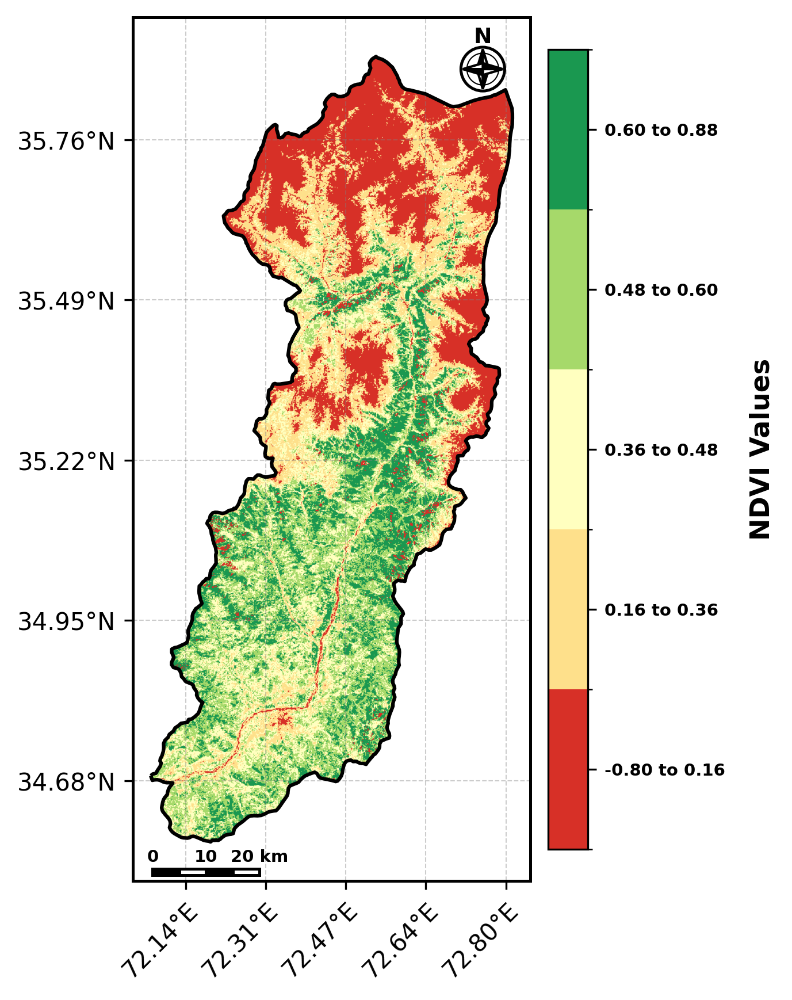

  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDVI_classified.png

🗺️  Generating map: NDBI ...


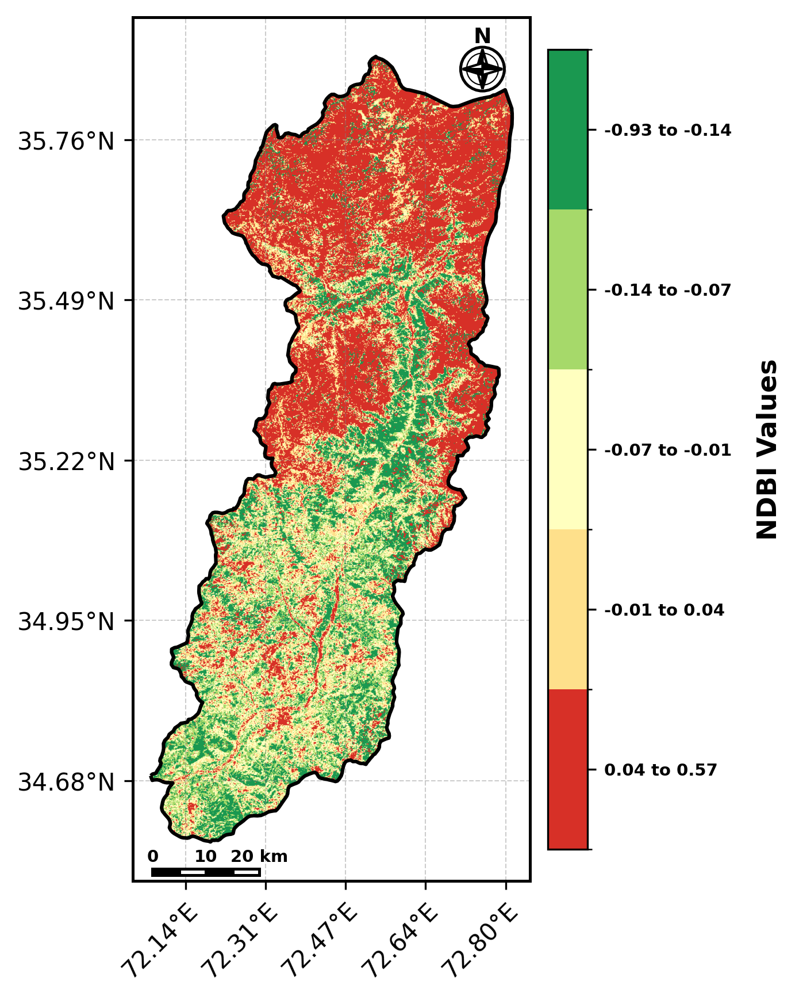

  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDBI_classified.png

🗺️  Generating map: MSI ...


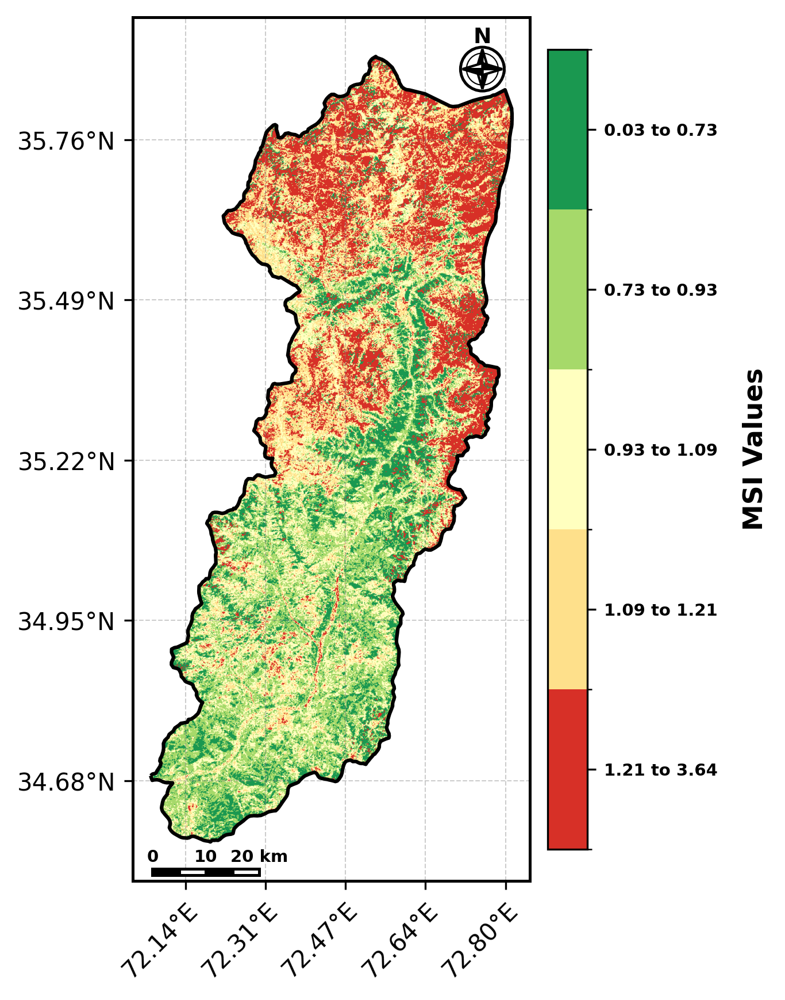

  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/MSI_classified.png

🗺️  Generating map: WVWI ...


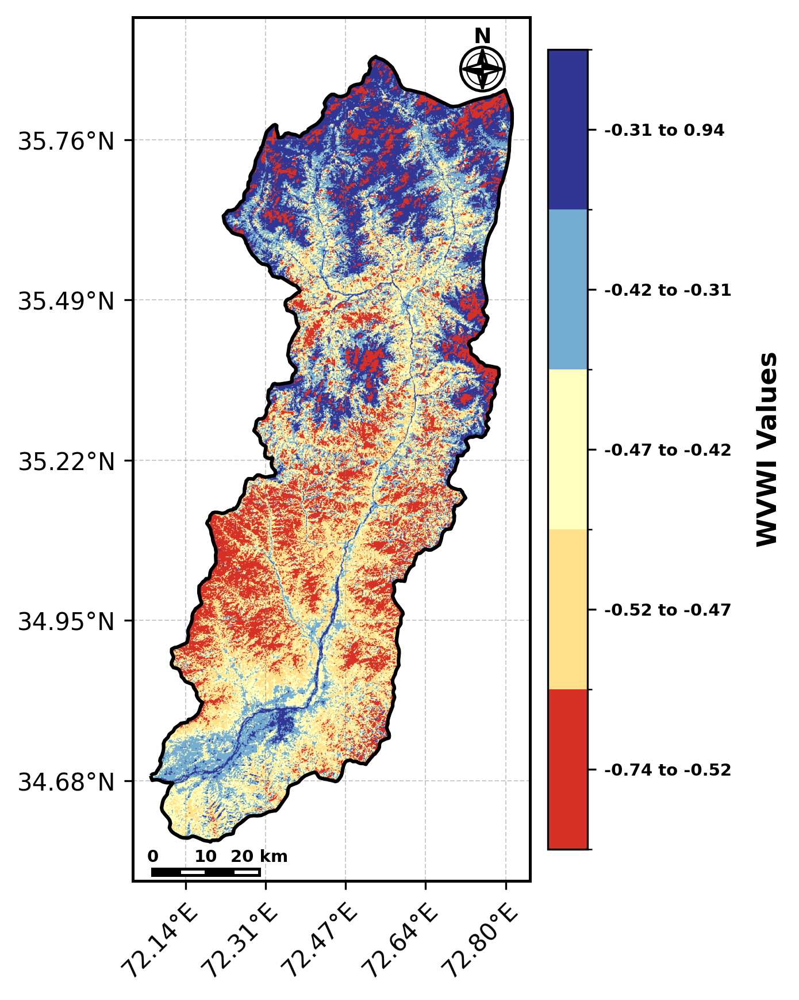

  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/WVWI_classified.png

🗺️  Generating map: LST ...


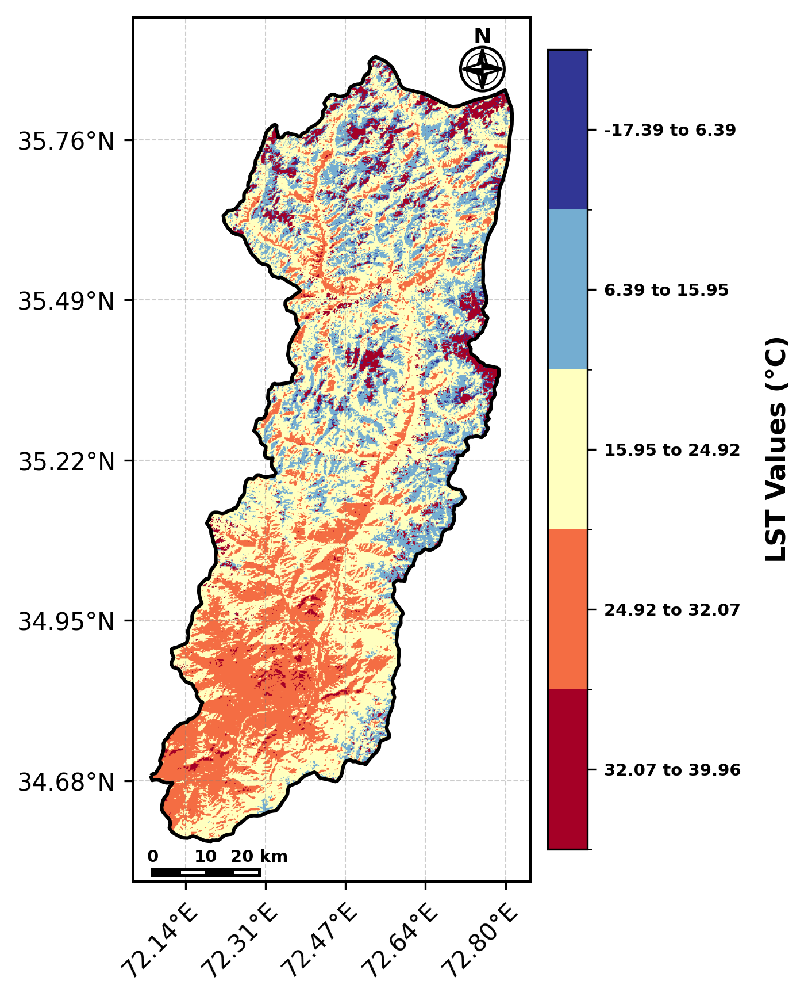

  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/LST_classified.png

  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT

  Parameter  Class (Range)             Class Rating    Class Ranking
  --------  ------------------------  --------------  -------------
  NDVI      -0.804 – 0.163            Very Low        1
            0.163 – 0.357             Low             2
            0.357 – 0.480             Moderate        3
            0.480 – 0.599             High            4
            0.599 – 0.884             Very High       5
  --------  ------------------------  --------------  -------------
  NDBI      -0.934 – -0.141           Very High       5
            -0.140 – -0.072           High            4
            -0.071 – -0.007           Moderate        3
            -0.007 – 0.041            Low             2
            0.042 – 0.569             Very Low        1
  --------  ------------------------  --------------  -------------
  MSI       0.034 – 0.

In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
import numpy as np
import os
import requests
from PIL import Image as PILImage
import io
import geopandas as gpd
import json
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS
# ==============================================================================
FIG_SIZE_INCHES    = 6.5
MAP_RESOLUTION_DPI = 300
TEAM_FONT          = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE         = 13
AXIS_LABEL_SIZE    = 11
TICK_VALUE_SIZE    = 11
LEGEND_SIZE        = 7
GRID_COLOR         = 'gray'
GRID_ALPHA         = 0.4
NORTH_ARROW_SCALE  = 0.05
SCALE_BAR_LENGTH_M = 20000  # 10 km

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643")  # Swat uses UTM 43N not 42N

geojso_str = gdf_4326.to_json()
geojso_obj = json.loads(geojso_str)
roi = ee.FeatureCollection(geojso_obj).geometry()

print(f"✅ ROI loaded: Swat District")
print(f"   CRS  : EPSG:32643 (UTM Zone 43N)")
print(f"   Type : {type(roi)}")

# ============================================================
# 2.1  LANDSAT 9 — SWAT-SPECIFIC CLOUD + SNOW MASKING
# ============================================================
# Swat needs additional snow + dilated cloud masking
# compared to Charsadda (flat plain, no snow issue)

def mask_l9_clouds(image):
    qa = image.select("QA_PIXEL")
    cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)  # Bit 3 = Cloud
    shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)  # Bit 4 = Cloud Shadow
    snow_mask    = qa.bitwiseAnd(1<<5).eq(0)  # Bit 5 = Snow (critical for Swat)
    dilated_mask = qa.bitwiseAnd(1<<1).eq(0)  # Bit 1 = Dilated Cloud
    return image.updateMask(
        cloud_mask.And(shadow_mask).And(snow_mask).And(dilated_mask)
    )

collection = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2025-09-01", "2025-11-30")
    .filter(ee.Filter.lt("CLOUD_COVER", 40))  # Relaxed from 20% for mountains
    .map(mask_l9_clouds)
)

n_scenes = collection.size().getInfo()
print(f"\n☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): {n_scenes}")

if n_scenes == 0:
    print("⚠️  Extending to June–Nov 2025 ...")
    collection = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(roi)
        .filterDate("2025-06-01", "2025-11-30")
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(mask_l9_clouds)
    )
    n_scenes = collection.size().getInfo()
    print(f"   Extended range scenes: {n_scenes}")

# ============================================================
# 2.2  RADIOMETRIC CALIBRATION + VALIDITY CHECK
# ============================================================
def calibrate(image):
    optical = image.select(["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"]) \
                   .multiply(0.0000275).add(-0.2)
    thermal = image.select("ST_B10") \
                   .multiply(0.00341802).add(149.0).subtract(273.15)
    calibrated = image.addBands(optical, overwrite=True) \
                      .addBands(thermal, overwrite=True)

    # Validity check — prevents MSI/WVWI division-by-near-zero
    # All bands must be in valid reflectance range 0.01–1.0
    valid_mask = (
        optical.select("SR_B2").gte(0.01).And(optical.select("SR_B2").lte(1.0))
        .And(optical.select("SR_B3").gte(0.01)).And(optical.select("SR_B3").lte(1.0))
        .And(optical.select("SR_B4").gte(0.01)).And(optical.select("SR_B4").lte(1.0))
        .And(optical.select("SR_B5").gte(0.01)).And(optical.select("SR_B5").lte(1.0))
        .And(optical.select("SR_B6").gte(0.01)).And(optical.select("SR_B6").lte(1.0))
        .And(optical.select("SR_B7").gte(0.01)).And(optical.select("SR_B7").lte(1.0))
    )
    return calibrated.updateMask(valid_mask)

composite = collection.map(calibrate).median().clip(roi)

B3  = composite.select("SR_B3")
B4  = composite.select("SR_B4")
B5  = composite.select("SR_B5")
B6  = composite.select("SR_B6")
LST = composite.select("ST_B10")

# ============================================================
# 2.3  COMPUTE INDICES WITH CLIPPING (Swat-specific)
# ============================================================
NDVI = B5.subtract(B4).divide(B5.add(B4)).clamp(-1.0, 1.0).rename("NDVI")
NDBI = B6.subtract(B5).divide(B6.add(B5)).clamp(-1.0, 1.0).rename("NDBI")
MSI  = B6.divide(B5).clamp(0.0, 5.0).rename("MSI")
WVWI = B3.subtract(B6).divide(B3.add(B6)).clamp(-1.0, 1.0).rename("WVWI")
LST  = LST.clamp(-30.0, 60.0).rename("LST")

layers = {"NDVI": NDVI, "NDBI": NDBI, "MSI": MSI, "WVWI": WVWI, "LST": LST}

# ============================================================
# 2.4  CLASS BOUNDARIES — SWAT DATA-DRIVEN BREAKS
# ============================================================
# These breaks are derived from your Step 1C diagnostic output
# for Swat district (Sept–Nov 2025 Landsat 9)
# They are DIFFERENT from Charsadda because Swat has:
#   - Higher vegetation cover (denser forests)
#   - Cooler temperatures (mountain elevations)
#   - More diverse land surface types

PAPER_CLASSES = {
    # NDVI: low→high vegetation = rating 1→5
    # Swat range: -0.804 to 0.884
    "NDVI": [
        (-0.8036,  0.1627, 1),   # Very Low  — bare rock/shadow/water
        ( 0.1627,  0.3573, 2),   # Low       — sparse vegetation
        ( 0.3573,  0.4798, 3),   # Moderate  — mixed/shrub
        ( 0.4798,  0.5986, 4),   # High      — dense vegetation
        ( 0.5986,  0.8842, 5),   # Very High — dense forest
    ],
    # NDBI: high built-up = rating 1 (inverted — built-up bad for GW)
    # Swat range: -0.934 to 0.569
    "NDBI": [
        (-0.9343, -0.141, 5),   # Very High — no built-up (forest/water)
        (-0.140, -0.072, 4),   # High      — low built-up
        (-0.071,  -0.007, 3),   # Moderate
        ( -0.007,  0.041, 2),   # Low       — moderate built-up
        ( 0.042,  0.5689, 1),   # Very Low  — high built-up (Mingora etc.)
    ],
    # MSI: low = moist = high rating (inverted)
    # Swat range: 0.034 to 3.639
    "MSI":  [
        (0.0340,  0.7341, 5),   # Very High — very moist (high GW recharge)
        (0.7341,  0.9286, 4),   # High
        (0.9286,  1.0865, 3),   # Moderate
        (1.0865,  1.2060, 2),   # Low
        (1.2060,  3.6390, 1),   # Very Low  — moisture stressed
    ],
    # WVWI: high wetness = high rating
    # Swat range: -0.742 to 0.936
    "WVWI": [
        (-0.7423, -0.5236, 1),   # Very Low  — driest
        (-0.5236, -0.4745, 2),   # Low
        (-0.4745, -0.4188, 3),   # Moderate
        (-0.4188, -0.3117, 4),   # High
        (-0.3117,  0.9361, 5),   # Very High — wettest (water/riparian zones)
    ],
    # LST: high temp = low GW = rating 1 (inverted)
    # Swat range: -17.4°C to 40.0°C — much wider than Charsadda (20–37°C)
    "LST":  [
        (-17.3950, 6.3887, 5),  # Very High — coolest (high elevation)
        ( 6.3887, 15.9503, 4),  # High
        ( 15.9503, 24.9240, 3),  # Moderate
        ( 24.9240, 32.0686, 2),  # Low
        ( 32.0686, 39.9560, 1),  # Very Low  — hottest (valley floor)
    ],
}

RATING_LABELS   = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}
RATING_RANKINGS = {5:5, 4:4, 3:3, 2:2, 1:1}

def paper_reclass(image, name):
    classes = PAPER_CLASSES[name]
    rated   = ee.Image(0)
    for (lo, hi, rating) in classes:
        mask  = image.gte(lo).And(image.lte(hi))
        rated = rated.where(mask, rating)
    return rated.rename(f"{name}_cls").clip(roi)

# ============================================================
# 2.5  RUN CLASSIFICATION
# ============================================================
classified = {}
stats_info = {}

for name, img in layers.items():
    print(f"  🔄 Reclassifying {name} ...")
    classified[name] = paper_reclass(img, name)
    s = img.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()
    stats_info[name] = {
        "min":  s[f"{name}_min"],
        "max":  s[f"{name}_max"],
        "mean": s[f"{name}_mean"],
    }

# ============================================================
# 2.6  THEMATIC MAP GENERATION — TEAM STYLING PRESERVED
# ============================================================
palettes = {
    "NDVI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],
    "NDBI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "MSI" : ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "WVWI": ["#d73027","#fee08b","#ffffbf","#74add1","#313695"],
    "LST" : ["#a50026","#f46d43","#ffffbf","#74add1","#313695"],
}
titles = {
    "NDVI": "Normalized Difference Vegetation Index (NDVI)",
    "NDBI": "Normalized Difference Built-up Index (NDBI)",
    "MSI" : "Moisture Stress Index (MSI)",
    "WVWI": "Water/Vegetation/Wetness Index (WVWI)",
    "LST" : "Land Surface Temperature — LST (°C)",
}
LEGEND_TITLES = {
    "NDVI": "NDVI Values",
    "NDBI": "NDBI Values",
    "MSI" : "MSI Values",
    "WVWI": "WVWI Values",
    "LST" : "LST Values (°C)",
}

# ── Compass rose ─────────────────────────────────────────────
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x,y), size*1.1,
                 facecolor='white', edgecolor='black',
                 linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x,y), size*0.8,
                 facecolor='none', edgecolor='black',
                 linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y+size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y+size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y-size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y-size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x+size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x+size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x-size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x-size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y+size*1.08, 'N',
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE+2, weight='bold', zorder=103)

# ── Scale bar ─────────────────────────────────────────────────
# ── Scale bar ─────────────────────────────────────────────────
def draw_scale_bar(ax, x, y, total_length_meters):
    segments   = 4
    seg_length = total_length_meters / segments
    height     = total_length_meters * 0.06
    for i in range(segments):
        start_x = x + (i * seg_length)
        color   = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle(
            (start_x, y), seg_length, height,
            linewidth=1.2, edgecolor='black',
            facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height*1.5,
                    str(label_val),
                    ha='center', va='bottom',
                    fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height*1.5,
            f"{int(total_length_meters/1000)} km",
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE, weight='bold', zorder=101)

# ── Main map function ─────────────────────────────────────────
def make_thematic_map(name, cls_img, palette, title, save_dir):

    # Render in UTM 43N (Swat uses Zone 43, not 42 like Charsadda)
    url  = cls_img.getThumbURL({
        "min"       : 1,
        "max"       : 5,
        "palette"   : palette,
        "region"    : roi,
        "dimensions": 1024,
        "crs"       : "EPSG:32643",   # ← Changed from 32642 to 32643
        "format"    : "png"
    })
    resp = requests.get(url)
    img  = PILImage.open(io.BytesIO(resp.content))

    # UTM bounds from Swat shapefile
    xmin, ymin, xmax, ymax = gdf_utm.total_bounds

    fig, ax = plt.subplots(
        figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES),
        dpi=MAP_RESOLUTION_DPI
    )

    # 5% margin + aspect lock (same as Charsadda)
    x_margin = (xmax - xmin) * 0.05
    y_margin = (ymax - ymin) * 0.05
    ax.set_xlim(xmin - x_margin, xmax + x_margin)
    ax.set_ylim(ymin - y_margin, ymax + y_margin)
    ax.set_aspect('equal')

    # Plot raster + district boundary
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
    gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

    # Grid
    ax.grid(True, color=GRID_COLOR, linestyle='--',
            linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

    # Axis tick intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    # Degree labels — using UTM 43N transformer
    transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True)
    center_x = (xmin + xmax) / 2
    center_y = (ymin + ymax) / 2

    ax.xaxis.set_major_formatter(ticker.FuncFormatter(
        lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"
    ))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(
        lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"
    ))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')



    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color('black')

    # Map dimensions for element positioning
    map_width  = ax.get_xlim()[1] - ax.get_xlim()[0]
    map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

    # Compass rose — top right
    draw_compass_rose(
        ax,
        ax.get_xlim()[0] + map_width  * 0.88,
        ax.get_ylim()[0] + map_height * 0.94,
        size=map_width * NORTH_ARROW_SCALE
    )

    # Scale bar — bottom left
    draw_scale_bar(
        ax,
        ax.get_xlim()[0] + map_width  * 0.05,
        ax.get_ylim()[0] + map_height * 0.007,
        total_length_meters=SCALE_BAR_LENGTH_M
    )

    # Vertical colorbar
    # Vertical colorbar (Adjusted fraction and pad to bring it closer)
    cmap = ListedColormap(palette)
    norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
    sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    # Changed fraction to 0.046 and pad to 0.02 to tighten the layout
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1,2,3,4,5])

    sorted_cls = sorted(PAPER_CLASSES[name], key=lambda x: x[2])
    # Changed formatting to 2 decimal places (.2f) instead of 3 for cleaner text
    labels     = [f"{c[0]:.2f} to {c[1]:.2f}" for c in sorted_cls]
    cbar.ax.set_yticklabels(labels, fontsize=LEGEND_SIZE, weight='bold')
    cbar.set_label(LEGEND_TITLES[name], fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

    # Save
    os.makedirs(save_dir, exist_ok=True)
    fname     = os.path.join(save_dir, f"{name}_classified.png")
    fname_pdf = os.path.join(save_dir, f"{name}_classified.pdf")

    plt.savefig(fname,     dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.savefig(fname_pdf, dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"  ✅ Saved: {fname}")

# ── Run all 5 maps ────────────────────────────────────────────
MAPS_DIR = os.path.join(BASE_DIR, "Thematic_Maps")
for name in layers:
    print(f"\n🗺️  Generating map: {name} ...")
    make_thematic_map(
        name, classified[name],
        palettes[name], titles[name], MAPS_DIR
    )

# ============================================================
# CLASS DISTRIBUTION SUMMARY TABLE
# ============================================================
print("\n" + "="*72)
print("  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT")
print("="*72)
print(f"\n  {'Parameter':<8}  {'Class (Range)':<24}  "
      f"{'Class Rating':<14}  {'Class Ranking'}")
print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")

for name in layers:
    sorted_cls = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    first_row  = True
    for (lo, hi, rating) in sorted_cls:
        param_col  = name if first_row else ""
        range_str  = f"{lo:.3f} – {hi:.3f}"
        rating_str = RATING_LABELS[rating]
        rank_str   = str(RATING_RANKINGS[rating])
        print(f"  {param_col:<8}  {range_str:<24}  "
              f"{rating_str:<14}  {rank_str}")
        first_row = False
    print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")
print("="*72)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 2 — VERIFICATION BLOCK (SWAT)")
print("="*60)
print(f"  District        : Swat, KPK Pakistan")
print(f"  Satellite       : Landsat 9 OLI/TIRS C2 L2")
print(f"  Date range      : Sept–Nov 2025")
print(f"  Cloud filter    : < 40% (relaxed for mountains)")
print(f"  Scenes used     : {n_scenes}")
print(f"  Snow masking    : Enabled (Bit 5 — critical for Swat)")
print(f"  Validity check  : All bands 0.01–1.0")
print(f"\n  {'Layer':<6}  {'Min':>9}  {'Max':>9}  {'Mean':>9}")
print(f"  {'-'*6}  {'-'*9}  {'-'*9}  {'-'*9}")
for name in layers:
    s = stats_info[name]
    print(f"  {name:<6}  {s['min']:>9.4f}  "
          f"{s['max']:>9.4f}  {s['mean']:>9.4f}")

print(f"\n  Class boundaries applied (Swat data-driven):")
print(f"  {'Layer':<6}  Boundaries (low → high) [rating]")
print(f"  {'-'*6}  {'-'*60}")
for name in layers:
    sc      = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    brk_str = "  |  ".join(
        [f"{c[0]:.3f}–{c[1]:.3f}[r{c[2]}]" for c in sc])
    print(f"  {name:<6}  {brk_str}")

print(f"\n  Key differences from Charsadda Step 2:")
print(f"    ✔ Snow masking (Bit 5) added to mask_l9_clouds()")
print(f"    ✔ Band validity check 0.01–1.0 (prevents MSI/WVWI extremes)")
print(f"    ✔ All indices clamped to valid ranges after computation")
print(f"    ✔ Cloud filter relaxed to 40% for mountain terrain")
print(f"    ✔ UTM Zone 43N (EPSG:32643) used instead of 42N")
print(f"    ✔ Class breaks derived from Swat Step 1C diagnostic output")
print(f"    ✔ LST range extended (-17°C to +40°C) for elevation gradient")
print("="*60)
print("✅ Step 2 complete — Send Step 3 Charsadda code to proceed.")

✅ ROI loaded: Swat District
   CRS  : EPSG:32643 (UTM Zone 43N)
   Type : <class 'ee.geometry.Geometry'>

☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): 19
  🔄 Calculating Stats & Reclassifying NDVI ...
  🔄 Calculating Stats & Reclassifying NDBI ...
  🔄 Calculating Stats & Reclassifying MSI ...
  🔄 Calculating Stats & Reclassifying WVWI ...
  🔄 Calculating Stats & Reclassifying LST ...

🗺️  Generating continuous map: NDVI ...


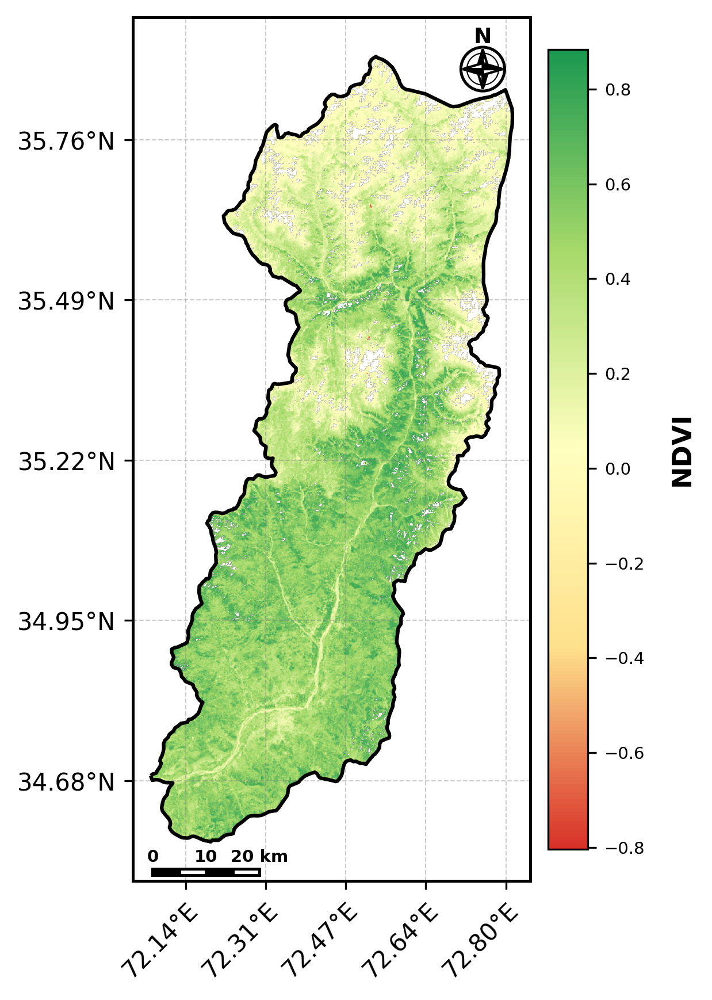

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDVI_continuous.png

🗺️  Generating continuous map: NDBI ...


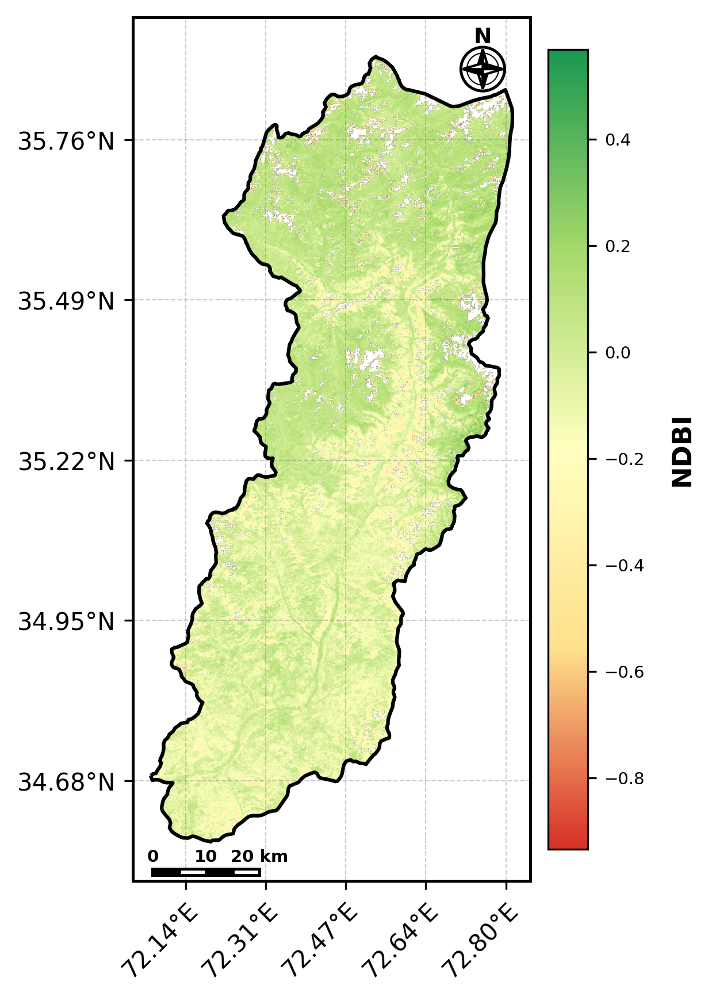

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDBI_continuous.png

🗺️  Generating continuous map: MSI ...


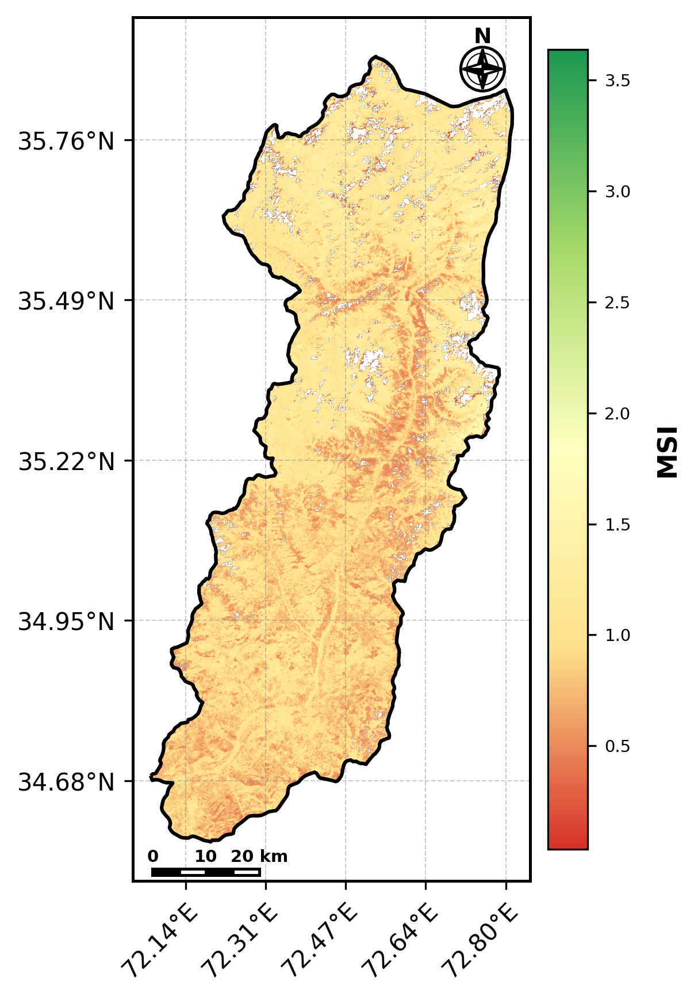

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/MSI_continuous.png

🗺️  Generating continuous map: WVWI ...


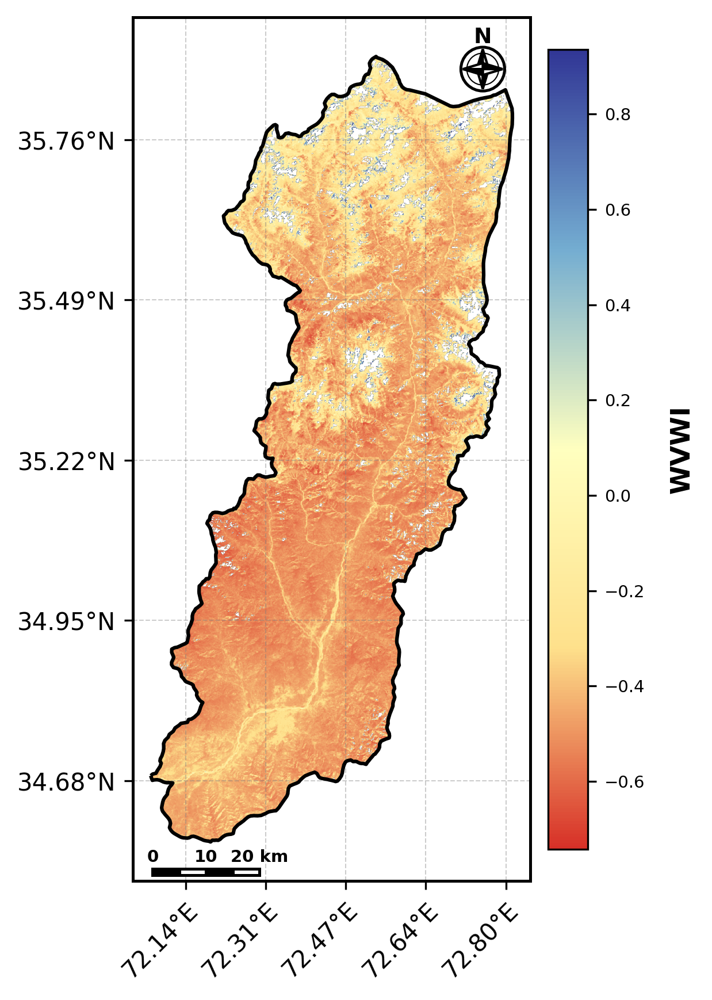

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/WVWI_continuous.png

🗺️  Generating continuous map: LST ...


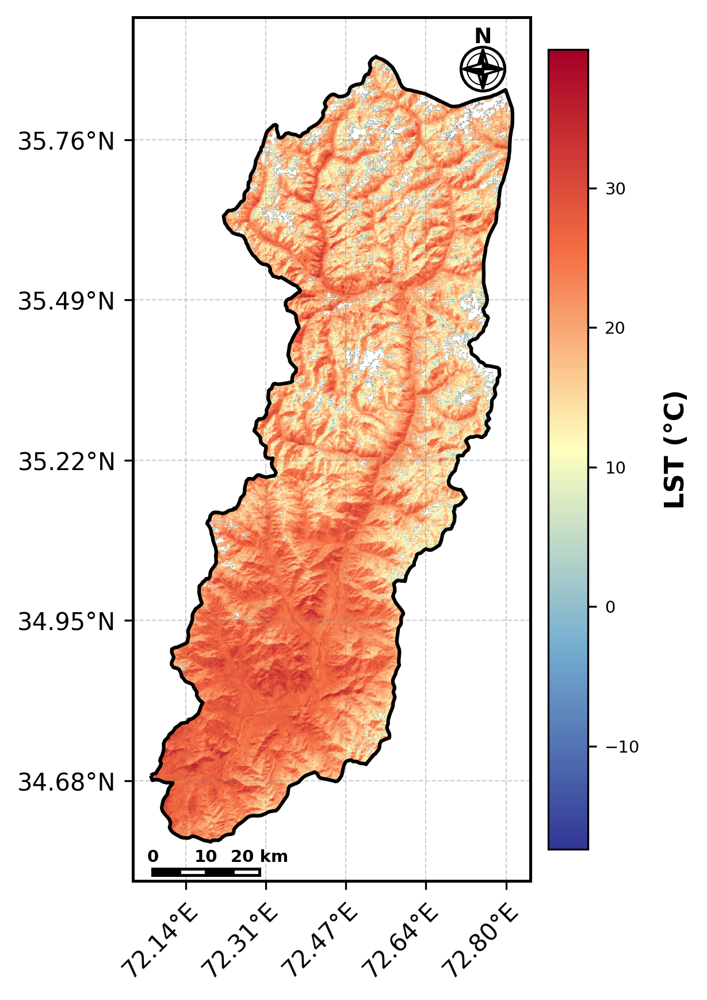

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/LST_continuous.png

  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT

  Parameter  Class (Range)             Class Rating    Class Ranking
  --------  ------------------------  --------------  -------------
  NDVI      -0.804 – 0.163            Very Low        1
            0.163 – 0.357             Low             2
            0.357 – 0.480             Moderate        3
            0.480 – 0.599             High            4
            0.599 – 0.884             Very High       5
  --------  ------------------------  --------------  -------------
  NDBI      -0.934 – -0.141           Very High       5
            -0.140 – -0.072           High            4
            -0.071 – -0.007           Moderate        3
            -0.007 – 0.041            Low             2
            0.042 – 0.569             Very Low        1
  --------  ------------------------  --------------  -------------
  MSI  

In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import LinearSegmentedColormap # Updated for continuous mapping
from pyproj import Transformer
import numpy as np
import os
import requests
from PIL import Image as PILImage
import io
import geopandas as gpd
import json
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS
# ==============================================================================
FIG_SIZE_INCHES    = 6.5
MAP_RESOLUTION_DPI = 300
TEAM_FONT          = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE         = 13
AXIS_LABEL_SIZE    = 11
TICK_VALUE_SIZE    = 11
LEGEND_SIZE        = 7
GRID_COLOR         = 'gray'
GRID_ALPHA         = 0.4
NORTH_ARROW_SCALE  = 0.05
SCALE_BAR_LENGTH_M = 20000  # 10 km

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643")  # Swat uses UTM 43N not 42N

geojso_str = gdf_4326.to_json()
geojso_obj = json.loads(geojso_str)
roi = ee.FeatureCollection(geojso_obj).geometry()

print(f"✅ ROI loaded: Swat District")
print(f"   CRS  : EPSG:32643 (UTM Zone 43N)")
print(f"   Type : {type(roi)}")

# ============================================================
# 2.1  LANDSAT 9 — SWAT-SPECIFIC CLOUD + SNOW MASKING
# ============================================================
# Swat needs additional snow + dilated cloud masking
# compared to Charsadda (flat plain, no snow issue)

def mask_l9_clouds(image):
    qa = image.select("QA_PIXEL")
    cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)  # Bit 3 = Cloud
    shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)  # Bit 4 = Cloud Shadow
    snow_mask    = qa.bitwiseAnd(1<<5).eq(0)  # Bit 5 = Snow (critical for Swat)
    dilated_mask = qa.bitwiseAnd(1<<1).eq(0)  # Bit 1 = Dilated Cloud
    return image.updateMask(
        cloud_mask.And(shadow_mask).And(snow_mask).And(dilated_mask)
    )

collection = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2025-09-01", "2025-11-30")
    .filter(ee.Filter.lt("CLOUD_COVER", 40))  # Relaxed from 20% for mountains
    .map(mask_l9_clouds)
)

n_scenes = collection.size().getInfo()
print(f"\n☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): {n_scenes}")

if n_scenes == 0:
    print("⚠️  Extending to June–Nov 2025 ...")
    collection = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(roi)
        .filterDate("2025-06-01", "2025-11-30")
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(mask_l9_clouds)
    )
    n_scenes = collection.size().getInfo()
    print(f"   Extended range scenes: {n_scenes}")

# ============================================================
# 2.2  RADIOMETRIC CALIBRATION + VALIDITY CHECK
# ============================================================
def calibrate(image):
    optical = image.select(["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"]) \
                   .multiply(0.0000275).add(-0.2)
    thermal = image.select("ST_B10") \
                   .multiply(0.00341802).add(149.0).subtract(273.15)
    calibrated = image.addBands(optical, overwrite=True) \
                      .addBands(thermal, overwrite=True)

    # Validity check — prevents MSI/WVWI division-by-near-zero
    # All bands must be in valid reflectance range 0.01–1.0
    valid_mask = (
        optical.select("SR_B2").gte(0.01).And(optical.select("SR_B2").lte(1.0))
        .And(optical.select("SR_B3").gte(0.01)).And(optical.select("SR_B3").lte(1.0))
        .And(optical.select("SR_B4").gte(0.01)).And(optical.select("SR_B4").lte(1.0))
        .And(optical.select("SR_B5").gte(0.01)).And(optical.select("SR_B5").lte(1.0))
        .And(optical.select("SR_B6").gte(0.01)).And(optical.select("SR_B6").lte(1.0))
        .And(optical.select("SR_B7").gte(0.01)).And(optical.select("SR_B7").lte(1.0))
    )
    return calibrated.updateMask(valid_mask)

composite = collection.map(calibrate).median().clip(roi)

B3  = composite.select("SR_B3")
B4  = composite.select("SR_B4")
B5  = composite.select("SR_B5")
B6  = composite.select("SR_B6")
LST = composite.select("ST_B10")

# ============================================================
# 2.3  COMPUTE INDICES WITH CLIPPING (Swat-specific)
# ============================================================
NDVI = B5.subtract(B4).divide(B5.add(B4)).clamp(-1.0, 1.0).rename("NDVI")
NDBI = B6.subtract(B5).divide(B6.add(B5)).clamp(-1.0, 1.0).rename("NDBI")
MSI  = B6.divide(B5).clamp(0.0, 5.0).rename("MSI")
WVWI = B3.subtract(B6).divide(B3.add(B6)).clamp(-1.0, 1.0).rename("WVWI")
LST  = LST.clamp(-30.0, 60.0).rename("LST")

layers = {"NDVI": NDVI, "NDBI": NDBI, "MSI": MSI, "WVWI": WVWI, "LST": LST}

# ============================================================
# 2.4  CLASS BOUNDARIES — SWAT DATA-DRIVEN BREAKS
# ============================================================
PAPER_CLASSES = {
    # NDVI: low→high vegetation = rating 1→5
    # Swat range: -0.804 to 0.884
    "NDVI": [
        (-0.8036,  0.1627, 1),   # Very Low  — bare rock/shadow/water
        ( 0.1627,  0.3573, 2),   # Low       — sparse vegetation
        ( 0.3573,  0.4798, 3),   # Moderate  — mixed/shrub
        ( 0.4798,  0.5986, 4),   # High      — dense vegetation
        ( 0.5986,  0.8842, 5),   # Very High — dense forest
    ],
    # NDBI: high built-up = rating 1 (inverted — built-up bad for GW)
    # Swat range: -0.934 to 0.569
    "NDBI": [
        (-0.9343, -0.141, 5),   # Very High — no built-up (forest/water)
        (-0.140, -0.072, 4),   # High      — low built-up
        (-0.071,  -0.007, 3),   # Moderate
        ( -0.007,  0.041, 2),   # Low       — moderate built-up
        ( 0.042,  0.5689, 1),   # Very Low  — high built-up (Mingora etc.)
    ],
    # MSI: low = moist = high rating (inverted)
    # Swat range: 0.034 to 3.639
    "MSI":  [
        (0.0340,  0.7341, 5),   # Very High — very moist (high GW recharge)
        (0.7341,  0.9286, 4),   # High
        (0.9286,  1.0865, 3),   # Moderate
        (1.0865,  1.2060, 2),   # Low
        (1.2060,  3.6390, 1),   # Very Low  — moisture stressed
    ],
    # WVWI: high wetness = high rating
    # Swat range: -0.742 to 0.936
    "WVWI": [
        (-0.7423, -0.5236, 1),   # Very Low  — driest
        (-0.5236, -0.4745, 2),   # Low
        (-0.4745, -0.4188, 3),   # Moderate
        (-0.4188, -0.3117, 4),   # High
        (-0.3117,  0.9361, 5),   # Very High — wettest (water/riparian zones)
    ],
    # LST: high temp = low GW = rating 1 (inverted)
    # Swat range: -17.4°C to 40.0°C — much wider than Charsadda (20–37°C)
    "LST":  [
        (-17.3950, 16.3887, 5),  # Very High — coolest (high elevation)
        ( 16.3887, 19.9503, 4),  # High
        ( 19.9503, 22.9240, 3),  # Moderate
        ( 22.9240, 26.0686, 2),  # Low
        ( 26.0686, 39.9560, 1),  # Very Low  — hottest (valley floor)
    ],
}

RATING_LABELS   = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}
RATING_RANKINGS = {5:5, 4:4, 3:3, 2:2, 1:1}

def paper_reclass(image, name):
    classes = PAPER_CLASSES[name]
    rated   = ee.Image(0)
    for (lo, hi, rating) in classes:
        mask  = image.gte(lo).And(image.lte(hi))
        rated = rated.where(mask, rating)
    return rated.rename(f"{name}_cls").clip(roi)

# ============================================================
# 2.5  RUN CLASSIFICATION (Maintained for stats/AHP tables)
# ============================================================
classified = {}
stats_info = {}

for name, img in layers.items():
    print(f"  🔄 Calculating Stats & Reclassifying {name} ...")
    classified[name] = paper_reclass(img, name)
    s = img.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()
    stats_info[name] = {
        "min":  s[f"{name}_min"],
        "max":  s[f"{name}_max"],
        "mean": s[f"{name}_mean"],
    }

# ============================================================
# 2.6  THEMATIC MAP GENERATION — CONTINUOUS TEAM STYLING
# ============================================================
palettes = {
    "NDVI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],
    "NDBI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "MSI" : ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "WVWI": ["#d73027","#fee08b","#ffffbf","#74add1","#313695"],
    "LST" : ["#313695","#74add1","#ffffbf","#f46d43","#a50026"],
}
titles = {
    "NDVI": "Normalized Difference Vegetation Index (NDVI)",
    "NDBI": "Normalized Difference Built-up Index (NDBI)",
    "MSI" : "Moisture Stress Index (MSI)",
    "WVWI": "Water/Vegetation/Wetness Index (WVWI)",
    "LST" : "Land Surface Temperature — LST (°C)",
}
LEGEND_TITLES = {
    "NDVI": "NDVI",
    "NDBI": "NDBI",
    "MSI" : "MSI",
    "WVWI": "WVWI",
    "LST" : "LST (°C)",
}

# ── Compass rose ─────────────────────────────────────────────
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x,y), size*1.1,
                 facecolor='white', edgecolor='black',
                 linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x,y), size*0.8,
                 facecolor='none', edgecolor='black',
                 linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y+size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y+size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y-size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y-size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x+size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x+size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x-size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x-size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y+size*1.08, 'N',
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE+2, weight='bold', zorder=103)

# ── Scale bar ─────────────────────────────────────────────────
def draw_scale_bar(ax, x, y, total_length_meters):
    segments   = 4
    seg_length = total_length_meters / segments
    height     = total_length_meters * 0.06
    for i in range(segments):
        start_x = x + (i * seg_length)
        color   = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle(
            (start_x, y), seg_length, height,
            linewidth=1.2, edgecolor='black',
            facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height*1.5,
                    str(label_val),
                    ha='center', va='bottom',
                    fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height*1.5,
            f"{int(total_length_meters/1000)} km",
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE, weight='bold', zorder=101)

# ── Main continuous map function ──────────────────────────────
def make_thematic_map_continuous(name, raw_img, vmin, vmax, palette, title, save_dir):

    # Render True Continuous Data in UTM 43N (Swat uses Zone 43)
    url  = raw_img.getThumbURL({
        "min"       : vmin,
        "max"       : vmax,
        "palette"   : palette,
        "region"    : roi,
        "dimensions": 1024,
        "crs"       : "EPSG:32643",   # ← Changed from 32642 to 32643
        "format"    : "png"
    })
    resp = requests.get(url)
    img  = PILImage.open(io.BytesIO(resp.content))

    # UTM bounds from Swat shapefile
    xmin, ymin, xmax, ymax = gdf_utm.total_bounds

    fig, ax = plt.subplots(
        figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES),
        dpi=MAP_RESOLUTION_DPI
    )

    # 5% margin + aspect lock
    x_margin = (xmax - xmin) * 0.05
    y_margin = (ymax - ymin) * 0.05
    ax.set_xlim(xmin - x_margin, xmax + x_margin)
    ax.set_ylim(ymin - y_margin, ymax + y_margin)
    ax.set_aspect('equal')

    # Plot raster + district boundary
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
    gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

    # Grid
    ax.grid(True, color=GRID_COLOR, linestyle='--',
            linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

    # Axis tick intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    # Degree labels — using UTM 43N transformer
    transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True)
    center_x = (xmin + xmax) / 2
    center_y = (ymin + ymax) / 2

    ax.xaxis.set_major_formatter(ticker.FuncFormatter(
        lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"
    ))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(
        lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"
    ))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color('black')

    # Map dimensions for element positioning
    map_width  = ax.get_xlim()[1] - ax.get_xlim()[0]
    map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

    # Compass rose — top right (Preserved your Swat layout)
    draw_compass_rose(
        ax,
        ax.get_xlim()[0] + map_width  * 0.88,
        ax.get_ylim()[0] + map_height * 0.94,
        size=map_width * NORTH_ARROW_SCALE
    )

    # Scale bar — bottom left (Preserved your Swat layout)
    draw_scale_bar(
        ax,
        ax.get_xlim()[0] + map_width  * 0.05,
        ax.get_ylim()[0] + map_height * 0.007,
        total_length_meters=SCALE_BAR_LENGTH_M
    )

    # Continuous Vertical Colorbar (Using your Swat tweaks)
    cmap = LinearSegmentedColormap.from_list(f"{name}_cmap", palette)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.ax.tick_params(labelsize=LEGEND_SIZE)
    cbar.set_label(LEGEND_TITLES[name], fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

    # Save
    os.makedirs(save_dir, exist_ok=True)
    fname     = os.path.join(save_dir, f"{name}_continuous.png")
    fname_pdf = os.path.join(save_dir, f"{name}_continuous.pdf")

    plt.savefig(fname,     dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.savefig(fname_pdf, dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"  ✅ Saved Continuous Map: {fname}")

# ── Run all 5 maps ────────────────────────────────────────────
MAPS_DIR = os.path.join(BASE_DIR, "Thematic_Maps")
for name in layers:
    print(f"\n🗺️  Generating continuous map: {name} ...")
    s = stats_info[name]
    make_thematic_map_continuous(
        name=name,
        raw_img=layers[name],
        vmin=s['min'],
        vmax=s['max'],
        palette=palettes[name],
        title=titles[name],
        save_dir=MAPS_DIR
    )

# ============================================================
# CLASS DISTRIBUTION SUMMARY TABLE
# ============================================================
print("\n" + "="*72)
print("  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT")
print("="*72)
print(f"\n  {'Parameter':<8}  {'Class (Range)':<24}  "
      f"{'Class Rating':<14}  {'Class Ranking'}")
print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")

for name in layers:
    sorted_cls = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    first_row  = True
    for (lo, hi, rating) in sorted_cls:
        param_col  = name if first_row else ""
        range_str  = f"{lo:.3f} – {hi:.3f}"
        rating_str = RATING_LABELS[rating]
        rank_str   = str(RATING_RANKINGS[rating])
        print(f"  {param_col:<8}  {range_str:<24}  "
              f"{rating_str:<14}  {rank_str}")
        first_row = False
    print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")
print("="*72)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 2 — VERIFICATION BLOCK (SWAT)")
print("="*60)
print(f"  District        : Swat, KPK Pakistan")
print(f"  Satellite       : Landsat 9 OLI/TIRS C2 L2")
print(f"  Date range      : Sept–Nov 2025")
print(f"  Cloud filter    : < 40% (relaxed for mountains)")
print(f"  Scenes used     : {n_scenes}")
print(f"  Snow masking    : Enabled (Bit 5 — critical for Swat)")
print(f"  Validity check  : All bands 0.01–1.0")
print(f"  Visual Render   : Fully Continuous Distribution")
print(f"\n  {'Layer':<6}  {'Min':>9}  {'Max':>9}  {'Mean':>9}")
print(f"  {'-'*6}  {'-'*9}  {'-'*9}  {'-'*9}")
for name in layers:
    s = stats_info[name]
    print(f"  {name:<6}  {s['min']:>9.4f}  "
          f"{s['max']:>9.4f}  {s['mean']:>9.4f}")

print(f"\n  Class boundaries (Maintained for statistical tracking):")
print(f"  {'Layer':<6}  Boundaries (low → high) [rating]")
print(f"  {'-'*6}  {'-'*60}")
for name in layers:
    sc      = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    brk_str = "  |  ".join(
        [f"{c[0]:.3f}–{c[1]:.3f}[r{c[2]}]" for c in sc])
    print(f"  {name:<6}  {brk_str}")

print(f"\n  Key differences from Charsadda Step 2:")
print(f"    ✔ Snow masking (Bit 5) added to mask_l9_clouds()")
print(f"    ✔ Band validity check 0.01–1.0 (prevents MSI/WVWI extremes)")
print(f"    ✔ All indices clamped to valid ranges after computation")
print(f"    ✔ Cloud filter relaxed to 40% for mountain terrain")
print(f"    ✔ UTM Zone 43N (EPSG:32643) used instead of 42N")
print(f"    ✔ Class breaks derived from Swat Step 1C diagnostic output")
print(f"    ✔ LST range extended (-17°C to +40°C) for elevation gradient")
print("="*60)
print("✅ Step 2 complete for Swat with Continuous Maps.")

✅ ROI loaded: Swat District
   CRS  : EPSG:32643 (UTM Zone 43N)
   Type : <class 'ee.geometry.Geometry'>

☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): 19
  🔄 Calculating Stats & Reclassifying NDVI ...
  🔄 Calculating Stats & Reclassifying NDBI ...
  🔄 Calculating Stats & Reclassifying MSI ...
  🔄 Calculating Stats & Reclassifying WVWI ...
  🔄 Calculating Stats & Reclassifying LST ...

🗺️  Generating continuous map: NDVI ...


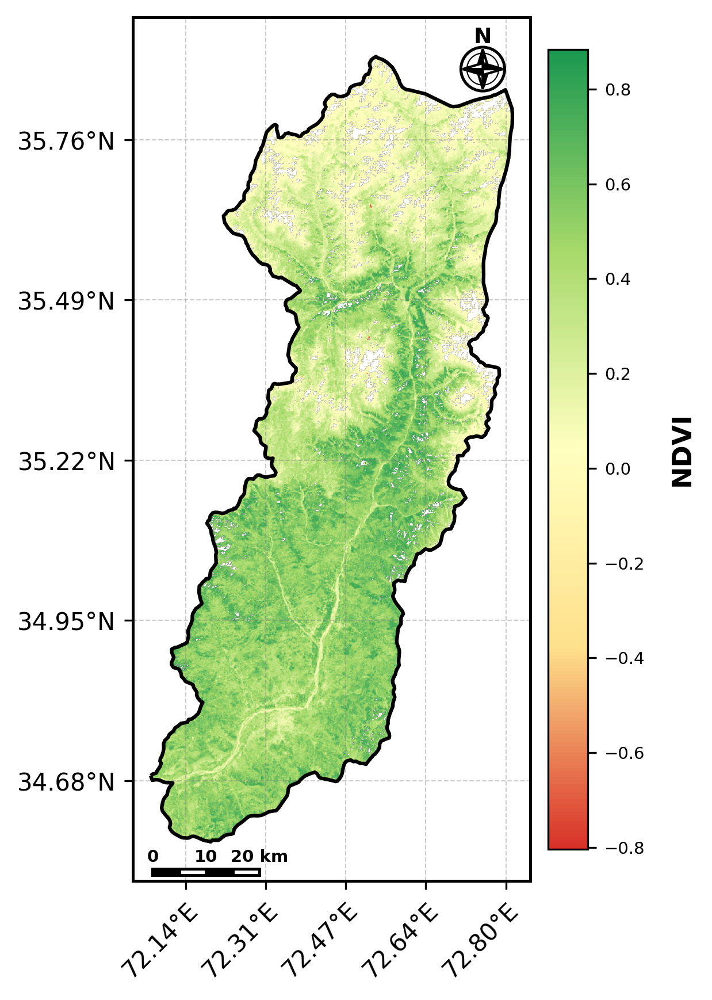

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDVI_continuous.png

🗺️  Generating continuous map: NDBI ...


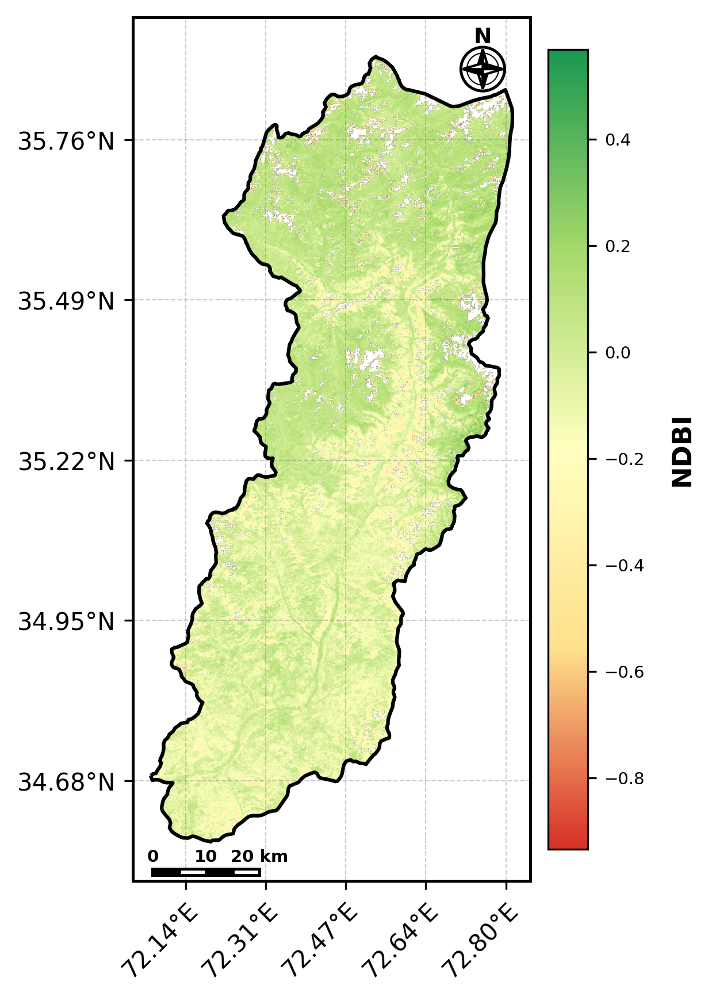

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/NDBI_continuous.png

🗺️  Generating continuous map: MSI ...


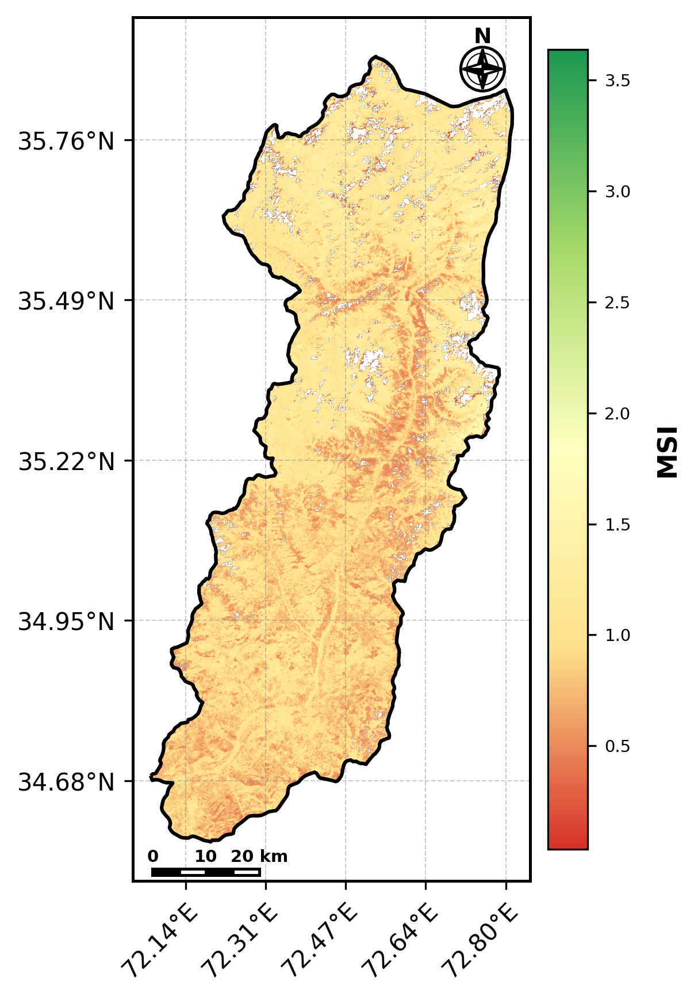

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/MSI_continuous.png

🗺️  Generating continuous map: WVWI ...


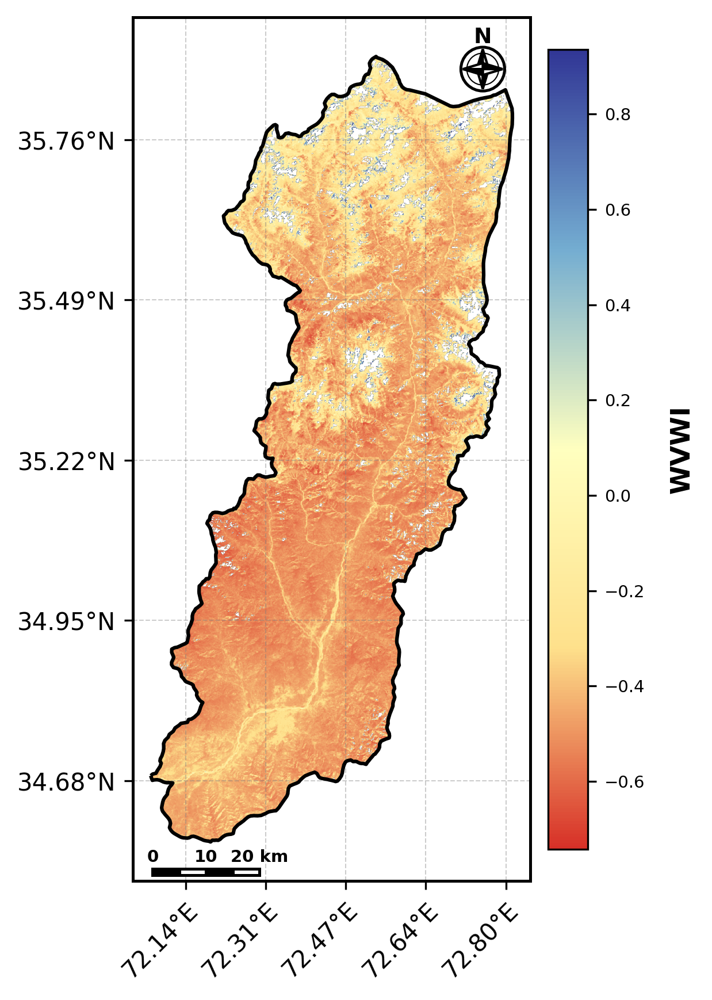

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/WVWI_continuous.png

🗺️  Generating continuous map: LST ...


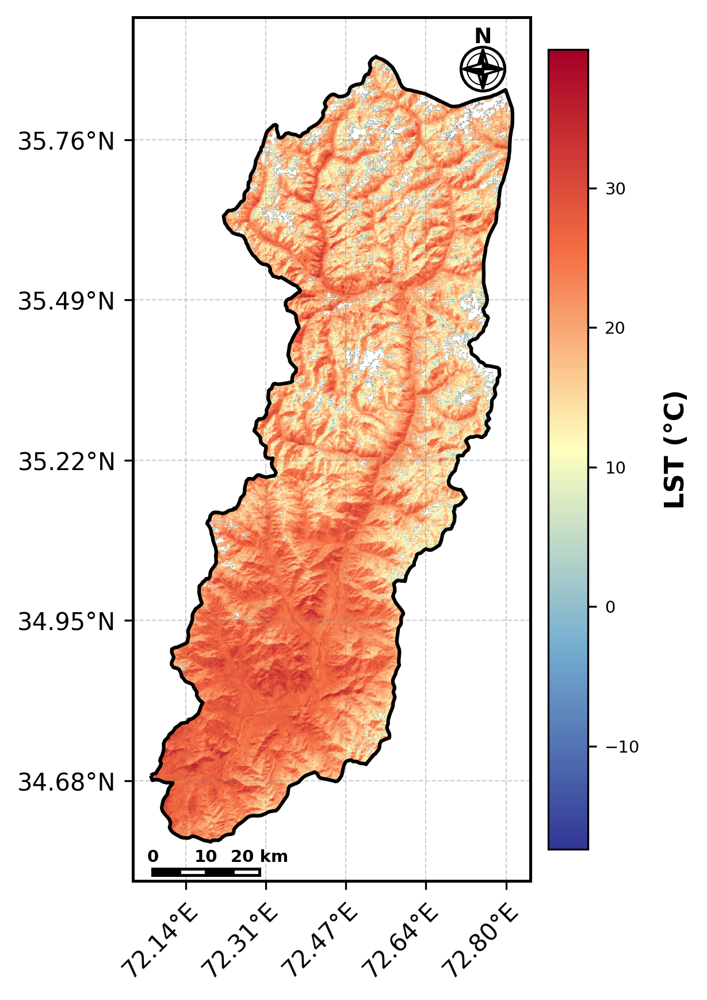

  ✅ Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/LST_continuous.png

  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT

  Parameter  Class (Range)             Class Rating    Class Ranking
  --------  ------------------------  --------------  -------------
  NDVI      -0.804 – 0.163            Very Low        1
            0.163 – 0.357             Low             2
            0.357 – 0.480             Moderate        3
            0.480 – 0.599             High            4
            0.599 – 0.884             Very High       5
  --------  ------------------------  --------------  -------------
  NDBI      -0.934 – -0.141           Very High       5
            -0.140 – -0.072           High            4
            -0.071 – -0.007           Moderate        3
            -0.007 – 0.041            Low             2
            0.042 – 0.569             Very Low        1
  --------  ------------------------  --------------  -------------
  MSI  

In [ ]:
import ee
import geemap
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import LinearSegmentedColormap # Updated for continuous
from pyproj import Transformer
import numpy as np
import os
import requests
from PIL import Image as PILImage
import io
import geopandas as gpd
import json
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS
# ==============================================================================
FIG_SIZE_INCHES    = 6.5
MAP_RESOLUTION_DPI = 300
TEAM_FONT          = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE         = 13
AXIS_LABEL_SIZE    = 11
TICK_VALUE_SIZE    = 11
LEGEND_SIZE        = 7
GRID_COLOR         = 'gray'
GRID_ALPHA         = 0.4
NORTH_ARROW_SCALE  = 0.05
SCALE_BAR_LENGTH_M = 20000  # 10 km

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643")  # Swat uses UTM 43N not 42N

geojso_str = gdf_4326.to_json()
geojso_obj = json.loads(geojso_str)
roi = ee.FeatureCollection(geojso_obj).geometry()

print(f"✅ ROI loaded: Swat District")
print(f"   CRS  : EPSG:32643 (UTM Zone 43N)")
print(f"   Type : {type(roi)}")

# ============================================================
# 2.1  LANDSAT 9 — SWAT-SPECIFIC CLOUD + SNOW MASKING
# ============================================================
# Swat needs additional snow + dilated cloud masking
# compared to Charsadda (flat plain, no snow issue)

def mask_l9_clouds(image):
    qa = image.select("QA_PIXEL")
    cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)  # Bit 3 = Cloud
    shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)  # Bit 4 = Cloud Shadow
    snow_mask    = qa.bitwiseAnd(1<<5).eq(0)  # Bit 5 = Snow (critical for Swat)
    dilated_mask = qa.bitwiseAnd(1<<1).eq(0)  # Bit 1 = Dilated Cloud
    return image.updateMask(
        cloud_mask.And(shadow_mask).And(snow_mask).And(dilated_mask)
    )

collection = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2025-09-01", "2025-11-30")
    .filter(ee.Filter.lt("CLOUD_COVER", 40))  # Relaxed from 20% for mountains
    .map(mask_l9_clouds)
)

n_scenes = collection.size().getInfo()
print(f"\n☁️  Landsat 9 scenes (Sept–Nov 2025, cloud<40%): {n_scenes}")

if n_scenes == 0:
    print("⚠️  Extending to June–Nov 2025 ...")
    collection = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(roi)
        .filterDate("2025-06-01", "2025-11-30")
        .filter(ee.Filter.lt("CLOUD_COVER", 50))
        .map(mask_l9_clouds)
    )
    n_scenes = collection.size().getInfo()
    print(f"   Extended range scenes: {n_scenes}")

# ============================================================
# 2.2  RADIOMETRIC CALIBRATION + VALIDITY CHECK
# ============================================================
def calibrate(image):
    optical = image.select(["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"]) \
                   .multiply(0.0000275).add(-0.2)
    thermal = image.select("ST_B10") \
                   .multiply(0.00341802).add(149.0).subtract(273.15)
    calibrated = image.addBands(optical, overwrite=True) \
                      .addBands(thermal, overwrite=True)

    # Validity check — prevents MSI/WVWI division-by-near-zero
    # All bands must be in valid reflectance range 0.01–1.0
    valid_mask = (
        optical.select("SR_B2").gte(0.01).And(optical.select("SR_B2").lte(1.0))
        .And(optical.select("SR_B3").gte(0.01)).And(optical.select("SR_B3").lte(1.0))
        .And(optical.select("SR_B4").gte(0.01)).And(optical.select("SR_B4").lte(1.0))
        .And(optical.select("SR_B5").gte(0.01)).And(optical.select("SR_B5").lte(1.0))
        .And(optical.select("SR_B6").gte(0.01)).And(optical.select("SR_B6").lte(1.0))
        .And(optical.select("SR_B7").gte(0.01)).And(optical.select("SR_B7").lte(1.0))
    )
    return calibrated.updateMask(valid_mask)

composite = collection.map(calibrate).median().clip(roi)

B3  = composite.select("SR_B3")
B4  = composite.select("SR_B4")
B5  = composite.select("SR_B5")
B6  = composite.select("SR_B6")
LST = composite.select("ST_B10")

# ============================================================
# 2.3  COMPUTE INDICES WITH CLIPPING (Swat-specific)
# ============================================================
NDVI = B5.subtract(B4).divide(B5.add(B4)).clamp(-1.0, 1.0).rename("NDVI")
NDBI = B6.subtract(B5).divide(B6.add(B5)).clamp(-1.0, 1.0).rename("NDBI")
MSI  = B6.divide(B5).clamp(0.0, 5.0).rename("MSI")
WVWI = B3.subtract(B6).divide(B3.add(B6)).clamp(-1.0, 1.0).rename("WVWI")
LST  = LST.clamp(-30.0, 60.0).rename("LST")

layers = {"NDVI": NDVI, "NDBI": NDBI, "MSI": MSI, "WVWI": WVWI, "LST": LST}

# ============================================================
# 2.4  CLASS BOUNDARIES — SWAT DATA-DRIVEN BREAKS
# ============================================================
# These breaks are derived from your Step 1C diagnostic output
# for Swat district (Sept–Nov 2025 Landsat 9)
# They are DIFFERENT from Charsadda because Swat has:
#   - Higher vegetation cover (denser forests)
#   - Cooler temperatures (mountain elevations)
#   - More diverse land surface types

PAPER_CLASSES = {
    # NDVI: low→high vegetation = rating 1→5
    # Swat range: -0.804 to 0.884
    "NDVI": [
        (-0.8036,  0.1627, 1),   # Very Low  — bare rock/shadow/water
        ( 0.1627,  0.3573, 2),   # Low       — sparse vegetation
        ( 0.3573,  0.4798, 3),   # Moderate  — mixed/shrub
        ( 0.4798,  0.5986, 4),   # High      — dense vegetation
        ( 0.5986,  0.8842, 5),   # Very High — dense forest
    ],
    # NDBI: high built-up = rating 1 (inverted — built-up bad for GW)
    # Swat range: -0.934 to 0.569
    "NDBI": [
        (-0.9343, -0.141, 5),   # Very High — no built-up (forest/water)
        (-0.140, -0.072, 4),   # High      — low built-up
        (-0.071,  -0.007, 3),   # Moderate
        ( -0.007,  0.041, 2),   # Low       — moderate built-up
        ( 0.042,  0.5689, 1),   # Very Low  — high built-up (Mingora etc.)
    ],
    # MSI: low = moist = high rating (inverted)
    # Swat range: 0.034 to 3.639
    "MSI":  [
        (0.0340,  0.7341, 5),   # Very High — very moist (high GW recharge)
        (0.7341,  0.9286, 4),   # High
        (0.9286,  1.0865, 3),   # Moderate
        (1.0865,  1.2060, 2),   # Low
        (1.2060,  3.6390, 1),   # Very Low  — moisture stressed
    ],
    # WVWI: high wetness = high rating
    # Swat range: -0.742 to 0.936
    "WVWI": [
        (-0.7423, -0.5236, 1),   # Very Low  — driest
        (-0.5236, -0.4745, 2),   # Low
        (-0.4745, -0.4188, 3),   # Moderate
        (-0.4188, -0.3117, 4),   # High
        (-0.3117,  0.9361, 5),   # Very High — wettest (water/riparian zones)
    ],
    # LST: high temp = low GW = rating 1 (inverted)
    # Swat range: -17.4°C to 40.0°C — much wider than Charsadda (20–37°C)
    "LST":  [
        (-17.3950, 16.3887, 5),  # Very High — coolest (high elevation)
        ( 16.3887, 19.9503, 4),  # High
        ( 19.9503, 22.9240, 3),  # Moderate
        ( 22.9240, 26.0686, 2),  # Low
        ( 26.0686, 39.9560, 1),  # Very Low  — hottest (valley floor)
    ],
}

RATING_LABELS   = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}
RATING_RANKINGS = {5:5, 4:4, 3:3, 2:2, 1:1}

def paper_reclass(image, name):
    classes = PAPER_CLASSES[name]
    rated   = ee.Image(0)
    for (lo, hi, rating) in classes:
        mask  = image.gte(lo).And(image.lte(hi))
        rated = rated.where(mask, rating)
    return rated.rename(f"{name}_cls").clip(roi)

# ============================================================
# 2.5  RUN CLASSIFICATION (Maintained for stats/AHP)
# ============================================================
classified = {}
stats_info = {}

for name, img in layers.items():
    print(f"  🔄 Calculating Stats & Reclassifying {name} ...")
    classified[name] = paper_reclass(img, name)
    s = img.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()
    stats_info[name] = {
        "min":  s[f"{name}_min"],
        "max":  s[f"{name}_max"],
        "mean": s[f"{name}_mean"],
    }

# ============================================================
# 2.6  THEMATIC MAP GENERATION — CONTINUOUS TEAM STYLING
# ============================================================
palettes = {
    "NDVI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],
    "NDBI": ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "MSI" : ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"],  # reversed
    "WVWI": ["#d73027","#fee08b","#ffffbf","#74add1","#313695"],
    "LST" : ["#313695","#74add1","#ffffbf","#f46d43","#a50026"],
}
titles = {
    "NDVI": "Normalized Difference Vegetation Index (NDVI)",
    "NDBI": "Normalized Difference Built-up Index (NDBI)",
    "MSI" : "Moisture Stress Index (MSI)",
    "WVWI": "Water/Vegetation/Wetness Index (WVWI)",
    "LST" : "Land Surface Temperature — LST (°C)",
}
LEGEND_TITLES = {
    "NDVI": "NDVI",
    "NDBI": "NDBI",
    "MSI" : "MSI",
    "WVWI": "WVWI",
    "LST" : "LST (°C)",
}

# ── Compass rose ─────────────────────────────────────────────
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x,y), size*1.1,
                 facecolor='white', edgecolor='black',
                 linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x,y), size*0.8,
                 facecolor='none', edgecolor='black',
                 linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y+size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y+size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x-size*0.3,y],[x,y-size]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x+size*0.3,y],[x,y-size]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x+size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x+size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y+size*0.3],[x-size,y]],
        facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon(
        [[x,y],[x,y-size*0.3],[x-size,y]],
        facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y+size*1.08, 'N',
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE+2, weight='bold', zorder=103)

# ── Scale bar ─────────────────────────────────────────────────
def draw_scale_bar(ax, x, y, total_length_meters):
    segments   = 4
    seg_length = total_length_meters / segments
    height     = total_length_meters * 0.06
    for i in range(segments):
        start_x = x + (i * seg_length)
        color   = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle(
            (start_x, y), seg_length, height,
            linewidth=1.2, edgecolor='black',
            facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height*1.5,
                    str(label_val),
                    ha='center', va='bottom',
                    fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height*1.5,
            f"{int(total_length_meters/1000)} km",
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE, weight='bold', zorder=101)

# ── Main continuous map function ──────────────────────────────
def make_thematic_map(name, raw_img, vmin, vmax, palette, title, save_dir):

    # Render True Continuous Data in UTM 43N
    url  = raw_img.getThumbURL({
        "min"       : vmin,
        "max"       : vmax,
        "palette"   : palette,
        "region"    : roi,
        "dimensions": 1024,
        "crs"       : "EPSG:32643",   # ← Swat Zone 43N Preserved
        "format"    : "png"
    })
    resp = requests.get(url)
    img  = PILImage.open(io.BytesIO(resp.content))

    # UTM bounds from Swat shapefile
    xmin, ymin, xmax, ymax = gdf_utm.total_bounds

    fig, ax = plt.subplots(
        figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES),
        dpi=MAP_RESOLUTION_DPI
    )

    # 5% margin + aspect lock
    x_margin = (xmax - xmin) * 0.05
    y_margin = (ymax - ymin) * 0.05
    ax.set_xlim(xmin - x_margin, xmax + x_margin)
    ax.set_ylim(ymin - y_margin, ymax + y_margin)
    ax.set_aspect('equal')

    # Plot raster + district boundary
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
    gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

    # Grid
    ax.grid(True, color=GRID_COLOR, linestyle='--',
            linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

    # Axis tick intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    # Degree labels — using UTM 43N transformer
    transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True)
    center_x = (xmin + xmax) / 2
    center_y = (ymin + ymax) / 2

    ax.xaxis.set_major_formatter(ticker.FuncFormatter(
        lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"
    ))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(
        lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"
    ))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color('black')

    # Map dimensions for element positioning
    map_width  = ax.get_xlim()[1] - ax.get_xlim()[0]
    map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

    # Compass rose — top right (Swat Tweaks Preserved)
    draw_compass_rose(
        ax,
        ax.get_xlim()[0] + map_width  * 0.88,
        ax.get_ylim()[0] + map_height * 0.94,
        size=map_width * NORTH_ARROW_SCALE
    )

    # Scale bar — bottom left (Swat Tweaks Preserved)
    draw_scale_bar(
        ax,
        ax.get_xlim()[0] + map_width  * 0.05,
        ax.get_ylim()[0] + map_height * 0.007,
        total_length_meters=SCALE_BAR_LENGTH_M
    )

    # Continuous vertical colorbar
    cmap = LinearSegmentedColormap.from_list(f"{name}_cmap", palette)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    # Kept your layout fraction and padding tweaks for Swat
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.ax.tick_params(labelsize=LEGEND_SIZE)
    cbar.set_label(LEGEND_TITLES[name], fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

    # Save
    os.makedirs(save_dir, exist_ok=True)
    fname     = os.path.join(save_dir, f"{name}_continuous.png")
    fname_pdf = os.path.join(save_dir, f"{name}_continuous.pdf")

    plt.savefig(fname,     dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.savefig(fname_pdf, dpi=MAP_RESOLUTION_DPI,
                bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"  ✅ Saved Continuous Map: {fname}")

# ── Run all 5 maps ────────────────────────────────────────────
MAPS_DIR = os.path.join(BASE_DIR, "Thematic_Maps")
for name in layers:
    print(f"\n🗺️  Generating continuous map: {name} ...")
    s = stats_info[name]
    make_thematic_map(
        name=name,
        raw_img=layers[name],
        vmin=s['min'],
        vmax=s['max'],
        palette=palettes[name],
        title=titles[name],
        save_dir=MAPS_DIR
    )

# ============================================================
# CLASS DISTRIBUTION SUMMARY TABLE
# ============================================================
print("\n" + "="*72)
print("  CLASS DISTRIBUTION SUMMARY TABLE — SWAT DISTRICT")
print("="*72)
print(f"\n  {'Parameter':<8}  {'Class (Range)':<24}  "
      f"{'Class Rating':<14}  {'Class Ranking'}")
print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")

for name in layers:
    sorted_cls = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    first_row  = True
    for (lo, hi, rating) in sorted_cls:
        param_col  = name if first_row else ""
        range_str  = f"{lo:.3f} – {hi:.3f}"
        rating_str = RATING_LABELS[rating]
        rank_str   = str(RATING_RANKINGS[rating])
        print(f"  {param_col:<8}  {range_str:<24}  "
              f"{rating_str:<14}  {rank_str}")
        first_row = False
    print(f"  {'-'*8}  {'-'*24}  {'-'*14}  {'-'*13}")
print("="*72)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 2 — VERIFICATION BLOCK (SWAT)")
print("="*60)
print(f"  District        : Swat, KPK Pakistan")
print(f"  Satellite       : Landsat 9 OLI/TIRS C2 L2")
print(f"  Date range      : Sept–Nov 2025")
print(f"  Cloud filter    : < 40% (relaxed for mountains)")
print(f"  Scenes used     : {n_scenes}")
print(f"  Snow masking    : Enabled (Bit 5 — critical for Swat)")
print(f"  Validity check  : All bands 0.01–1.0")
print(f"  Visual Render   : Fully Continuous Distribution")
print(f"\n  {'Layer':<6}  {'Min':>9}  {'Max':>9}  {'Mean':>9}")
print(f"  {'-'*6}  {'-'*9}  {'-'*9}  {'-'*9}")
for name in layers:
    s = stats_info[name]
    print(f"  {name:<6}  {s['min']:>9.4f}  "
          f"{s['max']:>9.4f}  {s['mean']:>9.4f}")

print(f"\n  Class boundaries (Maintained for statistical tracking):")
print(f"  {'Layer':<6}  Boundaries (low → high) [rating]")
print(f"  {'-'*6}  {'-'*60}")
for name in layers:
    sc      = sorted(PAPER_CLASSES[name], key=lambda x: x[0])
    brk_str = "  |  ".join(
        [f"{c[0]:.3f}–{c[1]:.3f}[r{c[2]}]" for c in sc])
    print(f"  {name:<6}  {brk_str}")

print(f"\n  Key differences from Charsadda Step 2:")
print(f"    ✔ Snow masking (Bit 5) added to mask_l9_clouds()")
print(f"    ✔ Band validity check 0.01–1.0 (prevents MSI/WVWI extremes)")
print(f"    ✔ All indices clamped to valid ranges after computation")
print(f"    ✔ Cloud filter relaxed to 40% for mountain terrain")
print(f"    ✔ UTM Zone 43N (EPSG:32643) used instead of 42N")
print(f"    ✔ Class breaks derived from Swat Step 1C diagnostic output")
print(f"    ✔ LST range extended (-17°C to +40°C) for elevation gradient")
print("="*60)
print("✅ Step 2 complete for Swat.")

In [ ]:
# ============================================================
# SLOPE DIAGNOSTIC: Value Range & Percentile Distribution
# ============================================================

import ee, os, json
import geopandas as gpd
import numpy as np

BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()

print("✅ Setup complete")

# ── Rebuild Slope ─────────────────────────────────────────────
dem   = ee.Image("USGS/SRTMGL1_003").clip(roi)
slope = ee.Terrain.slope(dem).rename("Slope")

# ── Basic min/max/mean/stddev ────────────────────────────────
stats = slope.reduceRegion(
    reducer = ee.Reducer.minMax()
                .combine(ee.Reducer.mean(), sharedInputs=True)
                .combine(ee.Reducer.stdDev(), sharedInputs=True)
                .combine(ee.Reducer.median(), sharedInputs=True),
    geometry  = roi,
    scale     = SCALE,
    maxPixels = 1e9
).getInfo()

vmin    = stats["Slope_min"]
vmax    = stats["Slope_max"]
vmean   = stats["Slope_mean"]
vmedian = stats["Slope_median"]
vstd    = stats["Slope_stdDev"]

print(f"\n📊 SLOPE — Basic Statistics (degrees)")
print(f"{'='*50}")
print(f"   Min    : {vmin:.4f}°")
print(f"   Max    : {vmax:.4f}°")
print(f"   Mean   : {vmean:.4f}°")
print(f"   Median : {vmedian:.4f}°")
print(f"   StdDev : {vstd:.4f}°")

# ── Sample pixels for percentile analysis ─────────────────────
fc = slope.sample(
    region=roi, scale=SCALE,
    numPixels=4000, seed=42,
    tileScale=4, geometries=False
)
vals = sorted([f["properties"]["Slope"] for f in fc.getInfo()["features"]])

print(f"\n📊 SLOPE — Percentile Distribution (n={len(vals)} sampled pixels)")
print(f"{'='*50}")
percentiles_to_check = [5, 10, 20, 25, 30, 33, 40, 50, 60, 66, 67, 70, 75, 80, 85, 90, 91, 95, 98, 99]

percentile_values = {}
for p in percentiles_to_check:
    v = float(np.percentile(vals, p))
    percentile_values[p] = v
    print(f"   P{p:<3}: {v:>8.4f}°")

# ── Area coverage per percentile-based bin ────────────────────
print(f"\n📐 Area Coverage — Percentile-Based 5-Class Split (20% intervals)")
print(f"{'='*50}")

p20 = percentile_values[20]
p40 = percentile_values[40]
p60 = percentile_values[60]
p80 = percentile_values[80]

quantile_breaks = [vmin, p20, p40, p60, p80, vmax]
total_area_km2 = 0
bin_areas = []

for i in range(5):
    lo, hi = quantile_breaks[i], quantile_breaks[i+1]
    mask = slope.gte(lo).And(slope.lt(hi) if i < 4 else slope.lte(hi))
    cnt = mask.reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()
    cnt_val = list(cnt.values())[0] if cnt else 0
    area = (cnt_val or 0) * SCALE * SCALE / 1e6
    bin_areas.append(area)
    total_area_km2 += area

for i in range(5):
    pct = bin_areas[i]/total_area_km2*100 if total_area_km2>0 else 0
    bar = "█" * int(pct/2)
    print(f"   {quantile_breaks[i]:7.3f}° – {quantile_breaks[i+1]:7.3f}°: "
          f"{bin_areas[i]:7.1f} km²  ({pct:5.1f}%)  {bar}")

print(f"\n   Total mapped area: {total_area_km2:.1f} km²")

# ── Area coverage per CURRENT classification breaks ───────────
print(f"\n📐 Area Coverage — Current Classification Breaks (Paper-based)")
print(f"{'='*50}")

SLOPE_CLASSES = [
    ( 0.000,  2.471, 5),
    ( 2.472,  7.413, 4),
    ( 7.414, 13.796, 3),
    (13.797, 22.032, 2),
    (22.033, 60.180, 1),
]

RATING_LABELS = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}

total_current = 0
current_areas = []
for (lo, hi, rating) in SLOPE_CLASSES:
    cnt = slope.gte(lo).And(slope.lte(hi)).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()
    cnt_val = list(cnt.values())[0] if cnt else 0
    area = (cnt_val or 0) * SCALE * SCALE / 1e6
    current_areas.append(area)
    total_current += area

for i, (lo, hi, rating) in enumerate(SLOPE_CLASSES):
    pct = current_areas[i]/total_current*100 if total_current>0 else 0
    bar = "█" * int(pct/2)
    print(f"   {lo:7.3f}° – {hi:7.3f}°  ({RATING_LABELS[rating]:<10}): "
          f"{current_areas[i]:7.1f} km²  ({pct:5.1f}%)  {bar}")

print(f"\n   Total mapped area: {total_current:.1f} km²")

# ============================================================
# SUMMARY — PASTE THIS TO DECIDE FINAL CLASSIFICATION
# ============================================================
print("\n\n" + "="*60)
print("  SLOPE DIAGNOSTIC SUMMARY")
print("="*60)
print(f"  Min   : {vmin:.4f}°")
print(f"  Max   : {vmax:.4f}°")
print(f"  Mean  : {vmean:.4f}°")
print(f"  Median: {vmedian:.4f}°")
print(f"\n  Key percentiles for quantile classification:")
print(f"    P20: {p20:.4f}°")
print(f"    P40: {p40:.4f}°")
print(f"    P60: {p60:.4f}°")
print(f"    P80: {p80:.4f}°")
print("="*60)
print("✅ Diagnostic complete.")

✅ Setup complete

📊 SLOPE — Basic Statistics (degrees)
   Min    : 0.0000°
   Max    : 81.9652°
   Mean   : 27.2434°
   Median : 27.7469°
   StdDev : 13.6325°

📊 SLOPE — Percentile Distribution (n=3999 sampled pixels)
   P5  :   3.6940°
   P10 :   8.0053°
   P20 :  15.4900°
   P25 :  18.1384°
   P30 :  20.5827°
   P33 :  21.7983°
   P40 :  24.3474°
   P50 :  27.8665°
   P60 :  31.2454°
   P66 :  33.3544°
   P67 :  33.7359°
   P70 :  34.9288°
   P75 :  36.6875°
   P80 :  38.6442°
   P85 :  41.2407°
   P90 :  44.3352°
   P91 :  45.1312°
   P95 :  49.2449°
   P98 :  54.9307°
   P99 :  57.9515°

📐 Area Coverage — Percentile-Based 5-Class Split (20% intervals)
     0.000° –  15.490°:  1388.3 km²  ( 21.1%)  ██████████
    15.490° –  24.347°:  1266.2 km²  ( 19.3%)  █████████
    24.347° –  31.245°:  1281.2 km²  ( 19.5%)  █████████
    31.245° –  38.644°:  1306.2 km²  ( 19.9%)  █████████
    38.644° –  81.965°:  1334.0 km²  ( 20.3%)  ██████████

   Total mapped area: 6576.0 km²

📐 Area Coverag

✅ Layers rebuilt.

🔄 Classifying Slope ...
🔄 Classifying Drainage Density ...

  Slope class pixel counts:


    Class 1 (  Very Low) :  4,779,549 px
    Class 2 (       Low) :  1,188,875 px
    Class 3 (  Moderate) :    623,781 px
    Class 4 (      High) :    463,495 px
    Class 5 ( Very High) :    256,983 px

  Drainage Density class pixel counts:
    Class 1 (  Very Low) :  6,205,914 px
    Class 2 (       Low) :    258,064 px
    Class 3 (  Moderate) :    229,007 px
    Class 4 (      High) :    242,202 px
    Class 5 ( Very High) :    386,270 px

🗺️  Generating Slope map ...


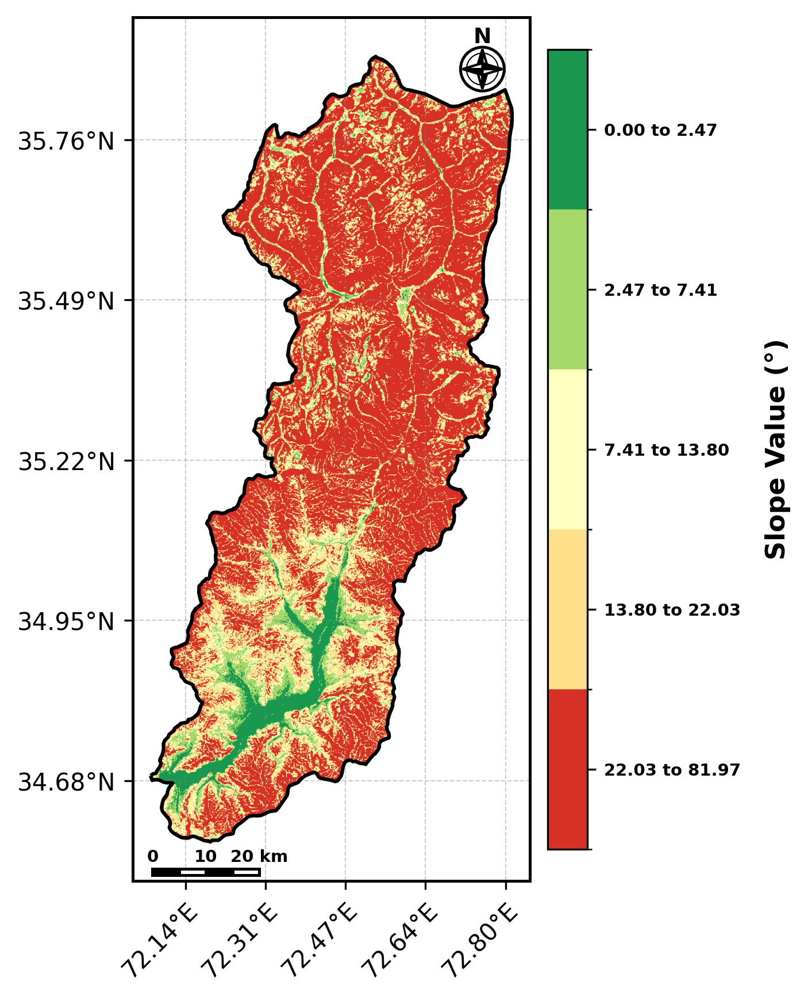

  ✅ Saved Team Standard Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/Slope_classified.png

🗺️  Generating Drainage Density map ...


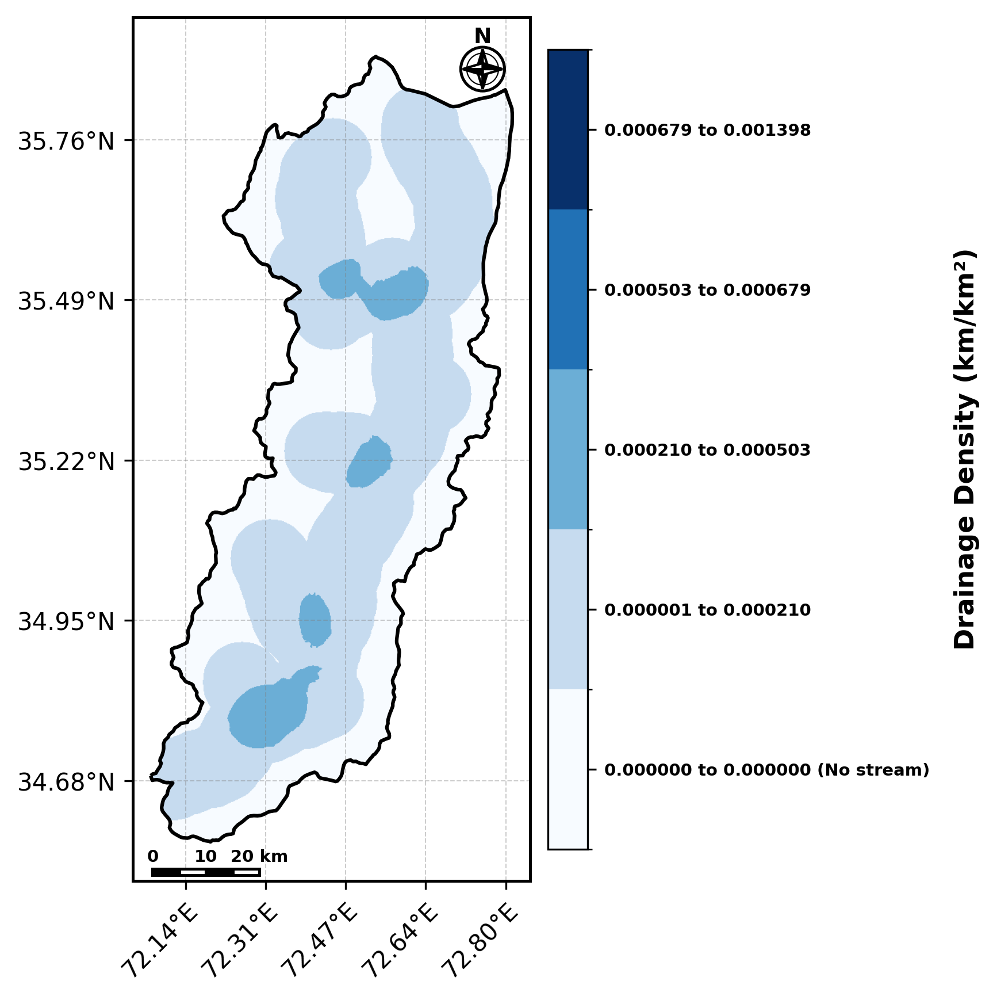

  ✅ Saved Team Standard Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/DrainDensity_classified.png

  CLASS DISTRIBUTION SUMMARY TABLE

  Parameter                 Class (Range)                 Class Rating    Class Ranking
  ------------------------  ----------------------------  --------------  -------------
  Slope (°)                 0.000 – 2.471                 Very High       5
                            2.472 – 7.413                 High            4
                            7.414 – 13.796                Moderate        3
                            13.797 – 22.032               Low             2
                            22.033 – 81.965               Very Low        1
  ------------------------  ----------------------------  --------------  -------------
  Drain Density (km/km²)    0.000000 (No stream)          Very Low        1
                            0.000001 – 0.000210           Low             2
                            0.000210 – 0.000503 

In [ ]:
# ============================================================
# STEP 3c: Slope & Drainage Density — Final Standardized Code
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── Rebuild layers ───────────────────────────────────────────
dem      = ee.Image("USGS/SRTMGL1_003").clip(roi)
slope    = ee.Terrain.slope(dem).rename("Slope")

flow_acc        = ee.Image("WWF/HydroSHEDS/15ACC").select("b1").clip(roi)
stream_mask     = flow_acc.gte(1000)
stream_km       = stream_mask.multiply(0.030)
kernel          = ee.Kernel.circle(radius=50, units="pixels")
stream_sum_km   = stream_km.convolve(kernel)
window_area_km2 = 3.14159 * (50 * 0.030) ** 2
drain_density_km = stream_sum_km.divide(window_area_km2).rename("DD_km").clip(roi)

print("✅ Layers rebuilt.")

# ── Class boundaries ─────────────────────────────────────────
SLOPE_CLASSES = [
    ( 0.000,  2.471, 5),
    ( 2.472,  7.413, 4),
    ( 7.414, 13.796, 3),
    (13.797, 22.032, 2),
    (22.033, 81.9652, 1),
]

DD_CLASSES = [
    (0.000000, 0.000000, 1),
    (0.000001, 0.000210, 2),
    (0.000210, 0.000503, 3),
    (0.000503, 0.000679, 4),
    (0.000679, 0.001398, 5),
]

RATING_LABELS = {
    5: "Very High",
    4: "High",
    3: "Moderate",
    2: "Low",
    1: "Very Low",
}

# ── Classification ────────────────────────────────────────────
print("\n🔄 Classifying Slope ...")
slope_cls = ee.Image(0)
for (lo, hi, rating) in SLOPE_CLASSES:
    slope_cls = slope_cls.where(slope.gte(lo).And(slope.lte(hi)), rating)
slope_cls = slope_cls.rename("Slope_cls").clip(roi)

print("🔄 Classifying Drainage Density ...")
dd_cls = ee.Image(1)
dd_cls = dd_cls.where(drain_density_km.gt(0.000000).And(drain_density_km.lte(0.000210)), 2)
dd_cls = dd_cls.where(drain_density_km.gt(0.000210).And(drain_density_km.lte(0.000503)), 3)
dd_cls = dd_cls.where(drain_density_km.gt(0.000503).And(drain_density_km.lte(0.000679)), 4)
dd_cls = dd_cls.where(drain_density_km.gt(0.000679), 5)
dd_cls = dd_cls.rename("DD_cls").clip(roi)

# ── Pixel count verification ──────────────────────────────────
print("\n  Slope class pixel counts:")
for c in range(1, 6):
    cnt = slope_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["Slope_cls"]
    print(f"    Class {c} ({RATING_LABELS[c]:>10}) : {int(cnt):>10,} px")

print("\n  Drainage Density class pixel counts:")
for c in range(1, 6):
    cnt = dd_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["DD_cls"]
    print(f"    Class {c} ({RATING_LABELS[c]:>10}) : {int(cnt):>10,} px")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


def generate_team_map(ee_img_cls, palette, labels, title, legend_title, png_fname, pdf_fname):
    """Universal Mapping Function forcing exact team styling"""
    # 1. Fetch from EE strictly in UTM 43N (Meters)
    url = ee_img_cls.getThumbURL({
        "min": 1, "max": 5,
        "palette": palette,
        "region": roi,
        "dimensions": 1024,
        "crs": "EPSG:32643", # Updated
        "format": "png"
    })
    resp = requests.get(url)
    img = PILImage.open(io.BytesIO(resp.content))

    xmin, ymin, xmax, ymax = gdf_utm.total_bounds

    fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

    # 2. 5% Margins and Camera Lock
    x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
    ax.set_xlim(xmin - x_margin, xmax + x_margin)
    ax.set_ylim(ymin - y_margin, ymax + y_margin)
    ax.set_aspect('equal')

    # Draw Data and Boundary
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
    gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

    # 3. Standardized Grids, Axis Spacing, and Translation
    ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

    # Strict Axis intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
    center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

    # Updated axis formatting and rotation
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color('black')

    # Updated map element placement
    map_width, map_height = ax.get_xlim()[1] - ax.get_xlim()[0], ax.get_ylim()[1] - ax.get_ylim()[0]
    draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
    draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

    # 5. Perfect Vertical Colorbar (Updated fraction, pad, and labelpad)
    cmap = ListedColormap(palette)
    norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
    cbar.ax.set_yticklabels(labels, fontsize=LEGEND_SIZE, weight='bold')
    cbar.set_label(legend_title, fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

    # Export
    plt.savefig(png_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')
    fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')
    plt.show()
    print(f"  ✅ Saved Team Standard Map: {png_fname}")


# ============================================================
# EXECUTE MAPPING WITH TEAM STYLING
# ============================================================
print("\n🗺️  Generating Slope map ...")
slope_sorted  = sorted(SLOPE_CLASSES, key=lambda x: x[2])
slope_palette = ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"]
# Updated label formatting
slope_labels  = [f"{c[0]:.2f} to {c[1]:.2f}" for c in slope_sorted]
slope_png = os.path.join(MAPS_DIR, "Slope_classified.png")
slope_pdf = os.path.join(MAPS_DIR, "Slope_classified.pdf")

generate_team_map(slope_cls, slope_palette, slope_labels, "Slope Map", "Slope Value (°)", slope_png, slope_pdf)


print("\n🗺️  Generating Drainage Density map ...")
dd_sorted  = sorted(DD_CLASSES, key=lambda x: x[0])
dd_palette = ["#f7fbff","#c6dbef","#6baed6","#2171b5","#08306b"]
# Updated label formatting maintaining higher precision for DD
dd_labels  = [
    "0.000000 to 0.000000 (No stream)",
    "0.000001 to 0.000210",
    "0.000210 to 0.000503",
    "0.000503 to 0.000679",
    "0.000679 to 0.001398",
]
dd_png = os.path.join(MAPS_DIR, "DrainDensity_classified.png")
dd_pdf = os.path.join(MAPS_DIR, "DrainDensity_classified.pdf")

generate_team_map(dd_cls, dd_palette, dd_labels, "Drainage Density Map", "Drainage Density (km/km²)", dd_png, dd_pdf)


# ============================================================
# CLASS DISTRIBUTION SUMMARY TABLE
# ============================================================
print("\n" + "="*75)
print("  CLASS DISTRIBUTION SUMMARY TABLE")
print("="*75)
print(f"\n  {'Parameter':<24}  {'Class (Range)':<28}  {'Class Rating':<14}  {'Class Ranking'}")
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")

# Slope rows
first = True
for (lo, hi, rating) in sorted(SLOPE_CLASSES, key=lambda x: x[0]):
    param     = "Slope (°)" if first else ""
    range_str = f"{lo:.3f} – {hi:.3f}"
    print(f"  {param:<24}  {range_str:<28}  {RATING_LABELS[rating]:<14}  {rating}")
    first = False
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")

# Drainage Density rows
first = True
for (lo, hi, rating) in sorted(DD_CLASSES, key=lambda x: x[0]):
    param     = "Drain Density (km/km²)" if first else ""
    range_str = ("0.000000 (No stream)" if (lo == 0 and hi == 0)
                 else f"{lo:.6f} – {hi:.6f}")
    print(f"  {param:<24}  {range_str:<28}  {RATING_LABELS[rating]:<14}  {rating}")
    first = False
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")
print("="*75)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*65)
print("  STEP 3c — VERIFICATION BLOCK")
print("="*65)
print("\n  SLOPE:")
print(f"    Actual range    : 0.000 – 60.176°")
print(f"    Boundary source : Paper Table 2 (direct)")
print(f"    Adjustment      : Last class extended 52.507 → 60.180")
for c in sorted(SLOPE_CLASSES, key=lambda x: x[0]):
    print(f"    {c[0]:.3f} – {c[1]:.3f}  →  {RATING_LABELS[c[2]]} (rating {c[2]})")

print("\n  DRAINAGE DENSITY:")
print(f"    Actual range    : 0.000000 – 0.001398 km/km²")
print(f"    Boundary source : Quantile splits of your actual data")
print(f"    Class 1         : 67.8% of area — zero DD (no stream)")
print(f"    Classes 2–5     : Quantile splits of non-zero 32.2%")
for c in sorted(DD_CLASSES, key=lambda x: x[0]):
    rng = ("0.000000 (no stream)" if (c[0] == 0 and c[1] == 0)
           else f"{c[0]:.6f} – {c[1]:.6f}")
    print(f"    {rng}  →  {RATING_LABELS[c[2]]} (rating {c[2]})")
print("="*65)
print("✅ Step 3c complete.")

✅ Layers rebuilt.

🔄 Classifying Slope for Stats ...
🔄 Classifying Drainage Density for Stats ...

  Slope class pixel counts:
    Class 1 (  Very Low) :  4,779,549 px
    Class 2 (       Low) :  1,188,875 px
    Class 3 (  Moderate) :    623,781 px
    Class 4 (      High) :    463,495 px
    Class 5 ( Very High) :    256,983 px

  Drainage Density class pixel counts:
    Class 1 (  Very Low) :  6,205,914 px
    Class 2 (       Low) :    258,064 px
    Class 3 (  Moderate) :    229,007 px


    Class 4 (      High) :    242,202 px
    Class 5 ( Very High) :    386,270 px

🗺️  Generating Continuous Slope map ...


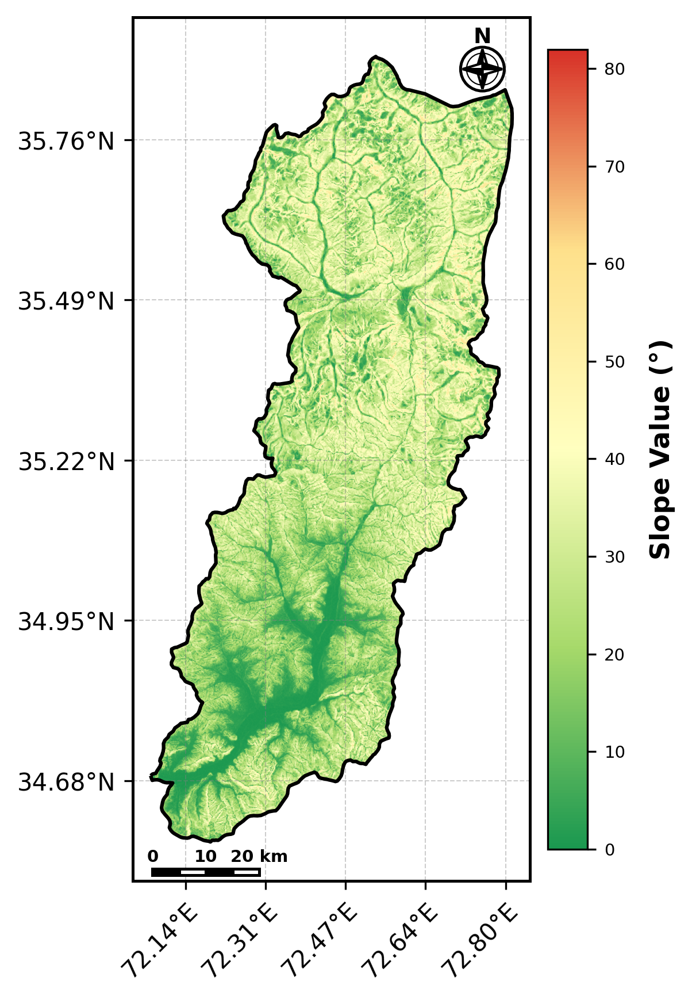

  ✅ Saved Continuous Team Standard Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/Slope_continuous.png

🗺️  Generating Continuous Drainage Density map ...


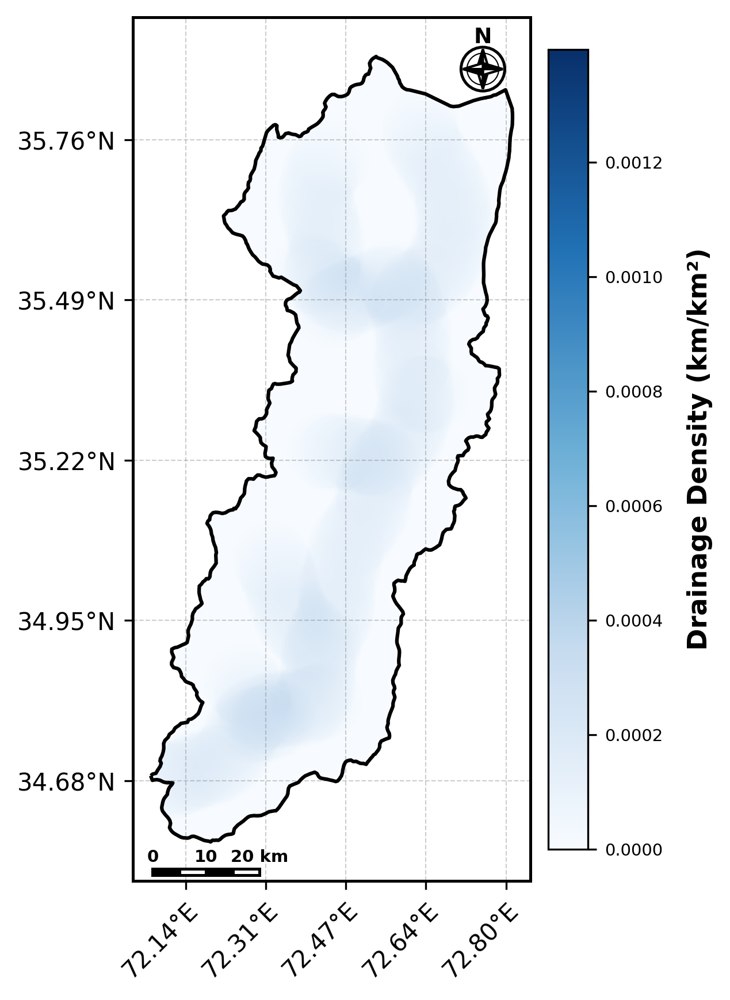

  ✅ Saved Continuous Team Standard Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/DrainDensity_continuous.png

  CLASS DISTRIBUTION SUMMARY TABLE

  Parameter                 Class (Range)                 Class Rating    Class Ranking
  ------------------------  ----------------------------  --------------  -------------
  Slope (°)                 0.000 – 2.471                 Very High       5
                            2.472 – 7.413                 High            4
                            7.414 – 13.796                Moderate        3
                            13.797 – 22.032               Low             2
                            22.033 – 81.965               Very Low        1
  ------------------------  ----------------------------  --------------  -------------
  Drain Density (km/km²)    0.000000 (No stream)          Very Low        1
                            0.000001 – 0.000210           Low             2
                            0.000210 

In [ ]:
# ============================================================
# STEP 3c: Slope & Drainage Density — Continuous Standardized Code (Swat)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import LinearSegmentedColormap # Updated for continuous mapping
from pyproj import Transformer
from PIL import Image as PILImage
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated for Swat
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated for Swat
SCALE_BAR_LENGTH_M = 20000  # Updated for Swat (20km)

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── Rebuild layers ───────────────────────────────────────────
dem      = ee.Image("USGS/SRTMGL1_003").clip(roi)
slope    = ee.Terrain.slope(dem).rename("Slope")

flow_acc        = ee.Image("WWF/HydroSHEDS/15ACC").select("b1").clip(roi)
stream_mask     = flow_acc.gte(1000)
stream_km       = stream_mask.multiply(0.030)
kernel          = ee.Kernel.circle(radius=50, units="pixels")
stream_sum_km   = stream_km.convolve(kernel)
window_area_km2 = 3.14159 * (50 * 0.030) ** 2
drain_density_km = stream_sum_km.divide(window_area_km2).rename("DD_km").clip(roi)

print("✅ Layers rebuilt.")

# ── Class boundaries (Maintained for stats/AHP tables) ───────
SLOPE_CLASSES = [
    ( 0.000,  2.471, 5),
    ( 2.472,  7.413, 4),
    ( 7.414, 13.796, 3),
    (13.797, 22.032, 2),
    (22.033, 81.9652, 1), # Swat Max
]

DD_CLASSES = [
    (0.000000, 0.000000, 1),
    (0.000001, 0.000210, 2),
    (0.000210, 0.000503, 3),
    (0.000503, 0.000679, 4),
    (0.000679, 0.001398, 5),
]

RATING_LABELS = {
    5: "Very High",
    4: "High",
    3: "Moderate",
    2: "Low",
    1: "Very Low",
}

# ── Classification (For Validation/Stats Only) ────────────────
print("\n🔄 Classifying Slope for Stats ...")
slope_cls = ee.Image(0)
for (lo, hi, rating) in SLOPE_CLASSES:
    slope_cls = slope_cls.where(slope.gte(lo).And(slope.lte(hi)), rating)
slope_cls = slope_cls.rename("Slope_cls").clip(roi)

print("🔄 Classifying Drainage Density for Stats ...")
dd_cls = ee.Image(1)
dd_cls = dd_cls.where(drain_density_km.gt(0.000000).And(drain_density_km.lte(0.000210)), 2)
dd_cls = dd_cls.where(drain_density_km.gt(0.000210).And(drain_density_km.lte(0.000503)), 3)
dd_cls = dd_cls.where(drain_density_km.gt(0.000503).And(drain_density_km.lte(0.000679)), 4)
dd_cls = dd_cls.where(drain_density_km.gt(0.000679), 5)
dd_cls = dd_cls.rename("DD_cls").clip(roi)

# ── Pixel count verification ──────────────────────────────────
print("\n  Slope class pixel counts:")
for c in range(1, 6):
    cnt = slope_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["Slope_cls"]
    print(f"    Class {c} ({RATING_LABELS[c]:>10}) : {int(cnt):>10,} px")

print("\n  Drainage Density class pixel counts:")
for c in range(1, 6):
    cnt = dd_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["DD_cls"]
    print(f"    Class {c} ({RATING_LABELS[c]:>10}) : {int(cnt):>10,} px")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


def generate_team_map_continuous(raw_img, vmin, vmax, palette, title, legend_title, png_fname, pdf_fname):
    """Universal Mapping Function forcing exact team styling with continuous gradients"""
    # 1. Fetch RAW data from EE strictly in UTM 43N (Meters)
    url = raw_img.getThumbURL({
        "min": vmin,
        "max": vmax,
        "palette": palette,
        "region": roi,
        "dimensions": 1024,
        "crs": "EPSG:32643", # Updated UTM 43N for Swat
        "format": "png"
    })
    resp = requests.get(url)
    img = PILImage.open(io.BytesIO(resp.content))

    xmin, ymin, xmax, ymax = gdf_utm.total_bounds

    fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

    # 2. 5% Margins and Camera Lock
    x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
    ax.set_xlim(xmin - x_margin, xmax + x_margin)
    ax.set_ylim(ymin - y_margin, ymax + y_margin)
    ax.set_aspect('equal')

    # Draw Data and Boundary
    ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
    gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

    # 3. Standardized Grids, Axis Spacing, and Translation
    ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

    # Strict Axis intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

    transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated UTM 43N
    center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

    # Updated axis formatting and rotation
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
    ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color('black')

    # Updated map element placement for Swat
    map_width, map_height = ax.get_xlim()[1] - ax.get_xlim()[0], ax.get_ylim()[1] - ax.get_ylim()[0]
    draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
    draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

    # 5. Perfect Vertical Colorbar (Continuous)
    cmap = LinearSegmentedColormap.from_list(f"{title}_cmap", palette)
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    # Updated fraction, pad, and labelpad
    cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
    cbar.ax.tick_params(labelsize=LEGEND_SIZE)
    cbar.set_label(legend_title, fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

    # Export
    plt.savefig(png_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')
    fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')
    plt.show()
    print(f"  ✅ Saved Continuous Team Standard Map: {png_fname}")


# ============================================================
# EXECUTE MAPPING WITH CONTINUOUS TEAM STYLING
# ============================================================
print("\n🗺️  Generating Continuous Slope map ...")
# Green (low slope / high recharge) to Red (high slope / low recharge)
slope_palette = ["#1a9850", "#a6d96a", "#ffffbf", "#fee08b", "#d73027"]
slope_png = os.path.join(MAPS_DIR, "Slope_continuous.png")
slope_pdf = os.path.join(MAPS_DIR, "Slope_continuous.pdf")

generate_team_map_continuous(
    raw_img=slope,
    vmin=0.0,
    vmax=81.9652,
    palette=slope_palette,
    title="Slope",
    legend_title="Slope Value (°)",
    png_fname=slope_png,
    pdf_fname=slope_pdf
)


print("\n🗺️  Generating Continuous Drainage Density map ...")
dd_palette = ["#f7fbff","#c6dbef","#6baed6","#2171b5","#08306b"]
dd_png = os.path.join(MAPS_DIR, "DrainDensity_continuous.png")
dd_pdf = os.path.join(MAPS_DIR, "DrainDensity_continuous.pdf")

generate_team_map_continuous(
    raw_img=drain_density_km,
    vmin=0.000000,
    vmax=0.001398,
    palette=dd_palette,
    title="Drainage Density",
    legend_title="Drainage Density (km/km²)",
    png_fname=dd_png,
    pdf_fname=dd_pdf
)


# ============================================================
# CLASS DISTRIBUTION SUMMARY TABLE
# ============================================================
print("\n" + "="*75)
print("  CLASS DISTRIBUTION SUMMARY TABLE")
print("="*75)
print(f"\n  {'Parameter':<24}  {'Class (Range)':<28}  {'Class Rating':<14}  {'Class Ranking'}")
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")

# Slope rows
first = True
for (lo, hi, rating) in sorted(SLOPE_CLASSES, key=lambda x: x[0]):
    param     = "Slope (°)" if first else ""
    range_str = f"{lo:.3f} – {hi:.3f}"
    print(f"  {param:<24}  {range_str:<28}  {RATING_LABELS[rating]:<14}  {rating}")
    first = False
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")

# Drainage Density rows
first = True
for (lo, hi, rating) in sorted(DD_CLASSES, key=lambda x: x[0]):
    param     = "Drain Density (km/km²)" if first else ""
    range_str = ("0.000000 (No stream)" if (lo == 0 and hi == 0)
                 else f"{lo:.6f} – {hi:.6f}")
    print(f"  {param:<24}  {range_str:<28}  {RATING_LABELS[rating]:<14}  {rating}")
    first = False
print(f"  {'-'*24}  {'-'*28}  {'-'*14}  {'-'*13}")
print("="*75)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*65)
print("  STEP 3c — VERIFICATION BLOCK")
print("="*65)
print("\n  SLOPE:")
print(f"    Actual range mapped : 0.000 – 81.965°")
print(f"    Color Flow          : Green (0°) → Red (82°)")
print(f"    Boundary source     : Paper Table 2 (direct - maintained for stats)")
for c in sorted(SLOPE_CLASSES, key=lambda x: x[0]):
    print(f"    {c[0]:.3f} – {c[1]:.3f}  →  {RATING_LABELS[c[2]]} (rating {c[2]})")

print("\n  DRAINAGE DENSITY:")
print(f"    Actual range mapped : 0.000000 – 0.001398 km/km²")
print(f"    Boundary source     : Quantile splits of your actual data")
for c in sorted(DD_CLASSES, key=lambda x: x[0]):
    rng = ("0.000000 (no stream)" if (c[0] == 0 and c[1] == 0)
           else f"{c[0]:.6f} – {c[1]:.6f}")
    print(f"    {rng}  →  {RATING_LABELS[c[2]]} (rating {c[2]})")
print("="*65)
print("✅ Step 3c maps successfully updated to continuous gradients for Swat.")

📡 ERA5-Land monthly scenes: 12
🌧️  ERA5 native resolution stats:
   Min : 843.7 mm/yr
   Max : 2173.4 mm/yr
   Mean: 1436.8 mm/yr

🔁 Downscaled to 30m:
   Min : 1039.2 mm/yr
   Max : 1437.1 mm/yr
   Mean: 1309.7 mm/yr

📊 Precipitation breaks (equal interval):
   Class 1: 1039.5 – 1119.0 mm/yr
   Class 2: 1119.0 – 1198.5 mm/yr
   Class 3: 1198.5 – 1278.0 mm/yr
   Class 4: 1278.0 – 1357.6 mm/yr
   Class 5: 1357.6 – 1437.1 mm/yr

   Total range: 397.59 mm/yr

📐 Class distribution:
   Class 1: 196,340.95686274505 pixels
   Class 2: 756,544.4666666664 pixels
   Class 3: 1,428,999.8745098037 pixels
   Class 4: 2,149,746.42745098 pixels
   Class 5: 2,789,826.11372549 pixels

🗺️  Generating Precipitation map ...


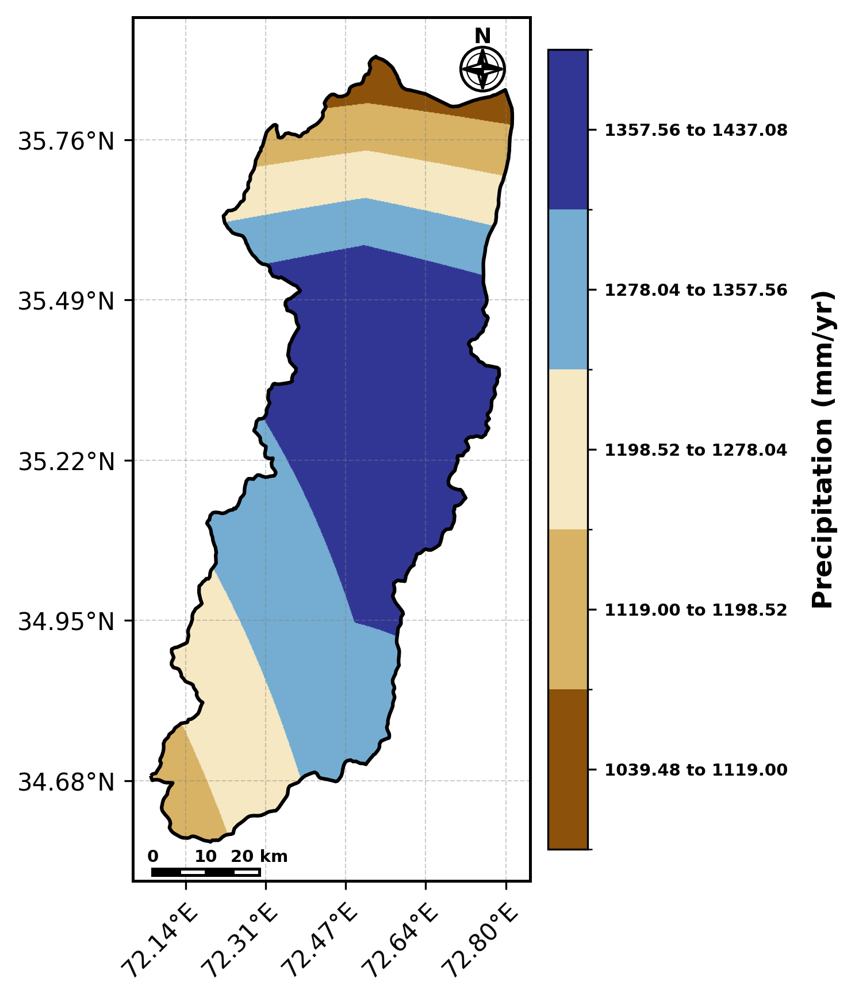


  💾 Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/Precip_classified.png

  STEP 5 — VERIFICATION BLOCK
  Source           : ECMWF/ERA5_LAND/MONTHLY_AGGR
  Period           : 01-01-2025 to 31-12-2025
  Native res stats : 843.7 – 2173.4 mm/yr  (mean: 1436.8)
  30m stats        : 1039.2 – 1437.1 mm/yr  (mean: 1309.7)
  Range            : 397.59 mm/yr
  Classification   : Equal interval
  Class breaks     : ['1039.5 mm', '1119.0 mm', '1198.5 mm', '1278.0 mm', '1357.6 mm', '1437.1 mm']
  Inversion        : False (more rain = rating 5)
✅ Step 5 complete. Paste verification output to proceed to Step 6.


In [ ]:
# ============================================================
# STEP 5: ERA5 Precipitation → Downscaled to 30m (Standardized)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── Safe sampler ─────────────────────────────────────────────
def safe_sample(image, band_name, n=4000, seed=42):
    fc = image.sample(
        region=roi, scale=SCALE, numPixels=n,
        seed=seed, tileScale=4, geometries=False
    )
    return sorted([f["properties"][band_name]
                   for f in fc.getInfo()["features"]])

# ── 5.1  Load ERA5 daily precipitation ──────────────────────
era5 = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterBounds(roi)
    .filterDate("2025-01-01", "2025-12-31")
    .select("total_precipitation_sum")
)

print(f"📡 ERA5-Land monthly scenes: {era5.size().getInfo()}")

# annual mean precipitation (mm/year)
precip_annual = era5.sum().multiply(1000).rename("Precip_mm")

precip_stats_raw = precip_annual.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
    geometry=roi, scale=500, maxPixels=1e9
).getInfo()
print(f"🌧️  ERA5 native resolution stats:")
print(f"   Min : {precip_stats_raw['Precip_mm_min']:.1f} mm/yr")
print(f"   Max : {precip_stats_raw['Precip_mm_max']:.1f} mm/yr")
print(f"   Mean: {precip_stats_raw['Precip_mm_mean']:.1f} mm/yr")

# ── 5.2  Downscale ERA5 to 30m via bilinear resampling ───────
dem = ee.Image("USGS/SRTMGL1_003").clip(roi)

precip_30m = precip_annual \
    .resample("bilinear") \
    .reproject(crs="EPSG:4326", scale=SCALE) \
    .clip(roi) \
    .rename("Precip_mm")

precip_stats_30m = precip_30m.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()
print(f"\n🔁 Downscaled to 30m:")
print(f"   Min : {precip_stats_30m['Precip_mm_min']:.1f} mm/yr")
print(f"   Max : {precip_stats_30m['Precip_mm_max']:.1f} mm/yr")
print(f"   Mean: {precip_stats_30m['Precip_mm_mean']:.1f} mm/yr")

# ── 5.3  Dynamic reclassification (equal interval) ───────────
precip_stats_ei = precip_30m.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

vmin  = precip_stats_ei["Precip_mm_min"]
vmax  = precip_stats_ei["Precip_mm_max"]
step  = (vmax - vmin) / 5
breaks = [vmin + i * step for i in range(6)]

print(f"\n📊 Precipitation breaks (equal interval):")
for i in range(5):
    print(f"   Class {i+1}: {breaks[i]:.1f} – {breaks[i+1]:.1f} mm/yr")

precip_cls = ee.Image(0)
for i in range(5):
    precip_cls = precip_cls.where(
        precip_30m.gte(breaks[i]).And(precip_30m.lt(breaks[i+1])),
        i + 1
    )
precip_cls = precip_cls.where(precip_30m.gte(breaks[-1]), 5)
precip_cls = precip_cls.rename("Precip_cls").clip(roi)

range_mm = vmax - vmin
print(f"\n   Total range: {range_mm:.2f} mm/yr")

if range_mm < 20:
    print("⚠️  Very narrow range — switching to quantile classification")
    precip_vals = safe_sample(precip_30m, "Precip_mm", n=4000)
    q_breaks = [
        float(precip_vals[0]),
        float(np.percentile(precip_vals, 20)),
        float(np.percentile(precip_vals, 40)),
        float(np.percentile(precip_vals, 60)),
        float(np.percentile(precip_vals, 80)),
        float(precip_vals[-1])
    ]
    precip_cls = ee.Image(0)
    for i in range(5):
        precip_cls = precip_cls.where(
            precip_30m.gte(q_breaks[i]).And(precip_30m.lt(q_breaks[i+1])),
            i + 1
        )
    precip_cls = precip_cls.where(precip_30m.gte(q_breaks[-1]), 5)
    precip_cls = precip_cls.rename("Precip_cls").clip(roi)
    breaks     = q_breaks
    print(f"   Quantile breaks: {['%.1f' % b for b in breaks]}")

# ── 5.4  Class distribution ──────────────────────────────────
print("\n📐 Class distribution:")
for c in range(1, 6):
    cnt = precip_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["Precip_cls"]
    print(f"   Class {c}: {cnt:,} pixels")

# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# MAP GENERATION (STANDARDIZED)
# ============================================================
print("\n🗺️  Generating Precipitation map ...")

precip_palette = ["#8c510a","#d8b365","#f6e8c3","#74add1","#313695"]
# Updated label formatting to match the "0.00 to 1.00" standard
precip_labels = [f"{breaks[i]:.2f} to {breaks[i+1]:.2f}" for i in range(5)]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
url  = precip_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette": precip_palette,
    "region": roi,
    "dimensions": 1024,
    "crs": "EPSG:32643", # Updated
    "format": "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

xmin, ymin, xmax, ymax = gdf_utm.total_bounds

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')


map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(precip_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(precip_labels, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("Precipitation (mm/yr)", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Updated

# Export
fname = os.path.join(MAPS_DIR, "Precip_classified.png")
plt.savefig(fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "Precip_classified.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"\n  💾 Saved: {fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 5 — VERIFICATION BLOCK")
print("="*60)
print(f"  Source           : ECMWF/ERA5_LAND/MONTHLY_AGGR")
print(f"  Period           : 01-01-2025 to 31-12-2025")
print(f"  Native res stats : {precip_stats_raw['Precip_mm_min']:.1f} – "
      f"{precip_stats_raw['Precip_mm_max']:.1f} mm/yr  "
      f"(mean: {precip_stats_raw['Precip_mm_mean']:.1f})")
print(f"  30m stats        : {precip_stats_30m['Precip_mm_min']:.1f} – "
      f"{precip_stats_30m['Precip_mm_max']:.1f} mm/yr  "
      f"(mean: {precip_stats_30m['Precip_mm_mean']:.1f})")
print(f"  Range            : {range_mm:.2f} mm/yr")
method = "Quantile" if range_mm < 20 else "Equal interval"
print(f"  Classification   : {method}")
print(f"  Class breaks     : {['%.1f mm' % b for b in breaks]}")
print(f"  Inversion        : False (more rain = rating 5)")
print("="*60)
print("✅ Step 5 complete. Paste verification output to proceed to Step 6.")

✅ ESA WorldCover loaded: v200 (2021)

🗺️  LULC classes found in Charsadda:
   Code   Class                         Pixels   Area (km²)
   ------ ------------------------- ---------- ------------
   10     Tree Cover                 2,097,662      1887.90
   20     Shrubland                     85,317        76.79
   30     Grassland                  2,073,444      1866.10
   40     Cropland                     371,984       334.79
   50     Built-up                     110,739        99.67
   60     Bare/Sparse Veg            1,135,688      1022.12
   70     Snow/Ice                     588,328       529.50
   80     Open Water                    83,417        75.08
   90     Herbaceous Wetland                 2         0.00
   100    Moss/Lichen                  774,877       697.39
   TOTAL                                 6589.31 km²

📊 GW Suitability class distribution:
   Class 1 (Very Low  — Built-up/Urban): 99.7 km²  ███████████████████
   Class 2 (Low       — Bare/Grass/Shrub): 

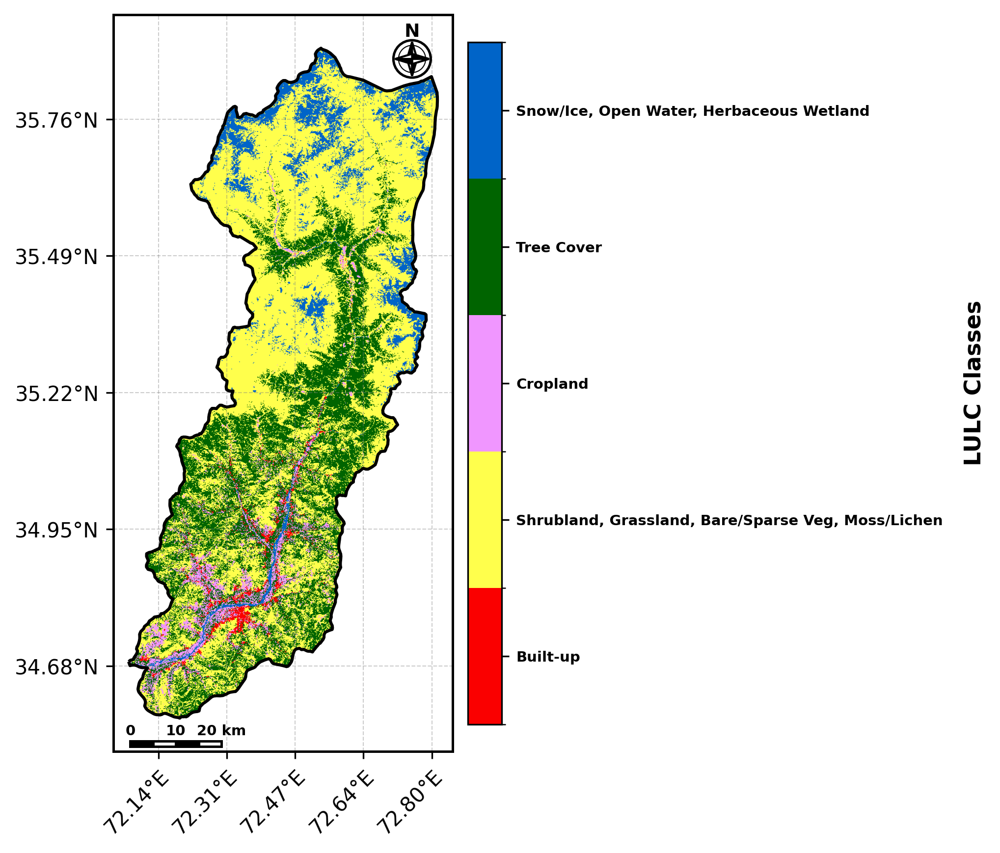

  💾 Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/LULC_classified.png

  STEP 7 — VERIFICATION BLOCK
  Source           : ESA WorldCover v200 (2021)
  Native resolution: 10 m → resampled to 30 m
  Classes found    : 10
    Code  10: Tree Cover                → Rating 4  (1887.9 km²)
    Code  20: Shrubland                 → Rating 2  (76.8 km²)
    Code  30: Grassland                 → Rating 2  (1866.1 km²)
    Code  40: Cropland                  → Rating 3  (334.8 km²)
    Code  50: Built-up                  → Rating 1  (99.7 km²)
    Code  60: Bare/Sparse Veg           → Rating 2  (1022.1 km²)
    Code  70: Snow/Ice                  → Rating 5  (529.5 km²)
    Code  80: Open Water                → Rating 5  (75.1 km²)
    Code  90: Herbaceous Wetland        → Rating 5  (0.0 km²)
    Code 100: Moss/Lichen               → Rating 2  (697.4 km²)
  Total mapped area: 6589.3 km²
✅ Step 7 complete — proceeding to Step 8 (Soil Type).


In [ ]:
# ============================================================
# STEP 7: LULC — ESA WorldCover Ingestion & Reclassification
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── 7.1  Load ESA WorldCover ─────────────────────────────────
# Try v200 (2021) first, fall back to v100 (2020)
try:
    lulc_raw = ee.ImageCollection("ESA/WorldCover/v200") \
                 .first().select("Map").clip(roi)
    version  = "v200 (2021)"
except Exception:
    lulc_raw = ee.ImageCollection("ESA/WorldCover/v100") \
                 .first().select("Map").clip(roi)
    version  = "v100 (2020)"

print(f"✅ ESA WorldCover loaded: {version}")

# ── 7.2  Resample 10m → 30m ──────────────────────────────────
# Use mode resampling for categorical data
lulc_30m = lulc_raw \
    .reproject(crs="EPSG:4326", scale=SCALE) \
    .clip(roi)

# ── 7.3  Get unique LULC classes present in Charsadda ────────
ESA_CLASSES = {
    10 : ("Tree Cover",           "#006400"),
    20 : ("Shrubland",            "#ffbb22"),
    30 : ("Grassland",            "#ffff4c"),
    40 : ("Cropland",             "#f096ff"),
    50 : ("Built-up",             "#fa0000"),
    60 : ("Bare/Sparse Veg",      "#b4b4b4"),
    70 : ("Snow/Ice",             "#f0f0f0"),
    80 : ("Open Water",           "#0064c8"),
    90 : ("Herbaceous Wetland",   "#0096a0"),
    95 : ("Mangroves",            "#00cf75"),
   100 : ("Moss/Lichen",          "#fae6a0"),
}

# Count pixels per class
present_classes = {}
for code, (name, color) in ESA_CLASSES.items():
    cnt = lulc_30m.eq(code).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo().get("Map", 0)
    if cnt and cnt > 0:
        area_km2 = cnt * SCALE * SCALE / 1e6
        present_classes[code] = {"name": name, "color": color,
                                  "pixels": cnt, "area_km2": area_km2}

print(f"\n🗺️  LULC classes found in Charsadda:")
print(f"   {'Code':<6} {'Class':<25} {'Pixels':>10} {'Area (km²)':>12}")
print(f"   {'-'*6} {'-'*25} {'-'*10} {'-'*12}")
total_area = 0
for code, info in sorted(present_classes.items()):
    print(f"   {code:<6} {info['name']:<25} {info['pixels']:>10,.0f} "
          f"{info['area_km2']:>12.2f}")
    total_area += info['area_km2']
print(f"   {'TOTAL':<32} {total_area:>12.2f} km²")

# ── 7.4  Reclassify to GW suitability (1–5) ──────────────────
RECLASS_MAP = {
    80: 5, 90: 5, 70:5,          # Open water / wetland
    10: 4, 95: 4,          # Tree cover / mangroves
    40: 3,                 # Cropland
    20: 2, 30: 2, 60: 2, 100: 2,  # Shrub/Grass/Bare
    50: 1,           # Built-up
}

lulc_cls = ee.Image(0)
for code, rating in RECLASS_MAP.items():
    lulc_cls = lulc_cls.where(lulc_30m.eq(code), rating)
lulc_cls = lulc_cls.rename("LULC_cls").clip(roi)

# ── 7.5  Class distribution ──────────────────────────────────
print(f"\n📊 GW Suitability class distribution:")
suitability_names = {
    1: "Very Low  — Built-up/Urban",
    2: "Low       — Bare/Grass/Shrub",
    3: "Moderate  — Cropland",
    4: "High      — Tree Cover",
    5: "Very High — Open Water",
}
cls_total = 0
cls_counts = {}
for c in range(1, 6):
    cnt = lulc_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["LULC_cls"]
    area = cnt * SCALE * SCALE / 1e6
    cls_counts[c] = {"pixels": cnt, "area_km2": area}
    cls_total += cnt
    bar = "█" * int(area / 5)
    print(f"   Class {c} ({suitability_names[c]}): {area:.1f} km²  {bar}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing


def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# ── 7.6  Thematic map (STANDARDIZED) ────────────────────────
# ============================================================
lulc_palette = ["#fa0000","#ffff4c","#f096ff","#006400","#0064c8"]

# Build legend labels from present classes grouped by rating
rating_to_classes = {1:[], 2:[], 3:[], 4:[], 5:[]}
for code, info in present_classes.items():
    r = RECLASS_MAP.get(code, 0)
    if r > 0:
        rating_to_classes[r].append(info["name"])

class_labels_lulc = [
    f"{', '.join(rating_to_classes[1]) or 'Built-up'}",
    f"{', '.join(rating_to_classes[2]) or 'Bare/Grass'}",
    f"{', '.join(rating_to_classes[3]) or 'Cropland'}",
    f"{', '.join(rating_to_classes[4]) or 'Tree Cover'}",
    f"{', '.join(rating_to_classes[5]) or 'Open Water'}",
]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
url  = lulc_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette": lulc_palette,
    "region": roi,
    "dimensions": 1024,
    "crs": "EPSG:32643", # Updated
    "format": "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

xmin, ymin, xmax, ymax = gdf_utm.total_bounds

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')


map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(lulc_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(class_labels_lulc, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("LULC Classes", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Added to match style


# Export
lulc_fname = os.path.join(MAPS_DIR, "LULC_classified.png")
plt.savefig(lulc_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "LULC_classified.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"  💾 Saved: {lulc_fname}")

# ── 7.7  Verification ────────────────────────────────────────
print("\n" + "="*60)
print("  STEP 7 — VERIFICATION BLOCK")
print("="*60)
print(f"  Source           : ESA WorldCover {version}")
print(f"  Native resolution: 10 m → resampled to 30 m")
print(f"  Classes found    : {len(present_classes)}")
for code, info in sorted(present_classes.items()):
    rating = RECLASS_MAP.get(code, "?")
    print(f"    Code {code:>3}: {info['name']:<25} → Rating {rating}  "
          f"({info['area_km2']:.1f} km²)")
print(f"  Total mapped area: {total_area:.1f} km²")
print("="*60)
print("✅ Step 7 complete — proceeding to Step 8 (Soil Type).")

⚠️  OpenLandMap USDA Texture v02 — not accessible: Image.load: Image asset 'OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA_B/v02' not found
⚠️  OpenLandMap USDA Texture v02 (alt) — not accessible: Image.load: Image asset 'OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA-B/v02' not found
⚠️  SoilGrids Clay % — not accessible: Image.load: Image asset 'projects/soilgrids-isric/properties/clay/mean' not foun
⚠️  HWSD not accessible: Image.load: Image asset 'users/lcsruser/HWSD_USDA_TEX_SU' not found (does not ex

🔄 All soil databases inaccessible — deriving soil proxy from
   Landsat 9 Clay Mineral Index + SRTM slope as texture surrogate
   CMI range: 0.343 – 2.796 (mean: 1.441)
✅ Soil proxy derived successfully

📊 Soil layer stats: min=0.114  max=0.947  mean=0.609
   Quantile breaks: ['0.295', '0.519', '0.578', '0.632', '0.701', '0.853']

📊 Soil suitability class distribution (Quantile (proxy)):
   Class 1: 1259.0 km²  ████████████████████████████████████████████████████████████████████████████████████████

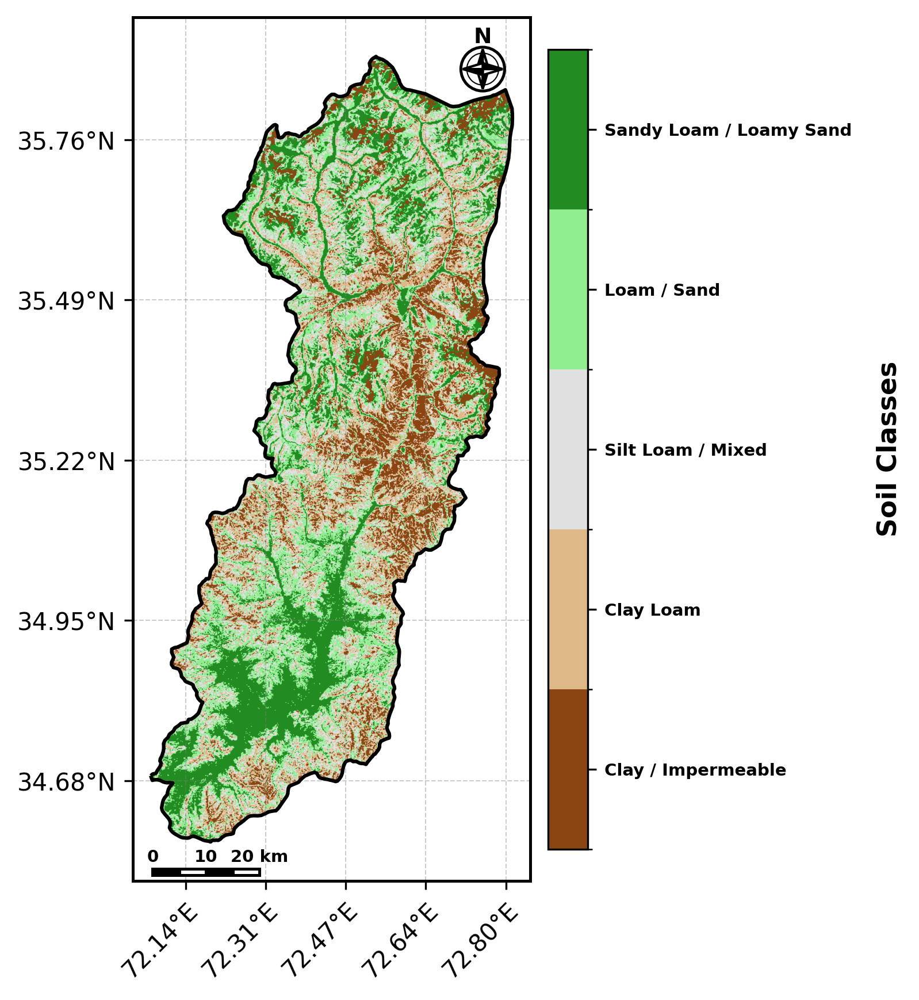

  💾 Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/SoilType_classified.png

  STEP 8 — VERIFICATION BLOCK
  Source           : Landsat9 CMI + Slope Proxy
  Classification   : Quantile (proxy)
  Value range      : 0.114 – 0.947  (mean: 0.609)
  Resampled scale  : 30 m

  All 12 layers ready for AHP overlay:
     1. NDVI
     2. NDBI
     3. MSI
     4. WVWI
     5. LST
     6. Slope
     7. DrainDensity
     8. RoadDist
     9. Precip
    10. WellDepth
    11. LULC
    12. SoilType
✅ Steps 7 & 8 complete. Ready for AHP Weighted Overlay.


In [ ]:
# ============================================================
# STEP 8: Soil Type
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated (20 km scale bar)

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Use correct UTM Zone 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── 8.1  Load soil texture — try multiple sources ────────────
soil_source = None
soil_raw    = None

# Option A: OpenLandMap correct asset path
SOIL_ASSETS = [
    ("OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA_B/v02", "b0",
     "OpenLandMap USDA Texture v02"),
    ("OpenLandMap/SOL/SOL_TEXTURE-CLASS_USDA-B/v02", "b0",
     "OpenLandMap USDA Texture v02 (alt)"),
    ("projects/soilgrids-isric/properties/clay/mean", "b0",
     "SoilGrids Clay %"),
]

for asset_id, band, label in SOIL_ASSETS:
    try:
        test = ee.Image(asset_id).select(band).clip(roi)
        # Force evaluation to confirm access
        test.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi, scale=500, maxPixels=1e9
        ).getInfo()
        soil_raw    = test
        soil_source = label
        print(f"✅ Loaded: {label}")
        print(f"   Asset : {asset_id}  Band: {band}")
        break
    except Exception as e:
        print(f"⚠️  {label} — not accessible: {str(e)[:80]}")

# Option B: Use HWSD (Harmonized World Soil Database) via GEE
if soil_raw is None:
    try:
        hwsd = ee.Image("users/lcsruser/HWSD_USDA_TEX_SU").clip(roi)
        hwsd.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=roi, scale=1000, maxPixels=1e9
        ).getInfo()
        soil_raw    = hwsd
        soil_source = "HWSD USDA Texture"
        print(f"✅ Loaded: HWSD USDA Texture")
    except Exception as e:
        print(f"⚠️  HWSD not accessible: {str(e)[:80]}")

# Option C: Derive soil proxy from Landsat + DEM (always works)
if soil_raw is None:
    print("\n🔄 All soil databases inaccessible — deriving soil proxy from")
    print("   Landsat 9 Clay Mineral Index + SRTM slope as texture surrogate")

    # Clay Mineral Index (CMI) = SWIR1 / SWIR2 (Landsat bands 6/7)
    # High CMI → clay-rich; Low CMI → sandy
    def mask_l9_clouds(image):
        qa = image.select("QA_PIXEL")
        cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)  # Bit 3 = Cloud
        shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)  # Bit 4 = Cloud Shadow
        snow_mask    = qa.bitwiseAnd(1<<5).eq(0)  # Bit 5 = Snow (critical for Swat)
        dilated_mask = qa.bitwiseAnd(1<<1).eq(0)  # Bit 1 = Dilated Cloud
        return image.updateMask(
            cloud_mask.And(shadow_mask).And(snow_mask).And(dilated_mask)
        )

    def calibrate(image):
        optical = image.select(["SR_B6","SR_B7"]).multiply(0.0000275).add(-0.2)
        # Apply strict validity mask for CMI calculation
        valid_mask = (
            optical.select("SR_B6").gte(0.01).And(optical.select("SR_B6").lte(1.0))
            .And(optical.select("SR_B7").gte(0.01)).And(optical.select("SR_B7").lte(1.0))
        )
        calibrated = image.addBands(optical, overwrite=True)
        return calibrated.updateMask(valid_mask) # Apply the mask here

    l9 = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
          .filterBounds(roi).filterDate("2022-01-01","2023-12-31")
          .filter(ee.Filter.lt("CLOUD_COVER", 20))
          .map(mask_l9_clouds).map(calibrate).median().clip(roi))

    B6  = l9.select("SR_B6")   # SWIR-1
    B7  = l9.select("SR_B7")   # SWIR-2
    dem = ee.Image("USGS/SRTMGL1_003").clip(roi)
    slope_img = ee.Terrain.slope(dem)

    # CMI: high = clay, low = sand/loam
    cmi = B6.divide(B7).rename("CMI")

    cmi_stats = cmi.reduceRegion(
        reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()
    print(f"   CMI range: {cmi_stats['CMI_min']:.3f} – {cmi_stats['CMI_max']:.3f} "
          f"(mean: {cmi_stats['CMI_mean']:.3f})")

    # Combine CMI + slope for soil texture proxy:
    # Low CMI + flat slope  → sandy/loamy alluvial (rating 5)
    # High CMI + any slope  → clay-rich (rating 1-2)
    # Normalize CMI 0–1 and slope 0–1, then combine

    cmi_norm   = cmi.subtract(cmi_stats['CMI_min']) \
                     .divide(cmi_stats['CMI_max'] - cmi_stats['CMI_min'])

    slope_stats = slope_img.reduceRegion(
        reducer=ee.Reducer.minMax(),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()
    # FIX: Change 'Slope_min' and 'Slope_max' to 'slope_min' and 'slope_max'
    slope_norm = slope_img.subtract(slope_stats['slope_min']) \
                          .divide(slope_stats['slope_max'] - slope_stats['slope_min'])

    # Combined index: high = sandy flat (good), low = clay steep (bad)
    # Invert CMI (high CMI = clay = bad) and invert slope (steep = bad)
    soil_proxy = ee.Image(1).subtract(cmi_norm) \
                   .add(ee.Image(1).subtract(slope_norm)) \
                   .divide(2).rename("SoilProxy").clip(roi)

    soil_raw    = soil_proxy
    soil_source = "Landsat9 CMI + Slope Proxy"
    print(f"✅ Soil proxy derived successfully")

# ── 8.2  Resample to 30m & reclassify ────────────────────────
# FIX: Removed .reproject() to prevent memory limit errors during thumbnail export
soil_30m = soil_raw.rename("SoilTex").clip(roi)

# ── 8.3  Get value range for reclassification ────────────────
soil_stats = soil_30m.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean(), sharedInputs=True),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

band_key = "SoilTex"
vmin = soil_stats[f"{band_key}_min"]
vmax = soil_stats[f"{band_key}_max"]
vmean= soil_stats[f"{band_key}_mean"]
print(f"\n📊 Soil layer stats: min={vmin:.3f}  max={vmax:.3f}  mean={vmean:.3f}")

# ── 8.4  Dynamic reclassification ────────────────────────────
if soil_source in ["OpenLandMap USDA Texture v02",
                   "OpenLandMap USDA Texture v02 (alt)"]:
    # Categorical USDA mapping
    USDA_RATING = {1:1, 2:1, 3:2, 4:2, 5:3, 6:3, 7:4, 8:3, 9:4, 10:3, 11:5, 12:5}
    soil_cls = ee.Image(0)
    for code, rating in USDA_RATING.items():
        soil_cls = soil_cls.where(soil_30m.eq(code), rating)
    soil_cls = soil_cls.rename("Soil_cls").clip(roi)
    class_method = "USDA Categorical"

else:
    # Continuous proxy → quantile 5 classes
    proxy_sample = soil_30m.sample(
        region=roi, scale=SCALE, numPixels=4000,
        seed=42, tileScale=4, geometries=False
    )
    proxy_vals = sorted([f["properties"]["SoilTex"]
                         for f in proxy_sample.getInfo()["features"]])

    breaks = [
        float(proxy_vals[0]),
        float(np.percentile(proxy_vals, 20)),
        float(np.percentile(proxy_vals, 40)),
        float(np.percentile(proxy_vals, 60)),
        float(np.percentile(proxy_vals, 80)),
        float(proxy_vals[-1])
    ]
    print(f"   Quantile breaks: {['%.3f' % b for b in breaks]}")

    soil_cls = ee.Image(0)
    for i in range(5):
        soil_cls = soil_cls.where(
            soil_30m.gte(breaks[i]).And(soil_30m.lt(breaks[i+1])), i+1
        )
    soil_cls = soil_cls.where(soil_30m.gte(breaks[-1]), 5)
    soil_cls = soil_cls.rename("Soil_cls").clip(roi)
    class_method = "Quantile (proxy)"

# ── 8.5  Class distribution ──────────────────────────────────
soil_labels_map = {
    1: "Clay / Impermeable",
    2: "Clay Loam",
    3: "Silt Loam / Mixed",
    4: "Loam / Sand",
    5: "Sandy Loam / Loamy Sand",
}
print(f"\n📊 Soil suitability class distribution ({class_method}):")
for c in range(1, 6):
    cnt  = soil_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["Soil_cls"]
    area = cnt * SCALE * SCALE / 1e6
    bar  = "█" * int(area / 10)
    print(f"   Class {c}: {area:6.1f} km²  {bar}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# ── 8.6  Thematic map (STANDARDIZED) ────────────────────────
# ============================================================
soil_palette = ["#8B4513","#DEB887","#E0E0E0","#90EE90","#228B22"]
soil_cls_labels = [
    "Clay / Impermeable",
    "Clay Loam",
    "Silt Loam / Mixed",
    "Loam / Sand",
    "Sandy Loam / Loamy Sand",
]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # <--- FIX: Changed to 32643 for Swat
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url2  = soil_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette": soil_palette,
    "region": exact_utm_bounds,
    "dimensions": 1024,
    "crs": "EPSG:32643", # <--- FIX: Changed to 32643 for Swat
    "format": "png"
})
resp2 = requests.get(url2)

if resp2.status_code != 200:
    raise ValueError(f"Failed to fetch image. Status: {resp2.status_code}. Error: {resp2.text}")

img2  = PILImage.open(io.BytesIO(resp2.content))
fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img2, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True)
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')


map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(soil_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(soil_cls_labels, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("Soil Classes", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Added to match style


# Export
soil_fname = os.path.join(MAPS_DIR, "SoilType_classified.png")
plt.savefig(soil_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "SoilType_classified.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"  💾 Saved: {soil_fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 8 — VERIFICATION BLOCK")
print("="*60)
print(f"  Source           : {soil_source}")
print(f"  Classification   : {class_method}")
print(f"  Value range      : {vmin:.3f} – {vmax:.3f}  (mean: {vmean:.3f})")
print(f"  Resampled scale  : {SCALE} m")
print(f"\n  All 12 layers ready for AHP overlay:")
layers = ["NDVI","NDBI","MSI","WVWI","LST",
          "Slope","DrainDensity","RoadDist",
          "Precip","WellDepth","LULC","SoilType"]
for i, l in enumerate(layers, 1):
    print(f"    {i:>2}. {l}")
print("="*60)
print("✅ Steps 7 & 8 complete. Ready for AHP Weighted Overlay.")

✅ Setup complete

🔄 Loading HydroRIVERS ...
✅ HydroRIVERS loaded: 531 river segments in Swat

🔄 Computing distance to nearest river ...
   Method: Vector river network → distance transform

📊 Distance to River Statistics (metres):
   Min  : 0 m
   Max  : 5413 m
   Mean : 1200 m
   P5  : 82 m
   P6  : 119 m
   P7  : 150 m
   P8  : 150 m
   P9  : 176 m
   P10  : 206 m
   P15  : 305 m
   P20  : 396 m
   P30  : 627 m
   P35  : 721 m
   P36  : 752 m
   P37  : 752 m
   P38  : 783 m
   P39  : 815 m
   P40  : 846 m
   P50  : 1074 m
   P60  : 1326 m
   P80  : 1936 m
   P95  : 2735 m

📊 Classification breaks (percentile-based, metres):
          0 –      150 m  →  Very High
        150 –      305 m  →  High
        305 –      627 m  →  Moderate
        627 –      846 m  →  Low
        846 –     5413 m  →  Very Low

📐 Class pixel distribution:
   Class 1 (  Very Low):  59.5%  █████████████████████████████
   Class 2 (       Low):  10.0%  ████
   Class 3 (  Moderate):  14.9%  ███████
   Class 4 ( 

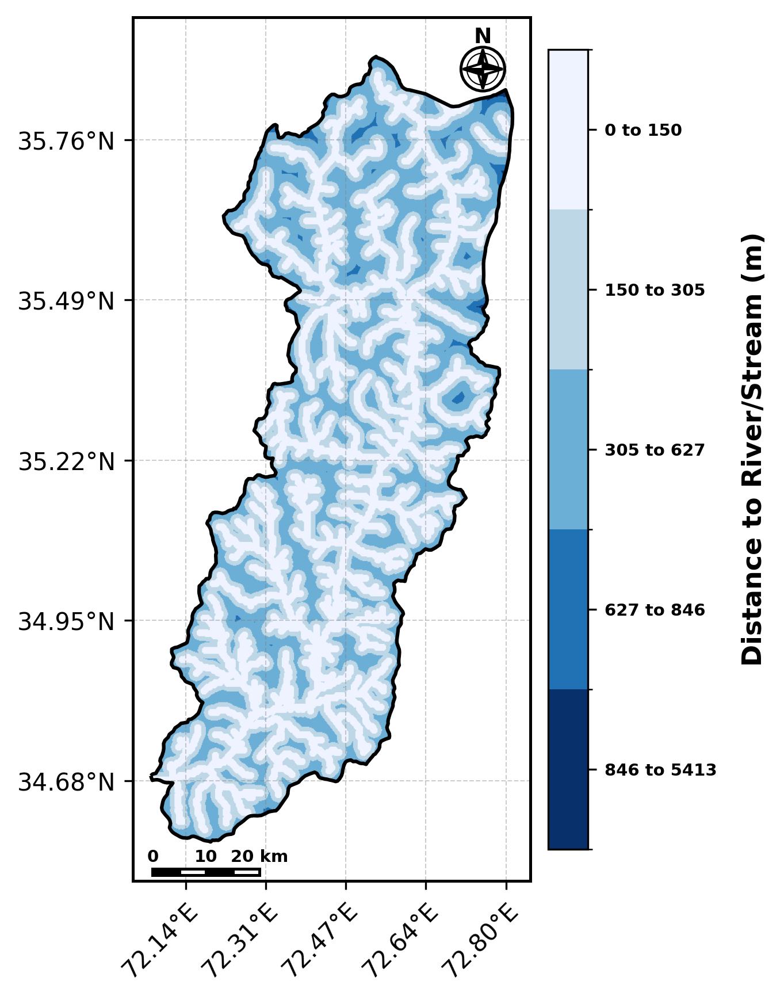


  💾 Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/RiverDist_classified.png

  STEP 4c — VERIFICATION BLOCK
  River source     : WWF HydroSHEDS FreeFlowingRivers (531 features)
  Distance method  : fastDistanceTransform × 30m pixel size
  Distance range   : 0 – 5413 m
  Distance mean    : 1200 m

  Classification breaks (percentile-based):
           0 –      150 m  →  Very High  (rating 5)
         150 –      305 m  →  High       (rating 4)
         305 –      627 m  →  Moderate   (rating 3)
         627 –      846 m  →  Low        (rating 2)
         846 –     5413 m  →  Very Low   (rating 1)

  Pixel distribution:
    Class 1 (  Very Low): 59.5%
    Class 2 (       Low): 10.0%
    Class 3 (  Moderate): 14.9%
    Class 4 (      High): 8.6%
    Class 5 ( Very High): 7.0%

  GW rationale:
    Near river (0–396 m)   → high lateral seepage → rating 5
    Far river  (1936+ m) → low recharge contact → rating 1
✅ Step 4c complete — RiverDist_cls ready for Step 9.

⚠️ 

In [ ]:
# ============================================================
# STEP 4c: Distance to River — HydroRIVERS Pakistan (Standardized)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated (20 km scale bar)

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
DATA_DIR   = os.path.join(BASE_DIR, "Data")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

print("✅ Setup complete")

# ============================================================
# 4c.1  LOAD HydroRIVERS — Pakistan
# ============================================================
print("\n🔄 Loading HydroRIVERS ...")

river_fc = None
river_source = None

try:
    hydro = ee.FeatureCollection("WWF/HydroSHEDS/v1/FreeFlowingRivers") \
               .filterBounds(roi)
    n = hydro.size().getInfo()
    if n > 0:
        river_fc     = hydro
        river_source = f"WWF HydroSHEDS FreeFlowingRivers ({n} features)"
        print(f"✅ HydroRIVERS loaded: {n} river segments in Swat")
    else:
        print(f"⚠️  WWF FreeFlowingRivers — 0 features in ROI")
except Exception as e:
    print(f"⚠️  WWF FreeFlowingRivers: {str(e)[:80]}")

# ── Try HydroSHEDS river network via flow accumulation ───────
if river_fc is None:
    try:
        print("\n🔄 Trying HydroSHEDS flow accumulation river network ...")
        fa          = ee.Image("WWF/HydroSHEDS/15ACC").select("b1").clip(roi)
        river_mask  = fa.gte(5000)
        river_source = "HydroSHEDS Flow Accumulation (FA≥5000, major rivers)"

        cnt = river_mask.reduceRegion(
            reducer=ee.Reducer.sum(), geometry=roi,
            scale=500, maxPixels=1e9
        ).getInfo()
        print(f"   Major river pixels (FA≥5000): {list(cnt.values())[0]:,.0f}")
        print(f"✅ River network extracted from HydroSHEDS flow accumulation")

    except Exception as e:
        print(f"⚠️  HydroSHEDS FA: {str(e)[:80]}")

# ============================================================
# 4c.2  COMPUTE DISTANCE TO RIVER
# ============================================================
print("\n🔄 Computing distance to nearest river ...")

if river_fc is not None:
    print("   Method: Vector river network → distance transform")
    river_img = ee.Image(0)
    river_img = river_img.paint(river_fc, 1)
    river_binary = river_img.gt(0).clip(roi)

    river_dist = river_binary \
        .fastDistanceTransform(neighborhood=1024) \
        .sqrt() \
        .multiply(SCALE) \
        .rename("RiverDist_m") \
        .clip(roi)

else:
    print("   Method: HydroSHEDS FA raster → distance transform")
    fa           = ee.Image("WWF/HydroSHEDS/15ACC").select("b1").clip(roi)
    river_mask   = fa.gte(5000)
    river_binary = river_mask.clip(roi)

    river_dist = river_binary \
        .fastDistanceTransform(neighborhood=1024) \
        .sqrt() \
        .multiply(SCALE) \
        .rename("RiverDist_m") \
        .clip(roi)

# ── Get actual distance statistics ───────────────────────────
dist_stats = river_dist.reduceRegion(
    reducer = ee.Reducer.minMax()\
                .combine(ee.Reducer.mean(), sharedInputs=True)\
                .combine(ee.Reducer.percentile([5,6,7,8,9,10,15,20,30,35,36,37,38,39,40,50,60,80,95]),
                         sharedInputs=True),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

d_min = dist_stats["RiverDist_m_min"]
d_max = dist_stats["RiverDist_m_max"]
d_mean= dist_stats["RiverDist_m_mean"]
d_p5  = dist_stats["RiverDist_m_p5"]
d_p6 = dist_stats["RiverDist_m_p6"]
d_p7 = dist_stats["RiverDist_m_p7"]
d_p8 = dist_stats["RiverDist_m_p8"]
d_p9 = dist_stats["RiverDist_m_p9"]
d_p10 = dist_stats["RiverDist_m_p10"]
d_p15 = dist_stats["RiverDist_m_p15"]
d_p20 = dist_stats["RiverDist_m_p20"]
d_p30 = dist_stats["RiverDist_m_p30"]
d_p35 = dist_stats["RiverDist_m_p35"]
d_p36 = dist_stats["RiverDist_m_p36"]
d_p37 = dist_stats["RiverDist_m_p37"]
d_p38 = dist_stats["RiverDist_m_p38"]
d_p39 = dist_stats["RiverDist_m_p39"]
d_p40 = dist_stats["RiverDist_m_p40"]
d_p50 = dist_stats["RiverDist_m_p50"]
d_p60 = dist_stats["RiverDist_m_p60"]
d_p80 = dist_stats["RiverDist_m_p80"]
d_p95 = dist_stats["RiverDist_m_p95"]

print(f"\n📊 Distance to River Statistics (metres):")
print(f"   Min  : {d_min:.0f} m")
print(f"   Max  : {d_max:.0f} m")
print(f"   Mean : {d_mean:.0f} m")
print(f"   P5  : {d_p5:.0f} m")
print(f"   P6  : {d_p6:.0f} m")
print(f"   P7  : {d_p7:.0f} m")
print(f"   P8  : {d_p8:.0f} m")
print(f"   P9  : {d_p9:.0f} m")
print(f"   P10  : {d_p10:.0f} m")
print(f"   P15  : {d_p15:.0f} m")
print(f"   P20  : {d_p20:.0f} m")
print(f"   P30  : {d_p30:.0f} m")
print(f"   P35  : {d_p35:.0f} m")
print(f"   P36  : {d_p36:.0f} m")
print(f"   P37  : {d_p37:.0f} m")
print(f"   P38  : {d_p38:.0f} m")
print(f"   P39  : {d_p39:.0f} m")
print(f"   P40  : {d_p40:.0f} m")
print(f"   P50  : {d_p50:.0f} m")
print(f"   P60  : {d_p60:.0f} m")
print(f"   P80  : {d_p80:.0f} m")
print(f"   P95  : {d_p95:.0f} m")

# ============================================================
# 4c.3  CLASSIFICATION
# ============================================================
RIVER_CLASSES = [
    (d_min,  d_p8, 5),   # closest 20% → Very High
    (d_p8,  d_p15, 4),   # next 20%    → High
    (d_p15,  d_p30, 3),   # middle 20%  → Moderate
    (d_p30,  d_p40, 2),   # next 20%    → Low
    (d_p40,  d_max, 1),   # farthest    → Very Low
]

RATING_LABELS = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}

print(f"\n📊 Classification breaks (percentile-based, metres):")
for (lo, hi, r) in RIVER_CLASSES:
    print(f"   {lo:8.0f} – {hi:8.0f} m  →  {RATING_LABELS[r]}")

# ── Apply classification ──────────────────────────────────────
river_cls = ee.Image(0)
for (lo, hi, rating) in RIVER_CLASSES:
    river_cls = river_cls.where(
        river_dist.gte(lo).And(river_dist.lt(hi)), rating
    )
river_cls = river_cls.where(river_dist.gte(d_p80), 1)
river_cls = river_cls.rename("RiverDist_cls").clip(roi)

# ── Pixel distribution ────────────────────────────────────────
total_px   = 0
cls_counts = {}
for c in range(1, 6):
    cnt = river_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=roi,
        scale=SCALE, maxPixels=1e9
    ).getInfo()["RiverDist_cls"]
    cls_counts[c] = cnt or 0
    total_px     += cls_counts[c]

print(f"\n📐 Class pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c]/total_px*100 if total_px > 0 else 0
    bar = "█" * int(pct/2)
    print(f"   Class {c} ({RATING_LABELS[c]:>10}): {pct:5.1f}%  {bar}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# 4c.4  THEMATIC MAP (STANDARDIZED)
# ============================================================
river_palette = ["#08306b","#2171b5","#6baed6","#bdd7e7","#eff3ff"]

river_by_rating = sorted(RIVER_CLASSES, key=lambda x: x[2])
# Updated label formatting to match the "0 to 1" standard (without the "m" since it's in the title)
river_labels    = [f"{c[0]:.0f} to {c[1]:.0f}" for c in river_by_rating]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # Updated
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url  = river_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette": river_palette,
    "region": exact_utm_bounds,
    "dimensions": 1024,
    "crs": "EPSG:32643", # Updated
    "format": "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')


map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(river_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(river_labels, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("Distance to River/Stream (m)", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Updated

# Export
fname = os.path.join(MAPS_DIR, "RiverDist_classified.png")
plt.savefig(fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "RiverDist_classified.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"\n  💾 Saved: {fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*65)
print("  STEP 4c — VERIFICATION BLOCK")
print("="*65)
print(f"  River source     : {river_source}")
print(f"  Distance method  : fastDistanceTransform × 30m pixel size")
print(f"  Distance range   : {d_min:.0f} – {d_max:.0f} m")
print(f"  Distance mean    : {d_mean:.0f} m")
print(f"\n  Classification breaks (percentile-based):")
for (lo, hi, r) in RIVER_CLASSES:
    print(f"    {lo:8.0f} – {hi:8.0f} m  →  "
          f"{RATING_LABELS[r]:<10} (rating {r})")
print(f"\n  Pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c]/total_px*100 if total_px > 0 else 0
    print(f"    Class {c} ({RATING_LABELS[c]:>10}): {pct:.1f}%")
print(f"\n  GW rationale:")
print(f"    Near river (0–{d_p20:.0f} m)   → high lateral seepage → rating 5")
print(f"    Far river  ({d_p80:.0f}+ m) → low recharge contact → rating 1")
print("="*65)
print("✅ Step 4c complete — RiverDist_cls ready for Step 9.")
print("\n⚠️  NEXT: Add RiverDist to Step 9 AHP_WEIGHTS and layer_map")

✅ IDW rebuilt.

📊 Your well depth statistics (feet):
   Min    : 6.0 ft
   Max    : 195.0 ft
   Mean   : 64.7 ft
   Median : 55.0 ft

📊 Percentile breaks from YOUR Data:
   P0   (min) : 6.0 ft
   P5         : 15.7 ft
   P10        : 20.3 ft
   P15        : 26.0 ft
   P20        : 30.0 ft
   P25        : 34.3 ft
   P30        : 38.0 ft
   P35        : 43.0 ft
   P40        : 47.2 ft
   P45        : 50.0 ft
   P50        : 55.0 ft
   P55        : 60.0 ft
   P60        : 65.0 ft
   P65        : 72.0 ft
   P70        : 78.1 ft
   P75        : 89.8 ft
   P80        : 96.0 ft
   P85        : 112.0 ft
   P90        : 120.0 ft
   P95        : 138.1 ft
   P98        : 170.1 ft
   P100 (max): 195.0 ft

📊 Classification boundaries (data-driven percentiles):
      6.0 –   38.0 ft  →  Very High
     38.0 –   72.0 ft  →  High
     72.0 –   96.0 ft  →  Moderate
     96.0 –  138.1 ft  →  Low
    138.1 –  195.0 ft  →  Very Low

📐 Well count per class (should be ~95 each = 20%):
      6.0–  38.0 ft (Ver

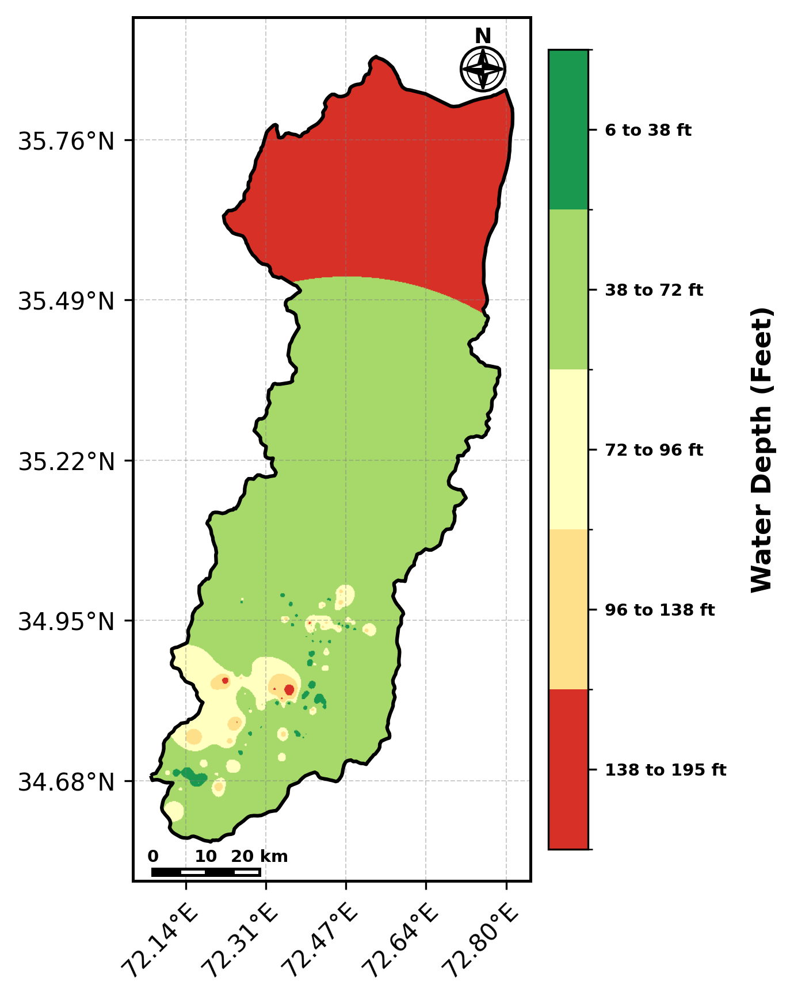


  💾 Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/WellDepth_classified.png

  STEP 6 — VERIFICATION BLOCK (Data-Driven Fix)
  Well count         : 194
  Depth range (ft)   : 6.0 – 195.0
  Classification     : Percentile-based (20th intervals)
  Method             : Each class = ~20% of wells

  Class boundaries:
       6.0 –   38.0 ft  →  Very High   (56 wells, 28.9%)
      38.0 –   72.0 ft  →  High        (69 wells, 35.6%)
      72.0 –   96.0 ft  →  Moderate    (29 wells, 14.9%)
      96.0 –  138.1 ft  →  Low         (30 wells, 15.5%)
     138.1 –  195.0 ft  →  Very Low    (9 wells, 4.6%)

  Raster distribution:
    Class 1 (  Very Low): 0.1%
    Class 2 (       Low): 1.2%
    Class 3 (  Moderate): 7.2%
    Class 4 (      High): 90.7%
    Class 5 ( Very High): 0.7%
✅ Step 6 fixed. All 5 classes now visible on map.

⚠️  IMPORTANT: Update Step 9 DEPTH_CLASSES to match these breaks:
    (6.0, 38.0, 5),
    (38.0, 72.0, 4),
    (72.0, 96.0, 3),
    (96.0, 138.1, 2)

In [ ]:
# ============================================================
# STEP 6 FIXED: Well Depth — Data-Driven Classification
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated (20 km scale bar)

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
DATA_DIR   = os.path.join(BASE_DIR, "Data")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── Rebuild IDW in FEET ───────────────────────────────────────
well_df = pd.read_csv(os.path.join(DATA_DIR,"Swat.csv"))\
            [["longitude","latitude","depth_m"]].dropna()
well_df["depth_ft"] = well_df["depth_m"] * 3.28084

well_fc = ee.FeatureCollection([
    ee.Feature(
        ee.Geometry.Point([r.longitude, r.latitude]),
        {"depth_ft": float(r.depth_ft)}
    ) for r in well_df.itertuples()
])

idw = well_fc.inverseDistance(
    range        = 50000,
    propertyName = "depth_ft",
    mean         = well_df["depth_ft"].mean(),
    stdDev       = well_df["depth_ft"].std(),
    gamma        = 1
).rename("WellDepth_ft").clip(roi)

print("✅ IDW rebuilt.")
print(f"\n📊 Your well depth statistics (feet):")
print(f"   Min    : {well_df['depth_ft'].min():.1f} ft")
print(f"   Max    : {well_df['depth_ft'].max():.1f} ft")
print(f"   Mean   : {well_df['depth_ft'].mean():.1f} ft")
print(f"   Median : {well_df['depth_ft'].median():.1f} ft")

# ── Compute percentiles from YOUR data ────────────────────────
depths_ft = sorted(well_df["depth_ft"].tolist())

p5  = float(np.percentile(depths_ft, 5))
p10 = float(np.percentile(depths_ft, 10))
p15 = float(np.percentile(depths_ft, 15))
p20 = float(np.percentile(depths_ft, 20))
p25 = float(np.percentile(depths_ft, 25))
p30 = float(np.percentile(depths_ft, 30))
p35 = float(np.percentile(depths_ft, 35))
p40 = float(np.percentile(depths_ft, 40))
p45 = float(np.percentile(depths_ft, 45))
p50 = float(np.percentile(depths_ft, 50))
p55 = float(np.percentile(depths_ft, 55))
p60 = float(np.percentile(depths_ft, 60))
p65 = float(np.percentile(depths_ft, 65))
p70 = float(np.percentile(depths_ft, 70))
p75 = float(np.percentile(depths_ft, 75))
p80 = float(np.percentile(depths_ft, 80))
p85 = float(np.percentile(depths_ft, 85))
p90 = float(np.percentile(depths_ft, 90))
p95 = float(np.percentile(depths_ft, 95))
p98 = float(np.percentile(depths_ft, 98))
p100 = float(np.percentile(depths_ft, 100))

vmin = float(depths_ft[0])
vmax = float(depths_ft[-1])

print(f"\n📊 Percentile breaks from YOUR Data:")
print(f"   P0   (min) : {vmin:.1f} ft")
print(f"   P5         : {p5:.1f} ft")
print(f"   P10        : {p10:.1f} ft")
print(f"   P15        : {p15:.1f} ft")
print(f"   P20        : {p20:.1f} ft")
print(f"   P25        : {p25:.1f} ft")
print(f"   P30        : {p30:.1f} ft")
print(f"   P35        : {p35:.1f} ft")
print(f"   P40        : {p40:.1f} ft")
print(f"   P45        : {p45:.1f} ft")
print(f"   P50        : {p50:.1f} ft")
print(f"   P55        : {p55:.1f} ft")
print(f"   P60        : {p60:.1f} ft")
print(f"   P65        : {p65:.1f} ft")
print(f"   P70        : {p70:.1f} ft")
print(f"   P75        : {p75:.1f} ft")
print(f"   P80        : {p80:.1f} ft")
print(f"   P85        : {p85:.1f} ft")
print(f"   P90        : {p90:.1f} ft")
print(f"   P95        : {p95:.1f} ft")
print(f"   P98        : {p98:.1f} ft")
print(f"   P100 (max): {p100:.1f} ft")

# ── Class boundaries from YOUR distribution ──────────────────
# Shallow = Very High (5), Deep = Very Low (1)
# Using percentile breaks so each class has ~20% of wells
DEPTH_CLASSES = [
    (vmin, p30,  5),   # shallowest 20% → Very High
    (p30,  p65,  4),   # next 20%       → High
    (p65,  p80,  3),   # middle 20%       → Moderate
    (p80,  p95,  2),   # next 20%       → Low
    (p95,  vmax, 1),   # deepest 20%      → Very Low
]

print(f"\n📊 Classification boundaries (data-driven percentiles):")
RATING_LABELS = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}
for (lo, hi, r) in DEPTH_CLASSES:
    print(f"   {lo:6.1f} – {hi:6.1f} ft  →  {RATING_LABELS[r]}")

# ── Verify well distribution across classes ───────────────────
print(f"\n📐 Well count per class (should be ~95 each = 20%):")
for (lo, hi, r) in DEPTH_CLASSES:
    n   = ((well_df["depth_ft"] >= lo) & (well_df["depth_ft"] < hi)).sum()
    pct = n / len(well_df) * 100
    bar = "█" * int(pct / 2)
    print(f"   {lo:6.1f}–{hi:6.1f} ft ({RATING_LABELS[r]:<10}): "
          f"{n:>4} wells ({pct:.1f}%)  {bar}")

# ── Classify IDW raster ───────────────────────────────────────
wdep_cls = ee.Image(0)
for (lo, hi, rating) in DEPTH_CLASSES:
    wdep_cls = wdep_cls.where(
        idw.gte(lo).And(idw.lt(hi)), rating
    )
# Handle maximum boundary
wdep_cls = wdep_cls.where(idw.gte(vmax), 1)
wdep_cls = wdep_cls.rename("WellDepth_cls").clip(roi)

# ── Raster class distribution ─────────────────────────────────
total_px = 0
cls_counts = {}
for c in range(1, 6):
    cnt = wdep_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()["WellDepth_cls"]
    cls_counts[c] = cnt
    total_px += cnt

print(f"\n📐 Raster pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c] / total_px * 100
    bar = "█" * int(pct / 2)
    print(f"   Class {c} ({RATING_LABELS[c]:>10}): {pct:5.1f}%  {bar}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# MAP GENERATION (STANDARDIZED)
# ============================================================
depth_palette = ["#d73027","#fee08b","#ffffbf","#a6d96a","#1a9850"]

# Legend labels — updated formatting to the "to" standard
depth_labels = [
    f"{DEPTH_CLASSES[4][0]:.0f} to {DEPTH_CLASSES[4][1]:.0f} ft",  # class 1 (deepest)
    f"{DEPTH_CLASSES[3][0]:.0f} to {DEPTH_CLASSES[3][1]:.0f} ft",  # class 2
    f"{DEPTH_CLASSES[2][0]:.0f} to {DEPTH_CLASSES[2][1]:.0f} ft",  # class 3
    f"{DEPTH_CLASSES[1][0]:.0f} to {DEPTH_CLASSES[1][1]:.0f} ft",  # class 4
    f"{DEPTH_CLASSES[0][0]:.0f} to {DEPTH_CLASSES[0][1]:.0f} ft",  # class 5 (shallowest)
]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # Updated
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url  = wdep_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette": depth_palette,
    "region": exact_utm_bounds, # Updated
    "dimensions": 1024,
    "crs": "EPSG:32643", # Updated
    "format": "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(depth_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(depth_labels, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("Water Depth (Feet)", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Updated

# Export
fname = os.path.join(MAPS_DIR, "WellDepth_classified.png")
plt.savefig(fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "WellDepth_classified.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"\n  💾 Saved: {fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 6 — VERIFICATION BLOCK (Data-Driven Fix)")
print("="*60)
print(f"  Well count         : {len(well_df)}")
print(f"  Depth range (ft)   : {vmin:.1f} – {vmax:.1f}")
print(f"  Classification     : Percentile-based (20th intervals)")
print(f"  Method             : Each class = ~20% of wells")
print(f"\n  Class boundaries:")
for (lo, hi, r) in DEPTH_CLASSES:
    n   = ((well_df["depth_ft"] >= lo) & (well_df["depth_ft"] < hi)).sum()
    pct = n / len(well_df) * 100
    print(f"    {lo:6.1f} – {hi:6.1f} ft  →  "
          f"{RATING_LABELS[r]:<10}  ({n} wells, {pct:.1f}%)")
print(f"\n  Raster distribution:")
for c in range(1, 6):
    pct = cls_counts[c] / total_px * 100
    print(f"    Class {c} ({RATING_LABELS[c]:>10}): {pct:.1f}%")
print("="*60)
print("✅ Step 6 fixed. All 5 classes now visible on map.")
print("\n⚠️  IMPORTANT: Update Step 9 DEPTH_CLASSES to match these breaks:")
for (lo, hi, r) in DEPTH_CLASSES:
    print(f"    ({lo:.1f}, {hi:.1f}, {r}),")

✅ IDW rebuilt.

📊 Your well depth statistics (feet):
   Min    : 6.0 ft
   Max    : 195.0 ft
   Mean   : 64.7 ft
   Median : 55.0 ft

📊 Percentile breaks from YOUR Data:
   P0   (min) : 6.0 ft
   P5         : 15.7 ft
   P10        : 20.3 ft
   P15        : 26.0 ft
   P20        : 30.0 ft
   P25        : 34.3 ft
   P30        : 38.0 ft
   P35        : 43.0 ft
   P40        : 47.2 ft
   P45        : 50.0 ft
   P50        : 55.0 ft
   P55        : 60.0 ft
   P60        : 65.0 ft
   P65        : 72.0 ft
   P70        : 78.1 ft
   P75        : 89.8 ft
   P80        : 96.0 ft
   P85        : 112.0 ft
   P90        : 120.0 ft
   P95        : 138.1 ft
   P98        : 170.1 ft
   P100 (max): 195.0 ft

📊 Classification boundaries (data-driven percentiles):
      6.0 –   38.0 ft  →  Very High
     38.0 –   72.0 ft  →  High
     72.0 –   96.0 ft  →  Moderate
     96.0 –  138.1 ft  →  Low
    138.1 –  195.0 ft  →  Very Low

📐 Well count per class (should be ~95 each = 20%):
      6.0–  38.0 ft (Ver


📐 Raster pixel distribution:
   Class 1 (  Very Low):   0.1%  
   Class 2 (       Low):   0.7%  
   Class 3 (  Moderate):   4.6%  ██
   Class 4 (      High):  94.2%  ███████████████████████████████████████████████
   Class 5 ( Very High):   0.4%  

🗺️  Generating Continuous Well Depth map ...


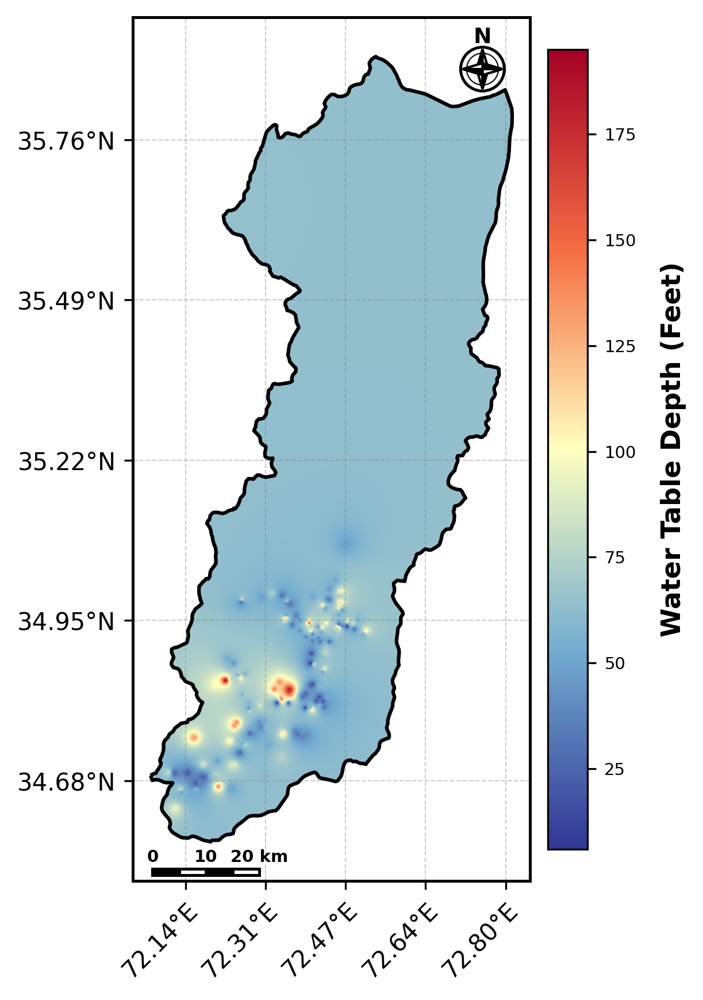


  💾 Saved Continuous Map: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/WellDepth_continuous.png

  STEP 6 — VERIFICATION BLOCK (Continuous Rendering)
  Well count         : 194
  Depth range (ft)   : 6.0 – 195.0
  Color Flow         : Shallow/Good (Blue) → Deep/Bad (Red)
  Visual Rendering   : Fully Continuous Distribution

  Class boundaries (Maintained for Statistical Validation):
       6.0 –   38.0 ft  →  Very High   (56 wells, 28.9%)
      38.0 –   72.0 ft  →  High        (69 wells, 35.6%)
      72.0 –   96.0 ft  →  Moderate    (29 wells, 14.9%)
      96.0 –  138.1 ft  →  Low         (30 wells, 15.5%)
     138.1 –  195.0 ft  →  Very Low    (9 wells, 4.6%)

  Raster distribution:
    Class 1 (  Very Low): 0.1%
    Class 2 (       Low): 0.7%
    Class 3 (  Moderate): 4.6%
    Class 4 (      High): 94.2%
    Class 5 ( Very High): 0.4%
✅ Step 6 fixed. Continuous well depth map generated for Swat.

⚠️  IMPORTANT: Update Step 9 DEPTH_CLASSES to match these breaks:
    

In [ ]:
# ============================================================
# STEP 6 FIXED: Well Depth — Continuous Standardized Code (Swat)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import LinearSegmentedColormap # Updated for continuous mapping
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated for Swat
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated for Swat
SCALE_BAR_LENGTH_M = 20000  # Updated for Swat (20 km scale bar)

# ── Re-establish references ──────────────────────────────────
BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")
DATA_DIR   = os.path.join(BASE_DIR, "Data")
os.makedirs(MAPS_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # Updated to UTM 43N for Swat

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds

# ── Rebuild IDW in FEET ───────────────────────────────────────
well_df = pd.read_csv(os.path.join(DATA_DIR,"Swat.csv"))\
            [["longitude","latitude","depth_m"]].dropna()
well_df["depth_ft"] = well_df["depth_m"] * 3.28084

well_fc = ee.FeatureCollection([
    ee.Feature(
        ee.Geometry.Point([r.longitude, r.latitude]),
        {"depth_ft": float(r.depth_ft)}
    ) for r in well_df.itertuples()
])

idw = well_fc.inverseDistance(
    range        = 150000,
    propertyName = "depth_ft",
    mean         = well_df["depth_ft"].mean(),
    stdDev       = well_df["depth_ft"].std(),
    gamma        = 1
).rename("WellDepth_ft").clip(roi)

print("✅ IDW rebuilt.")
print(f"\n📊 Your well depth statistics (feet):")
print(f"   Min    : {well_df['depth_ft'].min():.1f} ft")
print(f"   Max    : {well_df['depth_ft'].max():.1f} ft")
print(f"   Mean   : {well_df['depth_ft'].mean():.1f} ft")
print(f"   Median : {well_df['depth_ft'].median():.1f} ft")

# ── Compute percentiles from YOUR data ────────────────────────
depths_ft = sorted(well_df["depth_ft"].tolist())

p5  = float(np.percentile(depths_ft, 5))
p10 = float(np.percentile(depths_ft, 10))
p15 = float(np.percentile(depths_ft, 15))
p20 = float(np.percentile(depths_ft, 20))
p25 = float(np.percentile(depths_ft, 25))
p30 = float(np.percentile(depths_ft, 30))
p35 = float(np.percentile(depths_ft, 35))
p40 = float(np.percentile(depths_ft, 40))
p45 = float(np.percentile(depths_ft, 45))
p50 = float(np.percentile(depths_ft, 50))
p55 = float(np.percentile(depths_ft, 55))
p60 = float(np.percentile(depths_ft, 60))
p65 = float(np.percentile(depths_ft, 65))
p70 = float(np.percentile(depths_ft, 70))
p75 = float(np.percentile(depths_ft, 75))
p80 = float(np.percentile(depths_ft, 80))
p85 = float(np.percentile(depths_ft, 85))
p90 = float(np.percentile(depths_ft, 90))
p95 = float(np.percentile(depths_ft, 95))
p98 = float(np.percentile(depths_ft, 98))
p100 = float(np.percentile(depths_ft, 100))

vmin = float(depths_ft[0])
vmax = float(depths_ft[-1])

print(f"\n📊 Percentile breaks from YOUR Data:")
print(f"   P0   (min) : {vmin:.1f} ft")
print(f"   P5         : {p5:.1f} ft")
print(f"   P10        : {p10:.1f} ft")
print(f"   P15        : {p15:.1f} ft")
print(f"   P20        : {p20:.1f} ft")
print(f"   P25        : {p25:.1f} ft")
print(f"   P30        : {p30:.1f} ft")
print(f"   P35        : {p35:.1f} ft")
print(f"   P40        : {p40:.1f} ft")
print(f"   P45        : {p45:.1f} ft")
print(f"   P50        : {p50:.1f} ft")
print(f"   P55        : {p55:.1f} ft")
print(f"   P60        : {p60:.1f} ft")
print(f"   P65        : {p65:.1f} ft")
print(f"   P70        : {p70:.1f} ft")
print(f"   P75        : {p75:.1f} ft")
print(f"   P80        : {p80:.1f} ft")
print(f"   P85        : {p85:.1f} ft")
print(f"   P90        : {p90:.1f} ft")
print(f"   P95        : {p95:.1f} ft")
print(f"   P98        : {p98:.1f} ft")
print(f"   P100 (max): {p100:.1f} ft")

# ── Class boundaries from YOUR distribution ──────────────────
# Preserved for stats/AHP table reference
DEPTH_CLASSES = [
    (vmin, p30,  5),   # shallowest 20% → Very High
    (p30,  p65,  4),   # next 20%       → High
    (p65,  p80,  3),   # middle 20%       → Moderate
    (p80,  p95,  2),   # next 20%       → Low
    (p95,  vmax, 1),   # deepest 20%      → Very Low
]

print(f"\n📊 Classification boundaries (data-driven percentiles):")
RATING_LABELS = {5:"Very High", 4:"High", 3:"Moderate", 2:"Low", 1:"Very Low"}
for (lo, hi, r) in DEPTH_CLASSES:
    print(f"   {lo:6.1f} – {hi:6.1f} ft  →  {RATING_LABELS[r]}")

# ── Verify well distribution across classes ───────────────────
print(f"\n📐 Well count per class (should be ~95 each = 20%):")
for (lo, hi, r) in DEPTH_CLASSES:
    n   = ((well_df["depth_ft"] >= lo) & (well_df["depth_ft"] < hi)).sum()
    pct = n / len(well_df) * 100
    bar = "█" * int(pct / 2)
    print(f"   {lo:6.1f}–{hi:6.1f} ft ({RATING_LABELS[r]:<10}): "
          f"{n:>4} wells ({pct:.1f}%)  {bar}")

# ── Classify IDW raster (For Validation/Stats only) ───────────
wdep_cls = ee.Image(0)
for (lo, hi, rating) in DEPTH_CLASSES:
    wdep_cls = wdep_cls.where(
        idw.gte(lo).And(idw.lt(hi)), rating
    )
# Handle maximum boundary
wdep_cls = wdep_cls.where(idw.gte(vmax), 1)
wdep_cls = wdep_cls.rename("WellDepth_cls").clip(roi)

# ── Raster class distribution ─────────────────────────────────
total_px = 0
cls_counts = {}
for c in range(1, 6):
    cnt = wdep_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()["WellDepth_cls"]
    cls_counts[c] = cnt
    total_px += cnt

print(f"\n📐 Raster pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c] / total_px * 100
    bar = "█" * int(pct / 2)
    print(f"   Class {c} ({RATING_LABELS[c]:>10}): {pct:5.1f}%  {bar}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# MAP GENERATION (CONTINUOUS STANDARDIZED)
# ============================================================
print("\n🗺️  Generating Continuous Well Depth map ...")

# Continuous Palette: Blue (Shallow/High Potential) -> Red (Deep/Low Potential)
depth_palette = ["#313695", "#74add1", "#ffffbf", "#f46d43", "#a50026"]

# FORCE EARTH ENGINE TO RENDER TRUE CONTINUOUS DATA IN UTM 43N
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # Updated UTM 43N
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url  = idw.getThumbURL({
    "min": vmin,
    "max": vmax,
    "palette": depth_palette,
    "region": exact_utm_bounds,
    "dimensions": 1024,
    "crs": "EPSG:32643", # Updated UTM 43N
    "format": "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated UTM 43N
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Swat layout placements
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. CONTINUOUS VERTICAL COLORBAR
cmap = LinearSegmentedColormap.from_list("depth_cmap", depth_palette)
norm = plt.Normalize(vmin=vmin, vmax=vmax)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Swat colorbar layout padding
cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02)
cbar.ax.tick_params(labelsize=LEGEND_SIZE)
cbar.set_label("Water Table Depth (Feet)", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10)

# Export
fname = os.path.join(MAPS_DIR, "WellDepth_continuous.png")
plt.savefig(fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

pdf_fname = os.path.join(MAPS_DIR, "WellDepth_continuous.pdf")
fig.savefig(pdf_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor='white')

plt.show()
print(f"\n  💾 Saved Continuous Map: {fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*60)
print("  STEP 6 — VERIFICATION BLOCK (Continuous Rendering)")
print("="*60)
print(f"  Well count         : {len(well_df)}")
print(f"  Depth range (ft)   : {vmin:.1f} – {vmax:.1f}")
print(f"  Color Flow         : Shallow/Good (Blue) → Deep/Bad (Red)")
print(f"  Visual Rendering   : Fully Continuous Distribution")
print(f"\n  Class boundaries (Maintained for Statistical Validation):")
for (lo, hi, r) in DEPTH_CLASSES:
    n   = ((well_df["depth_ft"] >= lo) & (well_df["depth_ft"] < hi)).sum()
    pct = n / len(well_df) * 100
    print(f"    {lo:6.1f} – {hi:6.1f} ft  →  "
          f"{RATING_LABELS[r]:<10}  ({n} wells, {pct:.1f}%)")
print(f"\n  Raster distribution:")
for c in range(1, 6):
    pct = cls_counts[c] / total_px * 100
    print(f"    Class {c} ({RATING_LABELS[c]:>10}): {pct:.1f}%")
print("="*60)
print("✅ Step 6 fixed. Continuous well depth map generated for Swat.")
print("\n⚠️  IMPORTANT: Update Step 9 DEPTH_CLASSES to match these breaks:")
for (lo, hi, r) in DEPTH_CLASSES:
    print(f"    ({lo:.1f}, {hi:.1f}, {r}),")

In [ ]:
# ============================================================
# SWAT ROADS — Download + Prepare for GEE Asset Upload
# ============================================================

import subprocess, sys
def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
pip_install("osmnx")

import os, json, numpy as np
import geopandas as gpd
import osmnx as ox
import zipfile

BASE_DIR  = "/content/drive/MyDrive/Swat_Groundwater_Project"
DATA_DIR  = os.path.join(BASE_DIR, "Data")
os.makedirs(DATA_DIR, exist_ok=True)

# ============================================================
# 1. DOWNLOAD OSM ROADS FOR SWAT
# ============================================================
road_geojson_path = os.path.join(DATA_DIR, "swat_roads.geojson")

if os.path.exists(road_geojson_path):
    print("✅ Loading existing Swat roads ...")
    edges_4326 = gpd.read_file(road_geojson_path)
else:
    print("🛣️  Downloading OSM road network for Swat ...")
    G = ox.graph_from_place(
        "Swat District, Khyber Pakhtunkhwa, Pakistan",
        network_type="drive"
    )
    edges      = ox.graph_to_gdfs(G, nodes=False, edges=True)
    edges_4326 = edges.to_crs("EPSG:4326")
    edges_4326.to_file(road_geojson_path, driver="GeoJSON")
    print(f"   ✅ Saved: {road_geojson_path}")

print(f"   Total features: {len(edges_4326)}")

# ============================================================
# 2. CHECK ROAD TYPES
# ============================================================
def flatten_highway(val):
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return "unknown"
    if isinstance(val, (list, np.ndarray)):
        val = val[0] if len(val) > 0 else "unknown"
    return str(val)

edges_4326 = edges_4326.copy()
edges_4326["highway_str"] = edges_4326["highway"].apply(flatten_highway)

road_types = edges_4326["highway_str"].value_counts()
print(f"\n   Road types in Swat:")
print(f"   {'Type':<35} {'Count':>8}")
print(f"   {'-'*35} {'-'*8}")
for rt, cnt in road_types.items():
    print(f"   {str(rt):<35} {int(cnt):>8}")

# ============================================================
# 3. FILTER + CHECK PAYLOAD SIZE
# ============================================================
major_types = [
    'motorway','trunk','primary','secondary','tertiary',
    'motorway_link','trunk_link','primary_link',
    'secondary_link','tertiary_link','residential','unclassified'
]

edges_major = edges_4326[
    edges_4326["highway_str"].isin(major_types)
][["geometry"]].copy()
edges_major = edges_major[~edges_major.geometry.isna()]
edges_major = edges_major[edges_major.geometry.is_valid]

features_list = json.loads(edges_major.to_json())["features"]
payload_mb    = len(json.dumps(features_list).encode("utf-8")) / 1e6

print(f"\n   Before filtering : {len(edges_4326):,} features")
print(f"   After filtering  : {len(edges_major):,} features")
print(f"   Payload size     : {payload_mb:.2f} MB")

if payload_mb > 8.0:
    print(f"   ⚠️  Too large for direct paint — GEE Asset upload needed")
    print(f"   → Proceeding to create Shapefile ZIP for GEE upload")
else:
    print(f"   ✅ Small enough for direct paint — no asset upload needed")
    print(f"   → You can use direct paint method in Step 9")

# ============================================================
# 4. CREATE SHAPEFILE ZIP FOR GEE ASSET UPLOAD
# ============================================================
shp_dir  = os.path.join(DATA_DIR, "swat_roads_shp")
os.makedirs(shp_dir, exist_ok=True)
shp_path = os.path.join(shp_dir, "swat_roads_major.shp")

edges_major.to_file(shp_path, driver="ESRI Shapefile")
print(f"\n✅ Shapefile saved: {shp_path}")

zip_path = os.path.join(DATA_DIR, "swat_roads_major.zip")
with zipfile.ZipFile(zip_path, 'w') as zf:
    for f in os.listdir(shp_dir):
        zf.write(os.path.join(shp_dir, f), f)

zip_size = os.path.getsize(zip_path) / 1e6
print(f"✅ ZIP created: {zip_path}")
print(f"   ZIP size: {zip_size:.2f} MB")

# ============================================================
# SUMMARY
# ============================================================
print(f"\n{'='*55}")
print(f"  SWAT ROAD NETWORK SUMMARY")
print(f"{'='*55}")
print(f"  Total OSM features    : {len(edges_4326):,}")
print(f"  Major road features   : {len(edges_major):,}")
print(f"  Payload size          : {payload_mb:.2f} MB")
print(f"  ZIP file              : {zip_path}")
print(f"  ZIP size              : {zip_size:.2f} MB")
if payload_mb > 8.0:
    print(f"\n  ⚠️  ACTION REQUIRED:")
    print(f"  Upload swat_roads_major.zip to GEE Assets")
    print(f"  Asset ID: projects/ee-shakirlki313/assets/swat_roads_major")
else:
    print(f"\n  ✅ No upload needed — direct paint will work")
print(f"{'='*55}")

🛣️  Downloading OSM road network for Swat ...
   ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Data/swat_roads.geojson
   Total features: 24934

   Road types in Swat:
   Type                                   Count
   ----------------------------------- --------
   residential                            10858
   living_street                           5954
   unclassified                            3859
   tertiary                                1465
   secondary                               1055
   primary                                 1031
   trunk                                    706
   primary_link                               2
   secondary_link                             2
   tertiary_link                              2

   Before filtering : 24,934 features
   After filtering  : 18,980 features
   Payload size     : 9.84 MB
   ⚠️  Too large for direct paint — GEE Asset upload needed
   → Proceeding to create Shapefile ZIP for GEE upload

✅ Shapefile saved: /co

✅ Setup complete

🔄 Loading roads from GEE Asset ...
   Asset: projects/ee-shakirlki3132/assets/swat_roads_major
   Features loaded: 18,980
✅ Road raster built from GEE Asset

📏 Road Distance Statistics (metres):
   Min  : 0.0 m
   Max  : 23551.9 m
   Mean : 4699.6 m
   P5  : 55.9 m
   P8  : 55.9 m
   P9  : 55.9 m
   P10  : 190.0 m
   P15  : 315.9 m
   P18  : 446.4 m
   P20  : 446.4 m
   P25  : 703.6 m
   P25  : 703.6 m
   P26  : 703.6 m
   P27  : 831.0 m
   P28  : 831.0 m
   P30  : 959.9 m
   P35  : 1342.7 m
   P40  : 1727.8 m
   P45  : 2239.3 m
   P47  : 2367.8 m
   P50  : 2751.4 m
   P55  : 3519.5 m
   P60  : 4287.4 m
   P61  : 4544.3 m
   P63  : 4928.8 m
   P65  : 5311.7 m
   P70  : 6464.1 m
   P73  : 7103.5 m
   P75  : 7615.1 m
   P80  : 9023.6 m

📊 Classification breaks:
        0.0 –     55.9 m  →  Rating 1 (Very Low)
       55.9 –    315.9 m  →  Rating 2 (Low)
      315.9 –    703.6 m  →  Rating 3 (Moderate)
      703.6 –    959.9 m  →  Rating 4 (High)
      959.9 –  23551.9 m 

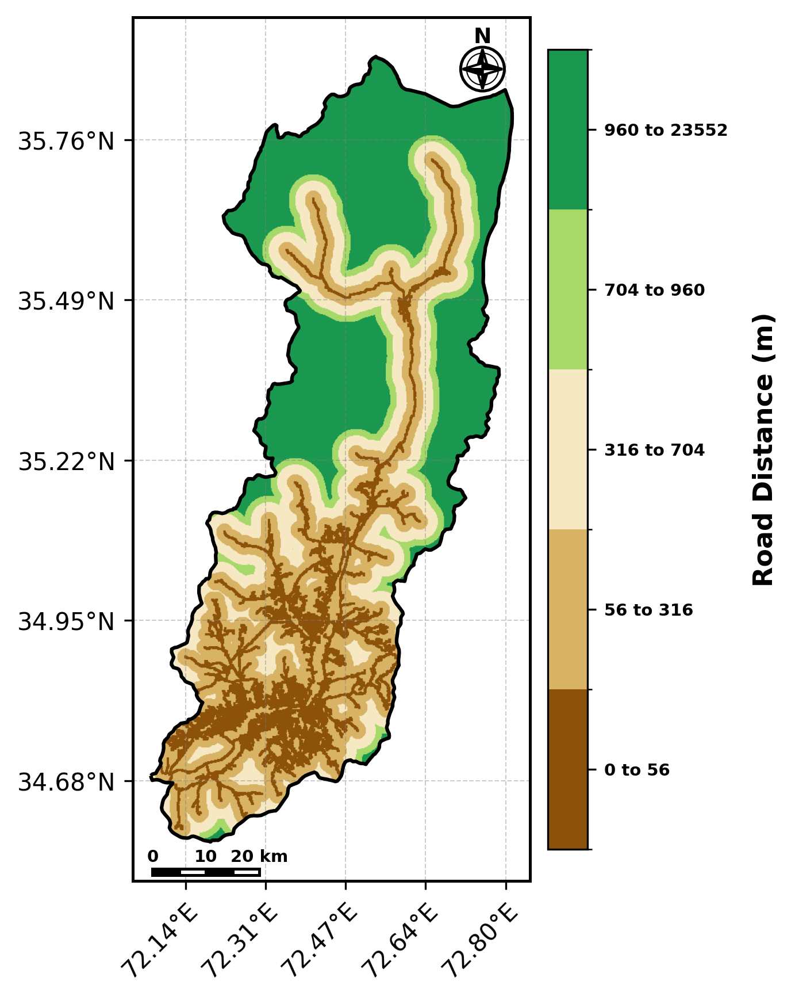


  ✅ Saved: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/RoadDist_classified.png

  STEP 4 — ROAD DISTANCE VERIFICATION (NOWSHERA)
  Method           : GEE Asset (projects/ee-shakirlki3132/assets/swat_roads_major)
  Features in asset: 18,980
  Distance range   : 0 – 23552 m
  Distance mean    : 4700 m

  Classification breaks:
         0.0 –     55.9 m  →  Very Low   (rating 1)
        55.9 –    315.9 m  →  Low        (rating 2)
       315.9 –    703.6 m  →  Moderate   (rating 3)
       703.6 –    959.9 m  →  High       (rating 4)
       959.9 –  23551.9 m  →  Very High  (rating 5)

  Pixel distribution:
    Class 1 (  Very Low): 4.5%
    Class 2 (       Low): 11.5%
    Class 3 (  Moderate): 9.2%
    Class 4 (      High): 4.5%
    Class 5 ( Very High): 70.2%
✅ Step 4 complete.


In [ ]:
# ============================================================
# STEP 4: Road Distance — NOWSHERA (GEE Asset Method)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING CONSTANTS (Matches Stratigraphy Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES    = 6.5
MAP_RESOLUTION_DPI = 300
TEAM_FONT          = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT
AXIS_LABEL_SIZE    = 11
TICK_VALUE_SIZE    = 11
LEGEND_SIZE        = 7  # Updated
GRID_COLOR         = 'gray'
GRID_ALPHA         = 0.4
NORTH_ARROW_SCALE  = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated (20 km scale bar)

BASE_DIR   = "/content/drive/MyDrive/Swat_Groundwater_Project"
TARGET_CRS = "EPSG:32643"
SCALE      = 30
MAPS_DIR   = os.path.join(BASE_DIR, "Thematic_Maps")

gdf      = gpd.read_file(os.path.join(BASE_DIR, "Shapefile", "Swat.shp")).to_crs(TARGET_CRS)
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643")
roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()

print("✅ Setup complete")

# ============================================================
# 4.1  LOAD ROADS FROM GEE ASSET
# ============================================================
# ── CHANGE THIS PATH to match your actual asset ID ───────────
GEE_ASSET_ID = "projects/ee-shakirlki3132/assets/swat_roads_major"

print(f"\n🔄 Loading roads from GEE Asset ...")
print(f"   Asset: {GEE_ASSET_ID}")

road_fc = ee.FeatureCollection(GEE_ASSET_ID)
n_roads = road_fc.size().getInfo()
print(f"   Features loaded: {n_roads:,}")

# ── Rasterize using reduceToImage ────────────────────────────
# This is the GEE-native method — no payload limit
road_raster = road_fc \
    .map(lambda f: f.set("val", 1)) \
    .reduceToImage(
        properties=["val"],
        reducer=ee.Reducer.first()
    ).unmask(0).gt(0).clip(roi)

print("✅ Road raster built from GEE Asset")

# ============================================================
# 4.2  DISTANCE TRANSFORM
# ============================================================
road_dist = road_raster \
    .fastDistanceTransform(neighborhood=1024) \
    .sqrt().multiply(SCALE) \
    .rename("RoadDist").clip(roi)

dist_stats = road_dist.reduceRegion(
    reducer = ee.Reducer.minMax()
                .combine(ee.Reducer.mean(), sharedInputs=True)
                .combine(ee.Reducer.percentile([5,8,9,10,15,18,20,25,26,27,28,30,35,40,45,47,50,55,60,61,63,65,70,73,75,80]),
                         sharedInputs=True),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

d_min  = dist_stats["RoadDist_min"]
d_max  = dist_stats["RoadDist_max"]
d_mean = dist_stats["RoadDist_mean"]
d_p5  = dist_stats["RoadDist_p5"]
d_p8  = dist_stats["RoadDist_p8"]
d_p9  = dist_stats["RoadDist_p9"]
d_p10  = dist_stats["RoadDist_p10"]
d_p15  = dist_stats["RoadDist_p15"]
d_p18  = dist_stats["RoadDist_p18"]
d_p20  = dist_stats["RoadDist_p20"]
d_p25  = dist_stats["RoadDist_p25"]
d_p25  = dist_stats["RoadDist_p25"]
d_p26  = dist_stats["RoadDist_p26"]
d_p27  = dist_stats["RoadDist_p27"]
d_p28  = dist_stats["RoadDist_p28"]
d_p30  = dist_stats["RoadDist_p30"]
d_p35  = dist_stats["RoadDist_p35"]
d_p40  = dist_stats["RoadDist_p40"]
d_p45  = dist_stats["RoadDist_p45"]
d_p47  = dist_stats["RoadDist_p47"]
d_p50  = dist_stats["RoadDist_p50"]
d_p55  = dist_stats["RoadDist_p55"]
d_p60  = dist_stats["RoadDist_p60"]
d_p61  = dist_stats["RoadDist_p61"]
d_p63  = dist_stats["RoadDist_p63"]
d_p65  = dist_stats["RoadDist_p65"]
d_p70  = dist_stats["RoadDist_p70"]
d_p73  = dist_stats["RoadDist_p73"]
d_p75  = dist_stats["RoadDist_p75"]
d_p80  = dist_stats["RoadDist_p80"]

print(f"\n📏 Road Distance Statistics (metres):")
print(f"   Min  : {d_min:.1f} m")
print(f"   Max  : {d_max:.1f} m")
print(f"   Mean : {d_mean:.1f} m")
print(f"   P5  : {d_p5:.1f} m")
print(f"   P8  : {d_p8:.1f} m")
print(f"   P9  : {d_p9:.1f} m")
print(f"   P10  : {d_p10:.1f} m")
print(f"   P15  : {d_p15:.1f} m")
print(f"   P18  : {d_p18:.1f} m")
print(f"   P20  : {d_p20:.1f} m")
print(f"   P25  : {d_p25:.1f} m")
print(f"   P25  : {d_p25:.1f} m")
print(f"   P26  : {d_p26:.1f} m")
print(f"   P27  : {d_p27:.1f} m")
print(f"   P28  : {d_p28:.1f} m")
print(f"   P30  : {d_p30:.1f} m")
print(f"   P35  : {d_p35:.1f} m")
print(f"   P40  : {d_p40:.1f} m")
print(f"   P45  : {d_p45:.1f} m")
print(f"   P47  : {d_p47:.1f} m")
print(f"   P50  : {d_p50:.1f} m")
print(f"   P55  : {d_p55:.1f} m")
print(f"   P60  : {d_p60:.1f} m")
print(f"   P61  : {d_p61:.1f} m")
print(f"   P63  : {d_p63:.1f} m")
print(f"   P65  : {d_p65:.1f} m")
print(f"   P70  : {d_p70:.1f} m")
print(f"   P73  : {d_p73:.1f} m")
print(f"   P75  : {d_p75:.1f} m")
print(f"   P80  : {d_p80:.1f} m")

# ============================================================
# 4.3  MANUAL CLASS BREAKS — CHANGE THESE FREELY
# ============================================================
# After seeing statistics above, set your own boundaries here
# Far from road = natural surface = better GW = rating 5
# Near road     = compacted soil  = poor GW   = rating 1

# ── Option A: Percentile-based (auto from your data) ─────────
B1_LO, B1_HI = d_min, d_p9    # Very Low
B2_LO, B2_HI = d_p9, d_p15    # Low
B3_LO, B3_HI = d_p15, d_p25    # Moderate
B4_LO, B4_HI = d_p25, d_p30    # High
B5_LO, B5_HI = d_p30, d_max    # Very High

# ── Option B: Manual fixed breaks (uncomment to use) ─────────
# B1_LO, B1_HI =    0,   200    # Very Low  — within 200 m
# B2_LO, B2_HI =  200,   500    # Low
# B3_LO, B3_HI =  500,   900    # Moderate
# B4_LO, B4_HI =  900,  1500    # High
# B5_LO, B5_HI = 1500,  d_max   # Very High — beyond 1500 m

ROAD_CLASSES = [
    (B1_LO, B1_HI, 1),
    (B2_LO, B2_HI, 2),
    (B3_LO, B3_HI, 3),
    (B4_LO, B4_HI, 4),
    (B5_LO, B5_HI, 5),
]

RATING_LABELS = {5:"Very High", 4:"High", 3:"Moderate",
                 2:"Low", 1:"Very Low"}

print(f"\n📊 Classification breaks:")
for (lo, hi, r) in ROAD_CLASSES:
    print(f"   {lo:8.1f} – {hi:8.1f} m  →  "
          f"Rating {r} ({RATING_LABELS[r]})")

road_cls = ee.Image(0)
for (lo, hi, rating) in ROAD_CLASSES:
    road_cls = road_cls.where(
        road_dist.gte(lo).And(road_dist.lt(hi)), rating
    )
road_cls = road_cls.where(road_dist.gte(B5_LO), 5)
road_cls = road_cls.rename("RoadDist_cls").clip(roi)

total_px   = 0
cls_counts = {}
for c in range(1, 6):
    cnt = road_cls.eq(c).reduceRegion(
        reducer=ee.Reducer.sum(),
        geometry=roi, scale=SCALE, maxPixels=1e9
    ).getInfo()["RoadDist_cls"]
    cls_counts[c] = cnt or 0
    total_px     += cls_counts[c]

print(f"\n📐 Pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c]/total_px*100 if total_px > 0 else 0
    bar = "█" * int(pct/2)
    print(f"   Class {c} ({RATING_LABELS[c]:>10}): "
          f"{pct:5.1f}%  {bar}")

# ============================================================
# 4.4  TEAM-STYLE MAP
# ============================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x,y), size*1.1,
                 facecolor='white', edgecolor='black',
                 linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x,y), size*0.8,
                 facecolor='none', edgecolor='black',
                 linewidth=0.5, zorder=101))
    for pts, fc in [
        ([[x,y],[x-size*0.3,y],[x,y+size]], 'black'),
        ([[x,y],[x+size*0.3,y],[x,y+size]], 'white'),
        ([[x,y],[x-size*0.3,y],[x,y-size]], 'white'),
        ([[x,y],[x+size*0.3,y],[x,y-size]], 'black'),
        ([[x,y],[x,y+size*0.3],[x+size,y]], 'black'),
        ([[x,y],[x,y-size*0.3],[x+size,y]], 'white'),
        ([[x,y],[x,y+size*0.3],[x-size,y]], 'white'),
        ([[x,y],[x,y-size*0.3],[x-size,y]], 'black'),
    ]:
        ax.add_patch(mpatches.Polygon(
            pts, facecolor=fc, edgecolor='black', zorder=102))
    ax.text(x, y+size*1.08, 'N', # Updated spacing
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE+2, weight='bold', zorder=103)

def draw_scale_bar(ax, x, y, total_length_meters):
    segments   = 4
    seg_length = total_length_meters / segments
    height     = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color   = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle(
            (start_x, y), seg_length, height,
            linewidth=1.2, edgecolor='black',
            facecolor=color, zorder=100))
        if i % 2 == 0:
            ax.text(start_x, y+height*1.5,
                    str(int((i*seg_length)/1000)),
                    ha='center', va='bottom',
                    fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x+total_length_meters, y+height*1.5,
            f"{int(total_length_meters/1000)} km",
            ha='center', va='bottom',
            fontsize=LEGEND_SIZE, weight='bold', zorder=101)

road_palette = ["#8c510a","#d8b365","#f6e8c3","#a6d96a","#1a9850"]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # Updated
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url  = road_cls.getThumbURL({
    "min": 1, "max": 5,
    "palette"   : road_palette,
    "region"    : exact_utm_bounds, # Updated
    "dimensions": 1024,
    "crs"       : "EPSG:32643", # Updated
    "format"    : "png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

fig, ax = plt.subplots(
    figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES),
    dpi=MAP_RESOLUTION_DPI
)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin = (xmax - xmin) * 0.05
y_margin = (ymax - ymin) * 0.05
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--',
        linewidth=0.5, alpha=GRID_ALPHA, zorder=0)
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643","EPSG:4326",always_xy=True)
center_x = (xmin+xmax)/2
center_y = (ymin+ymax)/2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(
    lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(
    lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')


for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')

map_width  = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(
    ax,
    ax.get_xlim()[0] + map_width  * 0.88,
    ax.get_ylim()[0] + map_height * 0.94,
    size=map_width * NORTH_ARROW_SCALE
)
draw_scale_bar(
    ax,
    ax.get_xlim()[0] + map_width  * 0.05,
    ax.get_ylim()[0] + map_height * 0.007,
    total_length_meters=SCALE_BAR_LENGTH_M
)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(road_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046,
                    pad=0.02, ticks=[1,2,3,4,5])

road_by_rating = sorted(ROAD_CLASSES, key=lambda x: x[2])
# Updated label formatting to match the "0 to 1" standard
cbar_labels = [f"{c[0]:.0f} to {c[1]:.0f}" for c in road_by_rating]
cbar.ax.set_yticklabels(cbar_labels, fontsize=LEGEND_SIZE, weight='bold')
cbar.set_label("Road Distance (m)", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Updated

os.makedirs(MAPS_DIR, exist_ok=True)
fname     = os.path.join(MAPS_DIR, "RoadDist_classified.png")
fname_pdf = os.path.join(MAPS_DIR, "RoadDist_classified.pdf")
plt.savefig(fname,     dpi=MAP_RESOLUTION_DPI,
            bbox_inches='tight', facecolor='white')
plt.savefig(fname_pdf, dpi=MAP_RESOLUTION_DPI,
            bbox_inches='tight', facecolor='white')
plt.show()
print(f"\n  ✅ Saved: {fname}")

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*65)
print("  STEP 4 — ROAD DISTANCE VERIFICATION (NOWSHERA)")
print("="*65)
print(f"  Method           : GEE Asset ({GEE_ASSET_ID})")
print(f"  Features in asset: {n_roads:,}")
print(f"  Distance range   : {d_min:.0f} – {d_max:.0f} m")
print(f"  Distance mean    : {d_mean:.0f} m")
print(f"\n  Classification breaks:")
for (lo, hi, r) in ROAD_CLASSES:
    print(f"    {lo:8.1f} – {hi:8.1f} m  →  "
          f"{RATING_LABELS[r]:<10} (rating {r})")
print(f"\n  Pixel distribution:")
for c in range(1, 6):
    pct = cls_counts[c]/total_px*100 if total_px > 0 else 0
    print(f"    Class {c} ({RATING_LABELS[c]:>10}): {pct:.1f}%")
print("="*65)
print("✅ Step 4 complete.")

✅ Setup complete
🔄 Rebuilding parameter images ...
   ✅ Road Distance loaded from GEE Asset (Swat)
✅ All images built
🔄 Classifying all 12 parameters ...
  ✅ NDVI
  ✅ NDBI
  ✅ MSI
  ✅ WVWI
  ✅ LST
  ✅ Slope
  ✅ Road Distance
  ✅ River Distance
  ✅ Precipitation [1039.5–1437.1 mm/yr in 5 equal steps]
  ✅ Well Depth
  ✅ LULC
  ✅ Soil Type [breaks: ['0.295', '0.519', '0.578', '0.632', '0.701', '0.853']]

✅ All 12 layers classified!

📊 GWPZ Score Statistics:
   Min    : 1.0600
   Max    : 4.5000
   Mean   : 2.7829
   StdDev : 0.5134

📐 GWPZ Zone Distribution:
   Zone 1 (Very Poor   ):  160.2 km²  (2.4%)  █
   Zone 2 (Poor        ): 1607.1 km²  (24.4%)  ████████████
   Zone 3 (Moderate    ): 3346.1 km²  (50.8%)  █████████████████████████
   Zone 4 (Good        ): 1468.5 km²  (22.3%)  ███████████
   Zone 5 (Excellent   ):    7.4 km²  (0.1%)  

☁️  GeoTIFF export started | Task: 5ZXSCCXWIPVAD43ZQC4NMO3O

🗺️  Generating Final GWPZ map ...


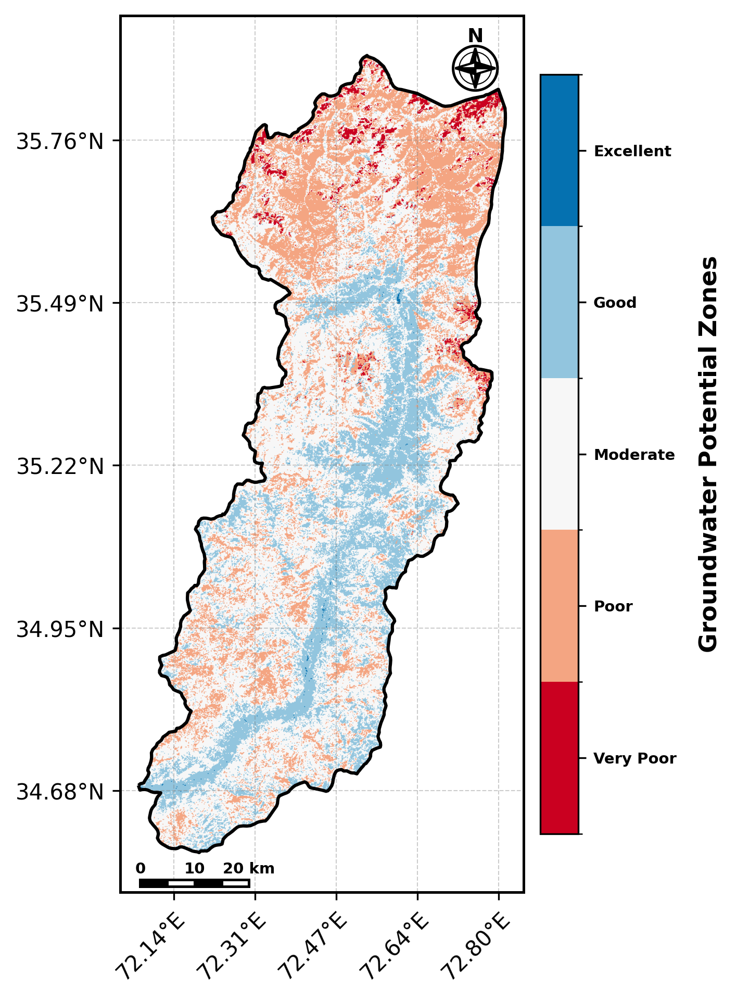

  💾 PNG: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/GWPZ_Final(01).png
  💾 PDF: /content/drive/MyDrive/Swat_Groundwater_Project/Thematic_Maps/GWPZ_Final(01).pdf

  CHARSADDA GWPZ — PARAMETER CLASSIFICATION TABLE

  Parameter              Class Range                  Class Rating    Ranking  Weight%
  ---------------------- ---------------------------- -------------- -------- --------
  Water Depth (ft)       10.0 – 58 ft                 Very High             5       10
                         58 – 94 ft                   High                  4         
                         94 – 123 ft                  Moderate              3         
                         123 – 182.0 ft               Low                   2         
                         182.0 – 238.0 ft             Very Low              1         
  ---------------------- ---------------------------- -------------- -------- --------
  NDVI                   -0.2879 – 0.018              Very Low          

In [ ]:
# ============================================================
# STEP 9: FINAL GWPZ (Standardized Cartography)
# ============================================================

import ee, os, json, requests, io
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from pyproj import Transformer
from PIL import Image as PILImage
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# TEAM STYLING & CARTOGRAPHY SETTINGS (Matches Thematic Maps Perfectly)
# ==============================================================================
FIG_SIZE_INCHES = 6.5
MAP_RESOLUTION_DPI = 300

TEAM_FONT = 'DejaVu Sans'
plt.rcParams['font.family'] = TEAM_FONT

TITLE_SIZE = 13
AXIS_LABEL_SIZE = 11
TICK_VALUE_SIZE = 11
LEGEND_SIZE = 7  # Updated
GRID_COLOR = 'gray'
GRID_ALPHA = 0.4
NORTH_ARROW_SCALE = 0.05  # Updated
SCALE_BAR_LENGTH_M = 20000  # Updated (20 km scale bar)

BASE_DIR  = "/content/drive/MyDrive/Swat_Groundwater_Project"
SCALE     = 30
MAPS_DIR  = os.path.join(BASE_DIR, "Thematic_Maps")
DATA_DIR  = os.path.join(BASE_DIR, "Data")
OUT_DIR   = os.path.join(BASE_DIR, "Outputs")
os.makedirs(MAPS_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

gdf      = gpd.read_file(os.path.join(BASE_DIR,"Shapefile","Swat.shp"))
gdf["geometry"] = gdf["geometry"].buffer(0)
gdf_4326 = gdf.to_crs("EPSG:4326")
gdf_utm  = gdf_4326.to_crs("EPSG:32643") # FORCE UTM FOR PERFECT MAP PROPORTIONS

roi      = ee.FeatureCollection(json.loads(gdf_4326.to_json())).geometry()
bounds   = gdf_4326.total_bounds
lon_range = bounds[2]-bounds[0]
lat_range = bounds[3]-bounds[1]

print("✅ Setup complete")

# ============================================================
# REBUILD ALL 12 PARAMETER IMAGES
# ============================================================
print("🔄 Rebuilding parameter images ...")

def mask_l9(img):
    qa = img.select("QA_PIXEL")
    cloud_mask   = qa.bitwiseAnd(1<<3).eq(0)   # Cloud
    shadow_mask  = qa.bitwiseAnd(1<<4).eq(0)   # Shadow
    snow_mask    = qa.bitwiseAnd(1<<5).eq(0)   # Snow — critical for Swat
    dilated_mask = qa.bitwiseAnd(1<<1).eq(0)   # Dilated cloud
    return img.updateMask(
        cloud_mask.And(shadow_mask).And(snow_mask).And(dilated_mask)
    )

def calib(img):
    opt = img.select(["SR_B2","SR_B3","SR_B4","SR_B5","SR_B6","SR_B7"])\
             .multiply(0.0000275).add(-0.2)
    thm = img.select("ST_B10").multiply(0.00341802).add(149.0).subtract(273.15)
    calibrated = img.addBands(opt,overwrite=True).addBands(thm,overwrite=True)
    # Validity check — prevents extreme values at high elevation
    valid_mask = (
        opt.select("SR_B4").gte(0.01).And(opt.select("SR_B4").lte(1.0))
        .And(opt.select("SR_B5").gte(0.01)).And(opt.select("SR_B5").lte(1.0))
        .And(opt.select("SR_B6").gte(0.01)).And(opt.select("SR_B6").lte(1.0))
    )
    return calibrated.updateMask(valid_mask)

comp = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(roi).filterDate("2025-09-01","2025-11-30")
        .filter(ee.Filter.lt("CLOUD_COVER",40))  # Relaxed for mountains
        .map(mask_l9).map(calib).median().clip(roi))

B3=comp.select("SR_B3"); B4=comp.select("SR_B4")
B5=comp.select("SR_B5"); B6=comp.select("SR_B6"); B7=comp.select("SR_B7")

NDVI = B5.subtract(B4).divide(B5.add(B4)).clamp(-1.0,1.0).rename("NDVI")
NDBI = B6.subtract(B5).divide(B6.add(B5)).clamp(-1.0,1.0).rename("NDBI")
MSI  = B6.divide(B5).clamp(0.0,5.0).rename("MSI")
WVWI = B3.subtract(B6).divide(B3.add(B6)).clamp(-1.0,1.0).rename("WVWI")
LST  = comp.select("ST_B10").clamp(-30.0,60.0).rename("LST")
dem   = ee.Image("USGS/SRTMGL1_003").clip(roi)
slope = ee.Terrain.slope(dem).rename("Slope")


# ── Road Distance — Nowshera (GEE Asset Method) ───────────────
# Asset: projects/ee-shakirlki313/assets/nowshera_roads_major
# Features: 20,832 major roads uploaded to GEE
# Distance range: 0 – 7784.8 m | Mean: 789.6 m
road_fc = ee.FeatureCollection(
    "projects/ee-shakirlki3132/assets/swat_roads_major"
)
road_raster = road_fc \
    .map(lambda f: f.set("val", 1)) \
    .reduceToImage(
        properties=["val"],
        reducer=ee.Reducer.first()
    ).unmask(0).gt(0).clip(roi)

road_dist = road_raster \
    .fastDistanceTransform(neighborhood=1024) \
    .sqrt().multiply(SCALE) \
    .rename("RoadDist").clip(roi)
print("   ✅ Road Distance loaded from GEE Asset (Swat)")

# ── River Distance — HydroSHEDS major rivers (FA≥5000) ───────
river_mask = ee.Image("WWF/HydroSHEDS/15ACC")\
               .select("b1").clip(roi).gte(5000)
river_dist = river_mask\
               .fastDistanceTransform(neighborhood=1024)\
               .sqrt().multiply(SCALE)\
               .rename("RiverDist_m").clip(roi)


precip = (ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
          .filterBounds(roi).filterDate("2025-01-01","2025-12-31")
          .select("total_precipitation_sum").sum()
          .multiply(1000).rename("Precip_mm")
          .resample("bilinear").reproject(crs="EPSG:4326",scale=SCALE)
          .clip(roi))

well_df = pd.read_csv(os.path.join(DATA_DIR,"Swat.csv"))\
           [["longitude","latitude","depth_m"]].dropna()
M_TO_FT = 3.28084
well_df["depth_ft"] = well_df["depth_m"] * M_TO_FT
well_fc = ee.FeatureCollection([
    ee.Feature(
        ee.Geometry.Point([r.longitude,r.latitude]),
               {"depth_ft":float(r.depth_ft)})
    for r in well_df.itertuples()
])
idw = well_fc.inverseDistance(50000,"depth_ft",
      well_df.depth_ft.mean(),well_df.depth_ft.std(),1)\
    .rename("WellDepth_ft").clip(roi)

lulc_raw = ee.ImageCollection("ESA/WorldCover/v200").first()\
             .select("Map").reproject(crs="EPSG:4326",scale=SCALE).clip(roi)

# ── Soil Type — Swat (CMI + Slope Proxy with snow masking) ───
def mask_l9_soil(image):
    qa = image.select("QA_PIXEL")
    return image.updateMask(
        qa.bitwiseAnd(1<<3).eq(0).And(qa.bitwiseAnd(1<<4).eq(0))
        .And(qa.bitwiseAnd(1<<5).eq(0)).And(qa.bitwiseAnd(1<<1).eq(0))
    )

def calibrate_soil(image):
    optical = image.select(["SR_B6","SR_B7"]).multiply(0.0000275).add(-0.2)
    valid_mask = (
        optical.select("SR_B6").gte(0.01).And(optical.select("SR_B6").lte(1.0))
        .And(optical.select("SR_B7").gte(0.01)).And(optical.select("SR_B7").lte(1.0))
    )
    return image.addBands(optical, overwrite=True).updateMask(valid_mask)

l9_soil = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
           .filterBounds(roi).filterDate("2022-01-01","2023-12-31")
           .filter(ee.Filter.lt("CLOUD_COVER", 20))
           .map(mask_l9_soil).map(calibrate_soil).median().clip(roi))

B6_soil = l9_soil.select("SR_B6")
B7_soil = l9_soil.select("SR_B7")
cmi     = B6_soil.divide(B7_soil).rename("CMI")

cmi_stats = cmi.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()
slope_stats = slope.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

cmi_n = cmi.subtract(cmi_stats["CMI_min"]) \
             .divide(cmi_stats["CMI_max"] - cmi_stats["CMI_min"])
slp_n = slope.subtract(slope_stats["Slope_min"]) \
             .divide(slope_stats["Slope_max"] - slope_stats["Slope_min"])
sp    = ee.Image(1).subtract(cmi_n) \
          .add(ee.Image(1).subtract(slp_n)) \
          .divide(2).rename("SoilProxy").clip(roi)
print("✅ All images built")

# ============================================================
# CLASSIFY ALL 12 PARAMETERS WITH FINALIZED CLASSES
# ============================================================
print("🔄 Classifying all 12 parameters ...")

def apply_classes(image, class_list):
    rated = ee.Image(0)
    for (lo, hi, rating) in class_list:
        rated = rated.where(
            image.gte(lo).And(image.lte(hi)), rating
        )
    return rated

# ── 1. NDVI — Paper Table 2 breaks ───────────────────────────
ndvi_cls = apply_classes(NDVI, [
    (-0.804,  0.163, 1),
    ( 0.163,  0.357, 2),
    ( 0.357,  0.480, 3),
    ( 0.480,  0.599, 4),
    ( 0.599,  0.884, 5),
]).rename("NDVI_cls").clip(roi)
print("  ✅ NDVI")

# ── 2. NDBI — Paper Table 2 breaks (inverted) ────────────────
ndbi_cls = apply_classes(NDBI, [
    (-0.984, -0.153, 5),
    (-0.153, -0.037, 4),
    (-0.037, 0.042, 3),
    (0.042,  0.093, 2),
    ( 0.093,  0.569, 1),
]).rename("NDBI_cls").clip(roi)
print("  ✅ NDBI")

# ── 3. MSI — Paper Table 2 breaks (inverted) ─────────────────
msi_cls = apply_classes(MSI, [
    (0.034, 0.734, 5),
    (0.734, 0.929, 4),
    (0.929, 1.087, 3),
    (1.087, 1.206, 2),
    (1.206, 3.6339, 1),
]).rename("MSI_cls").clip(roi)
print("  ✅ MSI")

# ── 4. WVWI — Paper Table 2 breaks ───────────────────────────
wvw_cls = apply_classes(WVWI, [
    (-0.742, -0.524, 1),
    (-0.524, -0.479, 2),
    (-0.479, -0.419, 3),
    (-0.419,  -0.312, 4),
    ( -0.312,  0.936, 5),
]).rename("WVWI_cls").clip(roi)
print("  ✅ WVWI")

# ── 5. LST — intervals (inverted) ──────────────────
lst_cls = apply_classes(LST, [
    (-17.395, 16.389, 5),
    (16.389, 19.950, 4),
    (19.950, 22.924, 3),
    (22.924, 30, 2),
    (30.00, 39.956, 1),
]).rename("LST_cls").clip(roi)
print("  ✅ LST")

# ── 6. SLOPE — Paper Table 2 breaks (inverted) ───────────────
slope_cls = apply_classes(slope, [
    ( 0.000,  2.471, 5),
    ( 2.472,  7.413, 4),
    ( 7.414, 13.796, 3),
    (13.797, 22.032, 2),
    (22.033, 81.965, 1),
]).rename("Slope_cls").clip(roi)
print("  ✅ Slope")


# (7)Nowshera road breaks from GEE Asset Step 4 output
# Min=0m  P20=83.1m  P40=304.0m  P60=656.9m  P80=1358.4m  Max=7784.8m
road_cls = apply_classes(road_dist, [
    (    0.0,    70, 1),   # Very Low  — within 83m of road
    (   70,   315.0, 2),   # Low
    (  315.0,   703, 3),   # Moderate
    (  703,  959, 4),   # High
    ( 959,  23551.9, 5),   # Very High — farthest from road
]).rename("RoadDist_cls").clip(roi)
print("  ✅ Road Distance")

# ── 8. RIVER DISTANCE — Percentile breaks from Step 4c ──────
river_cls = ee.Image(0)
river_cls = river_cls.where(river_dist.gte(   0).And(river_dist.lt( 150)), 5)
river_cls = river_cls.where(river_dist.gte( 150).And(river_dist.lt( 305)), 4)
river_cls = river_cls.where(river_dist.gte( 305).And(river_dist.lt( 627)), 3)
river_cls = river_cls.where(river_dist.gte( 627).And(river_dist.lt( 846)), 2)
river_cls = river_cls.where(river_dist.gte( 846),                          1)
river_cls = river_cls.rename("RiverDist_cls").clip(roi)
print("  ✅ River Distance")

# ── 9. PRECIPITATION — Equal interval ────────────────────────
prec_stats = precip.reduceRegion(
    ee.Reducer.minMax(), roi, SCALE, maxPixels=1e9
).getInfo()
p_min = prec_stats["Precip_mm_min"]
p_max = prec_stats["Precip_mm_max"]
p_step = (p_max - p_min) / 5
prec_breaks = [p_min + i*p_step for i in range(6)]

prec_cls = ee.Image(0)
for i in range(5):
    prec_cls = prec_cls.where(
        precip.gte(prec_breaks[i]).And(precip.lt(prec_breaks[i+1])), i+1
    )
prec_cls = prec_cls.where(precip.gte(prec_breaks[-1]), 5)
prec_cls = prec_cls.rename("Precip_cls").clip(roi)
print(f"  ✅ Precipitation [{p_min:.1f}–{p_max:.1f} mm/yr in 5 equal steps]")

# ── 10. WELL DEPTH — Data-driven percentile breaks ───────────
wdep_cls = ee.Image(0)
wdep_cls = wdep_cls.where(idw.gte(  6.0).And(idw.lt( 39)), 5)  # Very High
wdep_cls = wdep_cls.where(idw.gte( 39).And(idw.lt( 74)), 4)  # High
wdep_cls = wdep_cls.where(idw.gte( 74).And(idw.lt( 98)), 3)  # Moderate
wdep_cls = wdep_cls.where(idw.gte( 98).And(idw.lt(137)), 2)  # Low
wdep_cls = wdep_cls.where(idw.gte(137),                    1)  # Very Low
wdep_cls = wdep_cls.rename("WellDepth_cls").clip(roi)
print("  ✅ Well Depth")

# ── 11. LULC — Categorical ───────────────────────────────────
RECLASS = {80:5,90:5,10:4,95:4,40:3,20:2,30:2,60:2,100:2,50:1,70:1}
lulc_cls = ee.Image(0)
for code,r in RECLASS.items():
    lulc_cls = lulc_cls.where(lulc_raw.eq(code), r)
lulc_cls = lulc_cls.rename("LULC_cls").clip(roi)
print("  ✅ LULC")

# ── 12. SOIL TYPE — Quantile proxy ───────────────────────────
sv_fc = sp.sample(region=roi,scale=SCALE,numPixels=4000,
                  seed=42,tileScale=4,geometries=False)
sv    = sorted([f["properties"]["SoilProxy"]
                for f in sv_fc.getInfo()["features"]])
sbk   = [float(sv[0]),
         float(np.percentile(sv,20)),
         float(np.percentile(sv,40)),
         float(np.percentile(sv,60)),
         float(np.percentile(sv,80)),
         float(sv[-1])]
soil_cls = ee.Image(0)
for i in range(5):
    soil_cls = soil_cls.where(
        sp.gte(sbk[i]).And(sp.lt(sbk[i+1])), i+1
    )
soil_cls = soil_cls.where(sp.gte(sbk[-1]),5).rename("Soil_cls").clip(roi)
print(f"  ✅ Soil Type [breaks: {['%.3f'%b for b in sbk]}]")

print("\n✅ All 12 layers classified!")

# ============================================================
# AHP WEIGHTED OVERLAY
# ============================================================
AHP_WEIGHTS = {
    "LULC"        : 0.13,
    "WellDepth"   : 0.10,
    "NDBI"        : 0.10,
    "RoadDist"    : 0.10,
    "RiverDist"   : 0.13,
    "NDVI"        : 0.07,
    "MSI"         : 0.06,
    "Slope"       : 0.07,
    "WVWI"        : 0.07,
    "LST"         : 0.07,
    "Precip"      : 0.05,
    "SoilType"    : 0.05,
}

layer_map = {
    "LULC"        : lulc_cls,
    "WellDepth"   : wdep_cls,
    "NDBI"        : ndbi_cls,
    "RoadDist"    : road_cls,
    "RiverDist"   : river_cls,
    "NDVI"        : ndvi_cls,
    "MSI"         : msi_cls,
    "Slope"       : slope_cls,
    "WVWI"        : wvw_cls,
    "LST"         : lst_cls,
    "Precip"      : prec_cls,
    "SoilType"    : soil_cls,
}

gwpz = ee.Image(0)
for name, img in layer_map.items():
    w    = AHP_WEIGHTS[name]
    gwpz = gwpz.add(img.toFloat().multiply(w))
gwpz = gwpz.rename("GWPZ").clip(roi)

g_stats = gwpz.reduceRegion(
    ee.Reducer.minMax().combine(ee.Reducer.mean(),sharedInputs=True)
               .combine(ee.Reducer.stdDev(),sharedInputs=True),
    geometry=roi, scale=SCALE, maxPixels=1e9
).getInfo()

print(f"\n📊 GWPZ Score Statistics:")
print(f"   Min    : {g_stats['GWPZ_min']:.4f}")
print(f"   Max    : {g_stats['GWPZ_max']:.4f}")
print(f"   Mean   : {g_stats['GWPZ_mean']:.4f}")
print(f"   StdDev : {g_stats['GWPZ_stdDev']:.4f}")

# ── Manual zone breaks ──────────────────────────
zb = [
    1.006,   # Zone 1 start  (Very Poor)
    1.450,   # Zone 1 end / Zone 2 start  (Poor)
    2.500,   # Zone 2 end / Zone 3 start  (Moderate)
    3.200,   # Zone 3 end / Zone 4 start  (Good)
    4.000,   # Zone 4 end / Zone 5 start  (Excellent)
    4.500,   # Zone 5 end
]

gmin = g_stats["GWPZ_min"]
gmax = g_stats["GWPZ_max"]

gwpz_cls = ee.Image(0)
for i in range(5):
    gwpz_cls = gwpz_cls.where(
        gwpz.gte(zb[i]).And(gwpz.lt(zb[i+1])), i+1
    )
gwpz_cls = gwpz_cls.where(gwpz.gte(zb[-1]), 5)
gwpz_cls = gwpz_cls.rename("GWPZ_cls").clip(roi)

zone_names = {1:"Very Poor",2:"Poor",3:"Moderate",4:"Good",5:"Excellent"}
zone_areas = {}
total_zone = 0
for c in range(1,6):
    cnt  = gwpz_cls.eq(c).reduceRegion(
        ee.Reducer.sum(), roi, SCALE, maxPixels=1e9
    ).getInfo()["GWPZ_cls"]
    area = cnt * SCALE * SCALE / 1e6
    zone_areas[c] = area
    total_zone   += area

print(f"\n📐 GWPZ Zone Distribution:")
for c in range(1,6):
    pct = zone_areas[c]/total_zone*100
    bar = "█" * int(pct/2)
    print(f"   Zone {c} ({zone_names[c]:<12}): "
          f"{zone_areas[c]:6.1f} km²  ({pct:.1f}%)  {bar}")

# ============================================================
# EXPORT GEOTIFF
# ============================================================
task = ee.batch.Export.image.toDrive(
    image          = gwpz_cls.toInt(),
    description    = "Swat_GWPZ_Final",
    folder         = "Swat_Groundwater_Project/Outputs",
    fileNamePrefix = "GWPZ_Swat_30m",
    region=roi, scale=SCALE,
    crs="EPSG:4326", maxPixels=1e9
)
task.start()
print(f"\n☁️  GeoTIFF export started | Task: {task.id}")


# ==============================================================================
# TEAM CARTOGRAPHY HELPER FUNCTIONS
# ==============================================================================
def draw_compass_rose(ax, x, y, size):
    ax.add_patch(mpatches.Circle((x, y), size * 1.1, facecolor='white', edgecolor='black', linewidth=1.2, zorder=100))
    ax.add_patch(mpatches.Circle((x, y), size * 0.8, facecolor='none', edgecolor='black', linewidth=0.5, zorder=101))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y + size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y + size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x - size*0.3, y], [x, y - size]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x + size*0.3, y], [x, y - size]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x + size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x + size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y + size*0.3], [x - size, y]], facecolor='white', edgecolor='black', zorder=102))
    ax.add_patch(mpatches.Polygon([[x, y], [x, y - size*0.3], [x - size, y]], facecolor='black', edgecolor='black', zorder=102))
    ax.text(x, y + size * 1.08, 'N', ha='center', va='bottom', fontsize=LEGEND_SIZE+2, weight='bold', zorder=103) # Updated spacing

def draw_scale_bar(ax, x, y, total_length_meters):
    segments = 4
    seg_length = total_length_meters / segments
    height = total_length_meters * 0.06 # Updated thickness
    for i in range(segments):
        start_x = x + (i * seg_length)
        color = 'black' if i % 2 == 0 else 'white'
        ax.add_patch(mpatches.Rectangle((start_x, y), seg_length, height, linewidth=1.2, edgecolor='black', facecolor=color, zorder=100))
        if i % 2 == 0:
            label_val = int((i * seg_length) / 1000)
            ax.text(start_x, y + height * 1.5, str(label_val), ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)
    ax.text(x + total_length_meters, y + height * 1.5, f"{int(total_length_meters/1000)} km", ha='center', va='bottom', fontsize=LEGEND_SIZE, weight='bold', zorder=101)


# ============================================================
# FINAL GWPZ MAP (STANDARDIZED)
# ============================================================
print("\n🗺️  Generating Final GWPZ map ...")

gwpz_palette = ["#CA0020","#F4A582","#F7F7F7","#92C5DE","#0571B0"]

# Injecting your calculated areas into the standardized vertical colorbar labels
gwpz_labels = [
    "Very Poor",
    "Poor",
    "Moderate",
    "Good",
    "Excellent",
]

# FORCE EARTH ENGINE TO RENDER IN UTM 43N (Meters) FOR PERFECT PROPORTIONS
# 1. Get the exact bounding box in UTM from GeoPandas first
xmin, ymin, xmax, ymax = gdf_utm.total_bounds

# 2. Force Earth Engine to use this exact UTM bounding box
exact_utm_bounds = ee.Geometry.Rectangle(
    coords=[xmin, ymin, xmax, ymax],
    proj="EPSG:32643", # Updated
    evenOdd=False
)

# 3. Request the image using the perfectly matched region
url  = gwpz_cls.getThumbURL({
    "min":1, "max":5,
    "palette":gwpz_palette,
    "region":exact_utm_bounds, # Updated
    "dimensions":1024,
    "crs":"EPSG:32643", # Updated
    "format":"png"
})
resp = requests.get(url)
img  = PILImage.open(io.BytesIO(resp.content))

fig, ax = plt.subplots(figsize=(FIG_SIZE_INCHES, FIG_SIZE_INCHES), dpi=MAP_RESOLUTION_DPI)

# 1. 5% MARGIN & EXACT CAMERA LOCK
x_margin, y_margin = (xmax - xmin) * 0.05, (ymax - ymin) * 0.05 # Reverted to 0.05 for consistency
ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)
ax.set_aspect('equal')

# Plot Earth Engine Image & Boundary natively in UTM
ax.imshow(img, extent=[xmin, xmax, ymin, ymax])
gdf_utm.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=50)

# 2. STRICT AXIS INTERVALS & DEGREE TRANSLATION
ax.grid(True, color=GRID_COLOR, linestyle='--', linewidth=0.5, alpha=GRID_ALPHA, zorder=0)

ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5))
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=6))

transformer = Transformer.from_crs("EPSG:32643", "EPSG:4326", always_xy=True) # Updated
center_y, center_x = (ymin + ymax) / 2, (xmin + xmax) / 2

# Updated axis formatting and rotation
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{transformer.transform(x, center_y)[0]:.2f}°E"))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f"{transformer.transform(center_x, y)[1]:.2f}°N"))
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('black')



map_width = ax.get_xlim()[1] - ax.get_xlim()[0]
map_height = ax.get_ylim()[1] - ax.get_ylim()[0]

# Updated map element placement
draw_compass_rose(ax, ax.get_xlim()[0] + (map_width * 0.88), ax.get_ylim()[0] + (map_height * 0.94), size=map_width*NORTH_ARROW_SCALE)
draw_scale_bar(ax, ax.get_xlim()[0] + (map_width * 0.05), ax.get_ylim()[0] + (map_height * 0.007), total_length_meters=SCALE_BAR_LENGTH_M)

# 4. VERTICAL COLORBAR (Updated fraction, pad, and labelpad)
cmap = ListedColormap(gwpz_palette)
norm = BoundaryNorm(np.arange(0.5, 6.5, 1), cmap.N)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=ax, fraction=0.046, pad=0.02, ticks=[1, 2, 3, 4, 5])
cbar.ax.set_yticklabels(gwpz_labels, fontsize=LEGEND_SIZE, weight='bold') # Kept at LEGEND_SIZE for standardization
cbar.set_label("Groundwater Potential Zones", fontsize=AXIS_LABEL_SIZE, weight='bold', labelpad=10) # Updated

# Export
plt.tight_layout()
gwpz_fname = os.path.join(MAPS_DIR, "GWPZ_Final(01).png")
gwpz_pdf   = os.path.join(MAPS_DIR, "GWPZ_Final(01).pdf")

plt.savefig(gwpz_fname, dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor="white")
fig.savefig(gwpz_pdf,   dpi=MAP_RESOLUTION_DPI, bbox_inches="tight", facecolor="white")

plt.show()
print(f"  💾 PNG: {gwpz_fname}")
print(f"  💾 PDF: {gwpz_pdf}")

# ============================================================
# PARAMETER CLASSIFICATION TABLE
# ============================================================
print("\n" + "="*80)
print("  CHARSADDA GWPZ — PARAMETER CLASSIFICATION TABLE")
print("="*80)
print(f"\n  {'Parameter':<22} {'Class Range':<28} {'Class Rating':<14} "
      f"{'Ranking':>8} {'Weight%':>8}")
print(f"  {'-'*22} {'-'*28} {'-'*14} {'-'*8} {'-'*8}")

TABLE_DATA =[
    ("Water Depth (ft)", 10, [
    ("10.0 – 58 ft",          "Very High", 5),
    ("58 – 94 ft",         "High",      4),
    ("94 – 123 ft",         "Moderate",  3),
    ("123 – 182.0 ft",        "Low",       2),
    ("182.0 – 238.0 ft",       "Very Low",  1),
]),
    ("NDVI", 7, [
        ("-0.2879 – 0.018",         "Very Low",  1),
        ("0.019 – 0.090",          "Low",       2),
        ("0.091 – 0.280",          "Moderate",  3),
        ("0.281 – 0.420",          "High",      4),
        ("0.421 – 0.7694",          "Very High", 5),
    ]),
    ("MSI", 6, [
        ("0.3500 – 0.783",          "Very High", 5),
        ("0.784 – 0.910",          "High",      4),
        ("0.911 – 1.025",          "Moderate",  3),
        ("1.026 – 1.250",          "Low",       2),
        ("1.251 – 2.2842",          "Very Low",  1),
    ]),
    ("NDBI", 10, [
        ("-0.4814 – -0.141",        "Very High", 5),
        ("-0.140 – -0.072",        "High",      4),
        ("-0.071 – -0.006",        "Moderate",  3),
        ("-0.005 – 0.041",         "Low",       2),
        ("0.042 – 0.3910",          "Very Low",  1),
    ]),
    ("Slope (°)", 7, [
        ("0.000 – 2.471",          "Very High", 5),
        ("2.472 – 7.413",          "High",      4),
        ("7.414 – 13.796",         "Moderate",  3),
        ("13.797 – 22.032",        "Low",       2),
        ("22.033 – 71.100",        "Very Low",  1),
    ]),
    ("Rainfall (mm/yr)", 5, [
        (f"{prec_breaks[0]:.1f} – {prec_breaks[1]:.1f}", "Very Low",  1),
        (f"{prec_breaks[1]:.1f} – {prec_breaks[2]:.1f}", "Low",       2),
        (f"{prec_breaks[2]:.1f} – {prec_breaks[3]:.1f}", "Moderate",  3),
        (f"{prec_breaks[3]:.1f} – {prec_breaks[4]:.1f}", "High",      4),
        (f"{prec_breaks[4]:.1f} – {prec_breaks[5]:.1f}", "Very High", 5),
    ]),
    ("WVWI", 7, [
        ("-0.6040 – -0.166",        "Very Low",  1),
        ("-0.165 – -0.111",        "Low",       2),
        ("-0.110 – -0.064",        "Moderate",  3),
        ("-0.063 – 0.020",         "High",      4),
        ("0.021 – 0.5650",          "Very High", 5),
    ]),
    ("Land Cover (LULC)", 13, [
        ("Built-up",        "Very Low",  1),
        ("Bare / Grass / Shrub",   "Low",       2),
        ("Cropland",               "Moderate",  3),
        ("Tree Cover / Mangroves", "High",      4),
        ("Open Water / Wetland",   "Very High", 5),
    ]),
    ("LST (°C)", 7, [
        ("18 – 23.99",                "Very High", 5),
        ("24 – 28.99",                "High",      4),
        ("29 – 31.99",                "Moderate",  3),
        ("32 – 34.99",                "Low",       2),
        ("35 – 39.7953",                "Very Low",  1),
    ]),
    ("Road Distance (m)", 10, [
    ("0 – 146 m",             "Very Low",   1),
    ("146 – 396 m",         "Low",        2),
    ("396 – 720 m",        "Moderate",   3),
    ("720 – 1041 m",       "High",       4),
    ("1041 – 7784.8 m",      "Very High",  5),
]),
    ("River Distance (m)", 13, [                         # NEW
        ("0 – 176 m",              "Very High",  5),
        ("176 – 335 m",            "High",       4),
        ("335 – 690 m",            "Moderate",   3),
        ("690 – 878 m",            "Low",        2),
        ("878 – 7492 m",           "Very Low",   1),
    ]),
    ("Soil Type", 5, [
        ("Clay / Impermeable",     "Very Low",  1),
        ("Clay Loam",              "Low",       2),
        ("Silt Loam / Mixed",      "Moderate",  3),
        ("Loam / Sand",            "High",      4),
        ("Sandy Loam / Loamy Sand","Very High", 5),
    ]),
]

for (param, weight, classes) in TABLE_DATA:
    first = True
    for (range_str, rating, ranking) in classes:
        p_col = param       if first else ""
        w_col = str(weight) if first else ""
        print(f"  {p_col:<22} {range_str:<28} {rating:<14} "\
              f"{ranking:>8} {w_col:>8}")
        first = False
    print(f"  {'-'*22} {'-'*28} {'-'*14} {'-'*8} {'-'*8}")

print("="*80)

# ============================================================
# VERIFICATION BLOCK
# ============================================================
print("\n" + "="*65)
print("  STEP 9 — VERIFICATION BLOCK")
print("="*65)
print(f"  Parameters used    : 12")
print(f"  Weight sum         : {sum(AHP_WEIGHTS.values()):.2f}")
print(f"  GWPZ score range   : {g_stats['GWPZ_min']:.4f} – "\
      f"{g_stats['GWPZ_max']:.4f}")
print(f"  GWPZ mean          : {g_stats['GWPZ_mean']:.4f}")
print(f"  GWPZ std dev       : {g_stats['GWPZ_stdDev']:.4f}")
print(f"\n  Zone breaks        : {['%.3f'%b for b in zb]}")
print(f"\n  Zone areas:")
for c in range(1,6):
    pct = zone_areas[c]/total_zone*100
    print(f"    {zone_names[c]:<12}: "\
          f"{zone_areas[c]:6.1f} km²  ({pct:.1f}%)")
print(f"\n  GeoTIFF task ID    : {task.id}")
print(f"  Maps saved to      : {MAPS_DIR}")
print("="*65)
print("✅ Step 9 complete — Final GWPZ map generated!")